# From raw IMU numbers to position and rotation
### A complete, beginner-friendly guide to the multi-sensor adaptive-Kalman-filter pipeline

**Who this is for.** You do *not* need to know anything about sensor fusion, Kalman filters, rotation matrices
or Python. Every idea is introduced from zero, with an everyday picture first, then the formula, then the code.

**What the project does, in one sentence.** Four small motion sensors (IMUs) were fixed on the same object.
Each sensor gives noisy, slightly wrong numbers. The pipeline *cleans* each sensor's numbers, *lines the four
sensors up*, *merges them into one best answer*, and finally turns that answer into **where the object is and
how it is rotated, seen from the Earth** (plus animated GIFs of the motion).

---

### How to read this notebook (three levels, pick yours)

| If you want... | Read... |
|---|---|
| the big picture only | the **grey/blue explanation boxes** and the pictures; skip formulas and code |
| to understand *why* it works | also read the **formulas** — every symbol is defined right next to it |
| to understand *the program* | also read the **code cells**; every line has a plain-English `#` comment |

**Conventions.** A line starting with `#` in a code cell is a *comment*: the computer ignores it, it is there
only for you. Blocks like `🧠 Intuition` give the everyday picture; `📐 Formula` give the maths;
`💻 Code` introduce the program; `⚠️ Watch out` flag classic traps.

**Running it.** Execute the cells from top to bottom (`Run → Run All Cells`). Everything works on
*simulated* data that is created inside the notebook, so you need no files. At the very end there is an
optional section to run your real CSV.

## 0. The whole pipeline on one page

```
 CSV file  (4 IMUs: accelerometer + gyroscope numbers, one row per instant)
     │
     │ 1. convert units  (g → m/s²,  deg/s → rad/s)
     ▼
 ┌───────────────────────────────────────────────┐
 │ 2. ONE adaptive Kalman filter PER IMU          │   "clean this sensor's numbers"
 │    + backward smoother (RTS)                   │   → acceleration, rotation rate, biases, gravity
 └───────────────────────────────────────────────┘
     │
     │ 3. REGISTRATION: find how each IMU is mounted relative to IMU #1  (Wahba problem)
     ▼
     │ 4. CONSENSUS: merge the 4 gravity/rotation-rate estimates → one common body orientation
     ▼
     │ 5. EARTH FRAME: rotate everything from "sensor axes" into "Earth axes" (X,Y horizontal, Z up)
     ▼
     │ 6. FUSION: merge the 4 Earth-frame estimates with matrix-weighted averaging
     ▼
     │ 7. second smoother on the merged curve (optional, removes leftover jitter)
     ▼
     │ 8. INTEGRATE:  acceleration → velocity → position ;  rotation rate → orientation angle
     ▼
 plots (PNG), numbers (NPZ/CSV), and animated GIFs: each IMU versus the fused result
```

**Words you will meet** (a mini-glossary; there is a longer one at the end)

* **IMU** – *Inertial Measurement Unit*: a chip with an **accelerometer** and a **gyroscope**.
* **State** – the list of unknown numbers we want to know at each instant (e.g. the true acceleration).
* **Estimate** – our best guess of a state, given noisy data.
* **Covariance** – a table that says *how unsure* we are about the estimate (and how the uncertainties are linked).
* **Body frame** – directions attached to the sensor (it turns when the sensor turns).
* **Earth frame** – fixed directions: X, Y horizontal, **Z pointing up**. This is the *inertial* reference.

# Chapter 1 — What does an IMU measure?

### 🧠 Intuition
Imagine you are blindfolded inside a car.

* Your **inner ear for turning** tells you *how fast you are rotating* → this is the **gyroscope**.
* Your **sense of being pushed into the seat** tells you *how hard you are accelerating* → the **accelerometer**.

The accelerometer has a surprising feature: even when perfectly still you feel a push — **gravity**.
A still accelerometer does not read zero; it reads "1 g pointing up" (the floor pushes you up).
So the accelerometer mixes *two* things: the real movement **and** gravity. Separating them is half of our job.

### 📐 Formula — what the two sensors read

Let (all vectors written in the **body frame**, i.e. along the sensor's own axes):

| Symbol | Meaning | Units |
|---|---|---|
| $\mathbf a$ | *true* acceleration of the sensor (without gravity) | m/s² |
| $\boldsymbol\omega$ | *true* angular velocity (how fast it rotates) | rad/s |
| $\mathbf g$ | gravity vector (points **down**, length $G_0 = 9.80665$ m/s²) | m/s² |
| $\mathbf b_a,\ \mathbf b_\omega$ | **biases**: constant-ish offsets of each sensor | m/s², rad/s |
| $\mathbf v_a,\ \mathbf v_\omega$ | **noise**: random, different at every instant | m/s², rad/s |

$$
\underbrace{\mathbf z_\omega}_{\text{gyro reading}} = \boldsymbol\omega + \mathbf b_\omega + \mathbf v_\omega ,
\qquad
\underbrace{\mathbf z_a}_{\text{accelerometer reading}} = \mathbf a + \mathbf b_a - \mathbf g + \mathbf v_a .
$$

Why the **minus** sign in front of $\mathbf g$? Because an accelerometer measures the *push of the floor*,
which is opposite to the gravity vector. At rest, $\mathbf a = 0$ so the reading is $-\mathbf g$ (pointing up).

### Noise vs. bias — the two enemies
* **Noise** jitters up and down around the truth. Averaging many readings removes most of it.
* **Bias** is a constant (or slowly wandering) error. Averaging does **not** remove it — and worse, it
  *accumulates* when you integrate.

The next cell shows why this matters.

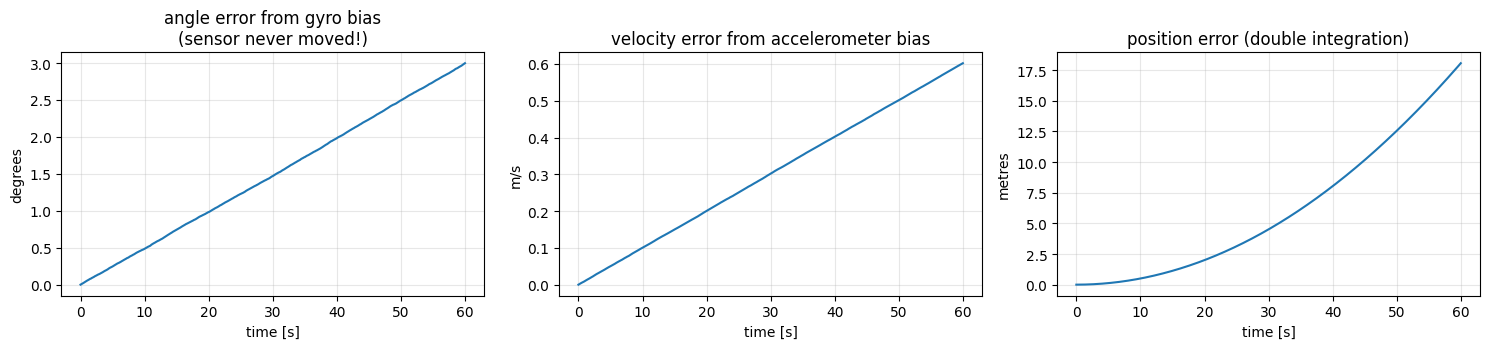

After 60 s of doing NOTHING:  angle error = 3.00 deg,  position error = 18.1 m
(theory: position error = 0.5 * bias * t^2 = 18.0 m)


In [1]:
# ---- Chapter 1 demo: why a tiny bias ruins a naive integration -------------------------
import numpy as np                      # numpy = the library for fast maths on arrays of numbers
import matplotlib.pyplot as plt         # matplotlib = the library that draws plots

rng = np.random.default_rng(0)          # a random-number generator (seed 0 => same numbers every run)
dt = 0.01                               # time between two samples: 0.01 s  (100 samples per second)
t = np.arange(0, 60, dt)                # time axis: 0, 0.01, 0.02, ... 59.99 seconds

# A sensor lying perfectly still: the TRUE rotation rate and the TRUE acceleration are both zero.
gyro_bias  = np.deg2rad(0.05)           # gyroscope bias: 0.05 degrees/second (a very good gyro!)
gyro_noise = np.deg2rad(0.03)           # gyroscope noise: 0.03 degrees/second (std. deviation)
acc_bias   = 0.01                       # accelerometer bias: 0.01 m/s^2 (about 1 milli-g)
acc_noise  = 0.003                      # accelerometer noise: 0.003 m/s^2

# What the sensor reports = truth (0) + bias + noise
gyro_reading = gyro_bias + gyro_noise * rng.standard_normal(len(t))
acc_reading  = acc_bias  + acc_noise  * rng.standard_normal(len(t))

# "Integrating" = adding up, step by step:  angle = sum(rate*dt),  speed = sum(acc*dt),  position = sum(speed*dt)
angle    = np.cumsum(gyro_reading) * dt
velocity = np.cumsum(acc_reading)  * dt
position = np.cumsum(velocity)     * dt

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(t, np.rad2deg(angle));  ax[0].set_title("angle error from gyro bias\n(sensor never moved!)")
ax[0].set_ylabel("degrees")
ax[1].plot(t, velocity);           ax[1].set_title("velocity error from accelerometer bias"); ax[1].set_ylabel("m/s")
ax[2].plot(t, position);           ax[2].set_title("position error (double integration)");    ax[2].set_ylabel("metres")
for a in ax: a.set_xlabel("time [s]"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"After 60 s of doing NOTHING:  angle error = {np.rad2deg(angle[-1]):.2f} deg,  "
      f"position error = {position[-1]:.1f} m")
print(f"(theory: position error = 0.5 * bias * t^2 = {0.5*acc_bias*60**2:.1f} m)")

### 🔑 What we learn
A bias of only 1 milli-g makes the *position* wrong by **18 m after one minute**, although nothing moved.
Double integration is brutal: the error grows like $\tfrac12\,b\,t^2$.
Therefore the whole pipeline has two goals:

1. **estimate the biases** (so we can subtract them), and
2. **use several sensors and smoothing** so the remaining errors are as small as possible.

The tool that does this is the **Kalman filter**. But first we need two more ingredients:
reference frames and rotations.

# Chapter 2 — Reference frames and rotations

### 🧠 Intuition: two ways of describing the same arrow
Hold a pencil. Tell a friend "it points to *my right*" — that is described in **your** frame
(it changes when you turn). Tell them "it points **north-east and slightly up**" — described in the
**Earth** frame (it does not change when you turn).

* **Body frame (B):** axes $x_B, y_B, z_B$ glued to the sensor. The sensor always reads its numbers here.
* **Earth frame (E):** axes $X, Y$ horizontal and $Z$ **up**. Fixed. The GIFs and final plots are drawn here.

A **rotation matrix** $R$ is a $3\times 3$ table of numbers that converts a vector written in the body frame
into the same vector written in the Earth frame:

$$
\mathbf v_E = R\,\mathbf v_B .
$$

Its inverse is simply the transpose: $\mathbf v_B = R^{\mathsf T}\mathbf v_E$.

### 📐 Formula — three tools used all over the code

**(a) The cross product as a matrix — the `skew` function.**
For a vector $\mathbf v=(v_1,v_2,v_3)$ define
$$
[\mathbf v]_\times=\begin{pmatrix}0&-v_3&v_2\\ v_3&0&-v_1\\ -v_2&v_1&0\end{pmatrix},
\qquad [\mathbf v]_\times\,\mathbf u=\mathbf v\times\mathbf u .
$$
This lets us write "cross product with $\mathbf v$" as an ordinary matrix multiplication, which matrices-based
filters need.

**(b) Rotation vector and the exponential map — `exp_so3`.**
A rotation can be described by a vector $\boldsymbol\phi$: its **direction** is the axis you rotate about,
its **length** is the angle (in radians). The matrix of that rotation is
$$
R=\operatorname{Exp}(\boldsymbol\phi)=\exp\!\big([\boldsymbol\phi]_\times\big)
= I+\frac{\sin\theta}{\theta}[\boldsymbol\phi]_\times+\frac{1-\cos\theta}{\theta^{2}}[\boldsymbol\phi]_\times^{2},
\quad\theta=\|\boldsymbol\phi\|.
$$

**(c) How gravity looks from a turning sensor.**
Gravity is fixed in the Earth, but the sensor rotates, so the *body-frame* gravity vector rotates the
opposite way:
$$
\dot{\mathbf g}_B=-\boldsymbol\omega_B\times\mathbf g_B=-[\boldsymbol\omega_B]_\times\,\mathbf g_B .
$$
This single equation is the **link between the gyroscope and the accelerometer**: the gyro tells how
the gravity direction must change, and the accelerometer measures that direction. The filter exploits it.

### ⚠️ Watch out — you cannot add rotation matrices
Adding two rotation matrices gives a matrix that is not a rotation. Rotations are *composed* by
multiplication, and a small turn is applied as $R_{k+1}=R_k\,\operatorname{Exp}(\boldsymbol\omega\,\Delta t)$.
That is why the code uses `exp_so3` instead of "$R+\dots$".

skew(v)@u   = [  6.5 -10.    4.5]
np.cross    = [  6.5 -10.    4.5]    <- identical

rotate (1,0,0) by 90 deg about Z -> [0. 1. 0.]


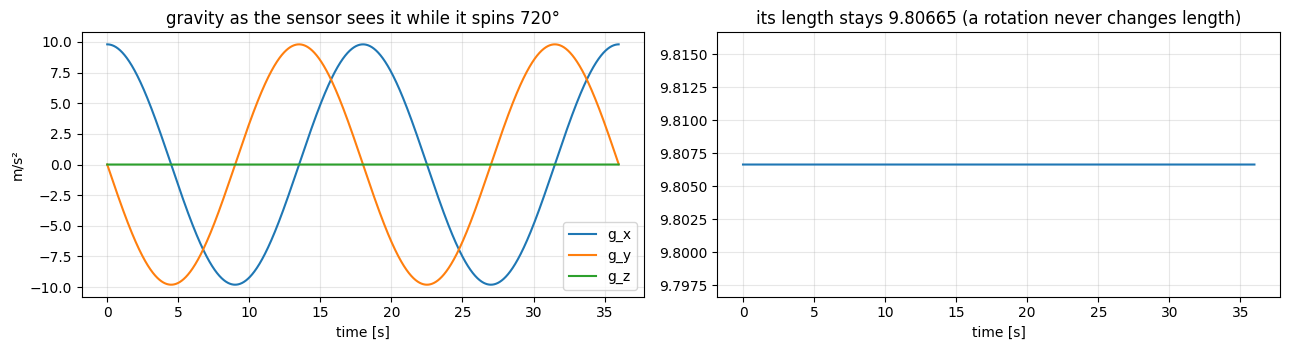

max difference step-by-step vs exact: 3.304023721284466e-13


In [2]:
# ---- Chapter 2 demo: skew matrix, rotation, and the gravity equation g_dot = -w x g --------
from scipy.spatial.transform import Rotation as Rot    # a ready-made, reliable rotation toolbox

def skew(v):
    # Build the 3x3 'cross-product matrix' of a 3-vector v (see formula (a) above).
    v = np.asarray(v, float)                  # make sure v is a numpy array of decimal numbers
    return np.array([[0.0,  -v[2],  v[1]],    # first row
                     [v[2],  0.0,  -v[0]],    # second row
                     [-v[1], v[0],  0.0]])    # third row

def exp_so3(phi):
    # Turn a rotation vector (axis * angle) into a 3x3 rotation matrix (formula (b)).
    return Rot.from_rotvec(np.asarray(phi, float)).as_matrix()

# 1) skew(v) @ u really is the cross product v x u
v, u = np.array([1., 2., 3.]), np.array([-2., 0.5, 4.])
print("skew(v)@u   =", skew(v) @ u)
print("np.cross    =", np.cross(v, u), "   <- identical")

# 2) Rotate the x-axis by 90 degrees about the vertical axis Z: it should become the y-axis
R = exp_so3([0, 0, np.deg2rad(90)])
print("\nrotate (1,0,0) by 90 deg about Z ->", np.round(R @ np.array([1., 0., 0.]), 6))

# 3) Gravity seen by a sensor that spins about its own z axis at 20 deg/s:
#    Earth gravity is (0,0,-G0).  We integrate g_dot = -w x g step by step and compare with
#    the exact answer  g_B(t) = R(t)^T g_E.
G0 = 9.80665
w_B = np.deg2rad([0, 0, 20.0])                     # constant body-frame rotation rate (rad/s)
g0_B = np.array([G0, 0.0, 0.0])                    # at t=0 gravity points along the body x axis
dt, T = 0.01, 36.0                                 # 36 s at 20 deg/s = 720 degrees = two full turns
tt = np.arange(0, T, dt)
g_num = np.empty((len(tt), 3)); g_num[0] = g0_B
for k in range(len(tt) - 1):
    g_num[k + 1] = exp_so3(-w_B * dt) @ g_num[k]   # rotate g backwards by w*dt each step
g_exact = np.array([exp_so3(-w_B * s) @ g0_B for s in tt])

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(tt, g_num[:, 0], label="g_x"); ax[0].plot(tt, g_num[:, 1], label="g_y"); ax[0].plot(tt, g_num[:, 2], label="g_z")
ax[0].set_title("gravity as the sensor sees it while it spins 720°"); ax[0].set_xlabel("time [s]"); ax[0].set_ylabel("m/s²")
ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(tt, np.linalg.norm(g_num, axis=1)); ax[1].set_ylim(G0 - 0.01, G0 + 0.01)
ax[1].set_title("its length stays 9.80665 (a rotation never changes length)"); ax[1].set_xlabel("time [s]"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("max difference step-by-step vs exact:", np.abs(g_num - g_exact).max())

### 🔑 What we learn
* While the sensor turns, the accelerometer's gravity reading **draws a circle** (two full turns here).
  That is exactly how the 720° test in your data looks: the gravity direction rotates through 720°.
* The **length** of $\mathbf g$ never changes. This is the physical fact behind the "gravity-modulus
  constraint" $\|\mathbf g\|=G_0$ that we impose later (Chapter 9).

# Chapter 3 — The Kalman filter, from scratch

### 🧠 Intuition: two imperfect witnesses
You want to know the temperature. You have

* a **forecast** ("prediction"): 20 °C, but forecasts can be off by ±2 °C;
* a **thermometer** (“measurement”): 23 °C, but it is noisy by ±1 °C.

Which do you trust? The **more precise** one — so you take a *weighted average*, weighing each witness by
**how reliable it is**. The result is both closer to the truth and **more certain** than either alone.
That is the entire idea of the Kalman filter, repeated at every time step:

> **1. Predict** what the world should look like now (using physics/known dynamics) → uncertainty grows.
> **2. Update** the prediction with the new measurement (weighted average) → uncertainty shrinks.

### 📐 Formula — the scalar (one-number) version

State estimate $\hat x$ with variance $P$ (variance = standard deviation squared = "how unsure"):

**Predict** (the true value drifts a little each step; $Q$ = variance added by that drift):
$$ \hat x^- = \hat x, \qquad P^- = P + Q . $$
**Update** with a measurement $z$ of variance $R$:
$$
K=\frac{P^-}{P^-+R}\ \ (\text{Kalman gain}),\qquad
\hat x=\hat x^-+K\,(z-\hat x^-),\qquad
P=(1-K)\,P^- .
$$
* $z-\hat x^-$ is the **innovation** ("surprise"): measurement minus prediction.
* $K$ is between 0 and 1. If the sensor is very noisy ($R$ large) then $K\approx0$: *ignore the measurement*.
  If the prediction is very uncertain ($P^-$ large) then $K\approx1$: *believe the measurement*.

### 📐 Formula — the full (vector) version used in this project
Now the state is a **vector** $\mathbf x$ (15 numbers) and the uncertainty is a **covariance matrix** $P$
($15\times15$; diagonal = variances, off-diagonal = "if this is wrong, that is probably wrong too").

$$
\begin{aligned}
&\textbf{Predict:} && \mathbf x^-=F\,\mathbf x,\qquad P^-=F\,P\,F^{\mathsf T}+Q\\[2pt]
&\textbf{Update:}  && S=H P^- H^{\mathsf T}+R,\qquad K=P^-H^{\mathsf T}S^{-1}\\
&                  && \mathbf x=\mathbf x^-+K\,\boldsymbol\nu,\quad \boldsymbol\nu=\mathbf z-h(\mathbf x^-),\qquad
                      P=(I-KH)\,P^-\,(I-KH)^{\mathsf T}+K R K^{\mathsf T}
\end{aligned}
$$
* $F$ — how the state evolves in one step; $Q$ — "process noise": how much the state is allowed to wander.
* $h(\mathbf x)$ — what the sensors *should* read for state $\mathbf x$; $H$ — its slope (Jacobian).
* $R$ — measurement noise; $S$ — total uncertainty of the innovation.
* The last form of $P$ is the **Joseph form**: mathematically equal to $(I-KH)P^-$ but numerically safer
  (it keeps $P$ a valid covariance despite rounding).

### Extended Kalman Filter (EKF)
If $h$ (or the dynamics) is *not* a straight line — here $\dot{\mathbf g}=-\boldsymbol\omega\times\mathbf g$
multiplies two unknowns — we replace it by its **tangent line** at the current estimate ($H$ = slope).
That is the "Extended" in EKF.

### Adaptive
$Q$ and $R$ are never perfectly known. An *adaptive* filter watches the innovations: if the surprises are
consistently bigger than expected, it increases the noise values; if smaller, it decreases them.

### Smoother (RTS)
The filter only uses the **past**. But the data *after* an instant also tell something about it.
The **Rauch–Tung–Striebel (RTS) smoother** runs *backward* after the filter and revises every estimate using
the future. When the model is right, a smoothed estimate is at least as accurate as the filtered one (we will see in Chapter 5 that, with an imperfect model, this is not guaranteed). We will use it twice.

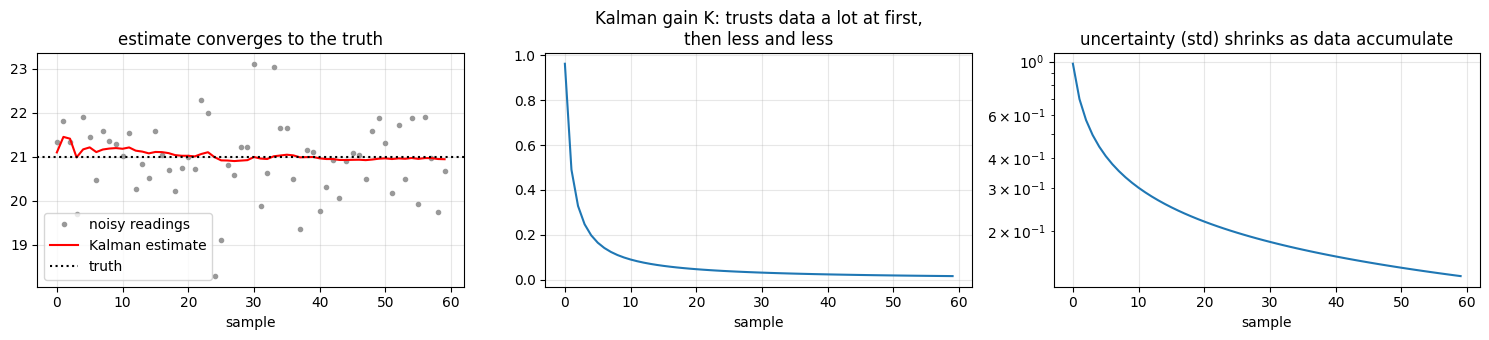

final estimate 20.95 C, +/- 0.13 C (plain average of data: 20.95)


In [3]:
# ---- Chapter 3 demo A: a scalar Kalman filter measuring a constant temperature ----------------
rng = np.random.default_rng(1)
true_T = 21.0                      # the real (unknown to the filter) temperature
R = 1.0 ** 2                       # thermometer noise variance (std 1 degree)
Q = 1e-5                           # the temperature is almost constant -> tiny process noise
n = 60
z = true_T + np.sqrt(R) * rng.standard_normal(n)      # the noisy thermometer readings

x_hat, P = 15.0, 5.0 ** 2          # a bad first guess (15 C) that we admit is very uncertain (std 5)
xs, Ps, Ks = [], [], []
for k in range(n):
    # PREDICT: the value is unchanged, but our uncertainty grows slightly
    P = P + Q
    # UPDATE: weighted average of prediction and measurement
    K = P / (P + R)                # Kalman gain: how much to trust the new measurement (0..1)
    x_hat = x_hat + K * (z[k] - x_hat)   # move toward the measurement by a fraction K
    P = (1 - K) * P                # uncertainty shrinks
    xs.append(x_hat); Ps.append(P); Ks.append(K)
xs, Ps, Ks = map(np.array, (xs, Ps, Ks))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].plot(z, ".", color="0.6", label="noisy readings"); ax[0].plot(xs, "r", label="Kalman estimate")
ax[0].axhline(true_T, color="k", ls=":", label="truth"); ax[0].legend(); ax[0].set_title("estimate converges to the truth")
ax[1].plot(Ks); ax[1].set_title("Kalman gain K: trusts data a lot at first,\nthen less and less")
ax[2].semilogy(np.sqrt(Ps)); ax[2].set_title("uncertainty (std) shrinks as data accumulate")
for a in ax: a.set_xlabel("sample"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"final estimate {xs[-1]:.2f} C, +/- {np.sqrt(Ps[-1]):.2f} C (plain average of data: {z.mean():.2f})")

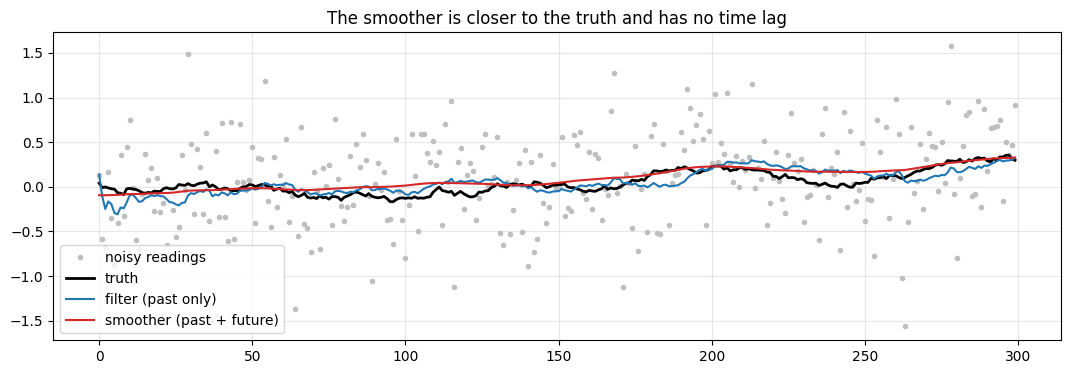

RMS error  raw data 0.488   filter 0.098   smoother 0.078


In [4]:
# ---- Chapter 3 demo B: Filter vs Smoother on a wandering quantity ----------------------------
# The true quantity does a random walk (it wanders); we only see noisy readings of it.
rng = np.random.default_rng(3)
n = 300
Q, R = 0.02 ** 2, 0.5 ** 2
truth = np.cumsum(np.sqrt(Q) * rng.standard_normal(n))     # random walk
z = truth + np.sqrt(R) * rng.standard_normal(n)            # noisy readings

# ---- forward pass = ordinary Kalman filter, remembering what the RTS smoother will need
xf = np.zeros(n); Pf = np.zeros(n)      # filtered estimate and variance (after the update)
xp = np.zeros(n); Pp = np.zeros(n)      # predicted estimate and variance (before the update)
x, P = z[0], R
for k in range(n):
    xp[k], Pp[k] = x, P + Q             # predict: same value, bigger uncertainty
    K = Pp[k] / (Pp[k] + R)             # gain
    x = xp[k] + K * (z[k] - xp[k])      # update
    P = (1 - K) * Pp[k]
    xf[k], Pf[k] = x, P

# ---- backward pass = RTS smoother: walk from the end back to the start
xs, Ps = xf.copy(), Pf.copy()
for k in range(n - 2, -1, -1):
    C = Pf[k] / Pp[k + 1]                          # smoother gain: how much the future informs the past
    xs[k] = xf[k] + C * (xs[k + 1] - xp[k + 1])    # correct with the future's "surprise"
    Ps[k] = Pf[k] + C * C * (Ps[k + 1] - Pp[k + 1])

plt.figure(figsize=(13, 4))
plt.plot(z, ".", color="0.75", label="noisy readings")
plt.plot(truth, "k", lw=2, label="truth")
plt.plot(xf, "tab:blue", label="filter (past only)")
plt.plot(xs, "tab:red", label="smoother (past + future)")
plt.legend(); plt.grid(alpha=0.3); plt.title("The smoother is closer to the truth and has no time lag"); plt.show()
rms = lambda e: np.sqrt(np.mean(e ** 2))
print(f"RMS error  raw data {rms(z-truth):.3f}   filter {rms(xf-truth):.3f}   smoother {rms(xs-truth):.3f}")

### 🔑 What we learn
* The filter is a **running weighted average** whose weights come from the uncertainties.
* The smoother removes the **lag** of the filter (the blue line trails behind) because it also looks ahead. (This demo has a perfect model; Chapter 5 shows what happens when the model is only approximate.)
* Everything in the project is a bigger version of exactly these two demos: more numbers per state,
  matrices instead of scalars, and physics (gravity + rotation) inside the "predict" step.

# Chapter 4 — Modelling one IMU: the 15 unknowns

We now describe, with equations, *everything the filter believes* about one sensor.

### 4.1 The state: 15 numbers that we want to know at every instant

$$
\mathbf x=\big[\;\underbrace{\mathbf a}_{3},\ \underbrace{\boldsymbol\omega}_{3},\ \underbrace{\mathbf b_a}_{3},\
\underbrace{\mathbf b_\omega}_{3},\ \underbrace{\mathbf g}_{3}\;\big]\in\mathbb R^{15}
$$

| Slice in the code | Symbol | Meaning | Units |
|---|---|---|---|
| `SL["a"]`  = 0:3   | $\mathbf a$ | **true** acceleration (gravity removed), in the body frame | m/s² |
| `SL["w"]`  = 3:6   | $\boldsymbol\omega$ | **true** rotation rate, body frame | rad/s |
| `SL["ba"]` = 6:9   | $\mathbf b_a$ | accelerometer bias | m/s² |
| `SL["bw"]` = 9:12  | $\mathbf b_\omega$ | gyroscope bias | rad/s |
| `SL["g"]`  = 12:15 | $\mathbf g$ | gravity vector, body frame | m/s² |

*Note what is missing:* there is **no orientation in the state**. The filter never tracks angles; it tracks the
*gravity direction* instead, which carries the tilt information. Orientation is rebuilt later (Chapter 7).

### 4.2 How the unknowns are allowed to change between two samples (the "predict" model)

| Quantity | Model | In plain words |
|---|---|---|
| $\mathbf a$ | $\mathbf a_{k+1}=e^{-\Delta t/\tau_a}\,\mathbf a_k+\text{jump}$ | acceleration fades to 0 unless data keep it alive (**Gauss–Markov**, $\tau_a=2$ s) |
| $\boldsymbol\omega$ | $\boldsymbol\omega_{k+1}=e^{-\Delta t/\tau_\omega}\,\boldsymbol\omega_k+\text{jump}$ | same for rotation rate ($\tau_\omega=2$ s) |
| $\mathbf b_a,\ \mathbf b_\omega$ | $\mathbf b_{k+1}=\mathbf b_k+\text{tiny noise}$ | biases are almost constant (**random walk**) |
| $\mathbf g$ | $\dot{\mathbf g}=-\boldsymbol\omega\times\mathbf g$ | gravity turns opposite to the sensor (Chapter 2) |

"Jump" means: a *random kick* each step, with a size we call the **process-noise standard deviation**.
If the kick is large the filter reacts quickly to changes; if small it is smooth but slow.

### 4.3 What the sensors should read (the "update" models)

$$
\mathbf z_\omega=\boldsymbol\omega+\mathbf b_\omega+\mathbf v_\omega,\qquad
\mathbf z_a=\mathbf a+\mathbf b_a-\mathbf g+\mathbf v_a,\qquad
\underbrace{\|\mathbf g\|=G_0}_{\text{extra "pseudo-measurement"}}
$$

The last line is not a sensor: it is a **known fact** (gravity has a fixed strength) that we feed to the
filter as if it were a measurement with a small noise $\sigma_{\|g\|}=0.05$ m/s². It helps the filter
separate gravity from acceleration.

### 4.4 The order of operations for each new sample (important!)

```
for every row k of the CSV:
    1. PREDICT      a, w fade slightly; uncertainty grows            (state a, w, biases)
    2. UPDATE GYRO  compare gyro reading with  w + bw                (fixes w and bw)
    3. GRAVITY STEP rotate g by the freshly corrected w:  g_dot = -w x g
    4. UPDATE ACC   compare accelerometer with  a + ba - g           (fixes a, ba, g)
                    plus the pseudo-measurement ||g|| = G0
    5. ADAPT        look at the recent "surprises" and re-tune the noise levels
```
Why gyro first? Because the gyro gives $\boldsymbol\omega$, and $\boldsymbol\omega$ is needed to move $\mathbf g$
forward correctly *before* we compare $\mathbf g$ with the accelerometer.

### 4.5 Process noise $Q$ in more detail
A kick in $\boldsymbol\omega$ also disturbs $\mathbf g$ (because $\dot{\mathbf g}=-\boldsymbol\omega\times\mathbf g$),
so the noises are **correlated**. The code builds
$$
Q = G\,\operatorname{diag}(\sigma_a^2,\sigma_\omega^2)\,G^{\mathsf T}+\operatorname{diag}(\text{random-walk variances}),
\quad
G=\begin{pmatrix} I & 0\\ 0& I\\ 0&\Delta t\,[\mathbf g]_\times\end{pmatrix}\text{(rows for a, w, g)} .
$$

### 4.6 Adaptive noise (how the filter re-tunes itself)
Let $\boldsymbol\nu$ be the innovations (surprises). Over a rolling window of the last 100 samples we measure their
average square $F=\overline{\nu^2}$. Surprises that are bigger than the filter expected mean "my noise
settings are too small". The code moves each standard deviation toward the level implied by $F$ with an
exponential moving average:
$$
\sigma_{\text{new}}=(1-d_k)\,\sigma_{\text{old}}+d_k\,\sigma_{\text{target}},\qquad d_k=\frac{1-b}{1-b^{k+1}},\ b=0.98 .
$$
**Safeguards for dynamic motion** (very important in this project): a real, fast rotation produces large
gyro innovations. A naive adaptive filter would conclude "the gyro is noisy!" and stop trusting it, making
$\boldsymbol\omega$ collapse to zero. Therefore (a) the gyro noise $R_\omega$ is **frozen**, (b) the bias
random walks are **frozen**, and (c) the rotation-rate process noise is kept between 0.5°/s and 5°/s.

### 4.7 The smoother in more detail ("extended RTS")
During the forward pass we store, for every sample $k$: the filtered state $\mathbf x_f(k)$ and covariance $P_f(k)$,
the prediction $\mathbf x_p(k),P_p(k)$ made just before the accelerometer update, and the combined step matrix
$\Phi(k)=F_3\,(I-K_gH_g)\,F_1$ (predict → gyro update → gravity step). Then, going **backward**:
$$
C_k=P_f(k)\,\Phi(k{+}1)^{\mathsf T}\,P_p(k{+}1)^{-1},\quad
\mathbf x_s(k)=\mathbf x_f(k)+C_k\big[\mathbf x_s(k{+}1)-\mathbf x_p(k{+}1)\big],\quad
P_s(k)=P_f(k)+C_k\big[P_s(k{+}1)-P_p(k{+}1)\big]C_k^{\mathsf T}.
$$
It is the scalar smoother of Chapter 3 with matrices.

### 4.8 Starting values from a stationary interval
At the beginning the sensor is **still** (hopefully). Then $\mathbf a=0$, $\boldsymbol\omega=0$ and
$\mathbf z_a=\mathbf b_a-\mathbf g$, $\mathbf z_\omega=\mathbf b_\omega$. So the average readings give:
gravity direction $=-$(mean accelerometer), gyro bias $=$ mean gyro, accelerometer bias $=$ whatever is left after
removing gravity of length $G_0$.

# Chapter 5 — The code: one adaptive EKF + smoother

### 💻 5.1 Imports and constants
First the "toolbox" (imports) and the fixed numbers the project uses. Read the comments: each constant is explained.

In [5]:
# ======================= imports: the tools we borrow from other people's code =======================
from __future__ import annotations           # (technical: lets us write type hints freely)
import argparse                              # reads options typed in the command line (used by main())
import re                                    # 're' = regular expressions: pattern matching in text (column names)
import warnings                              # lets the program print warnings
import sys, types                            # small system helpers (used once, to register the GIF code below)
from collections import deque                # 'deque' = a list that forgets its oldest items (rolling window)
from dataclasses import dataclass            # lets us define a settings container compactly
from pathlib import Path                     # file and folder paths that work on any computer
from typing import Dict, List, Optional, Sequence, Tuple   # only for documentation of what a function expects

import numpy as np                           # fast maths on arrays of numbers
import pandas as pd                          # reads tables (CSV files)
import matplotlib.pyplot as plt              # plotting
from scipy.spatial.transform import Rotation as Rot   # reliable 3-D rotation maths
from IPython.display import Image, display   # shows pictures / GIFs inside the notebook

plt.rcParams["figure.dpi"] = 100             # sharper plots in the notebook

# ======================= constants of the AEKF module (aekf_rts.py) =======================
I3 = np.eye(3)                               # the 3x3 identity matrix ("do nothing" matrix)
N_X = 15                                     # number of unknowns per sensor: a(3)+w(3)+ba(3)+bw(3)+g(3)

SL = {                                       # SL = "slices": which positions of the 15-vector belong to what
    "a":  slice(0, 3),                       # positions 0,1,2   -> true acceleration
    "w":  slice(3, 6),                       # positions 3,4,5   -> true angular velocity
    "ba": slice(6, 9),                       # positions 6,7,8   -> accelerometer bias
    "bw": slice(9, 12),                      # positions 9,10,11 -> gyroscope bias
    "g":  slice(12, 15),                     # positions 12,13,14-> gravity vector (body frame)
}
IU = {3: np.triu_indices(3)}                 # (unused helper index table kept from the original file)

# ======================= constants of the runner (run_general_multisensor_dynamic.py) =======================
G0 = 9.80665                                 # standard gravity [m/s^2]
DT_FALLBACK = 1.0 / 104.0                    # sample period used if nothing else is specified (104 Hz sensor)
DEFAULT_ALIGN_S = 10.0                       # length [s] of the initial 'sensor is still' interval used for start values
SECOND_RTS_DEFAULT = True                    # run the second smoother after the fusion?
SECOND_RTS_R_INFLATION = 10.0                # second smoother: trust the fused data 10x less (variance x10)
SECOND_RTS_Q_SCALE = 1.0                     # second smoother: how freely the curve may wiggle (x1 = as individual filters)
REGISTRATION_STRIDE = 5                      # registration uses every 5th sample (speed)
REGISTRATION_MIN_ACTIVE_DPS = 1.0            # a sample counts as 'moving' above 1 deg/s (diagnostic only)
EIG_FLOOR = 1e-10                            # smallest allowed 'eigenvalue' when inverting covariances (numerical safety)
R0_WINDOW_S = 5.0                            # seconds at the start used to measure the sensors' noise level

ACC_RE = re.compile(r"^(s\d+)_acc_([xyz]) \[mg\]$")    # pattern of accelerometer column names, e.g. 's1_acc_x [mg]'
GYR_RE = re.compile(r"^(s\d+)_gyro_([xyz]) \[dps\]$")  # pattern of gyroscope column names, e.g. 's2_gyro_z [dps]'

AXES = ("X", "Y", "Z")                       # axis names used in plots
COLORS = {"fused": "black", "fused_rts": "tab:purple", "gravity": "tab:cyan"}   # plot colours

QTY = {                                      # for each plotted quantity: (title, key, display scale, display unit)
    "a":   ("acceleration", "aE", 1e6, r"$\mu$m/s$^2$"),
    "w":   ("angular velocity", "wE", 1e3 * np.degrees(1.0), "mdps"),
    "ba":  ("accelerometer bias", "baE", 1e6, r"$\mu$m/s$^2$"),
    "bw":  ("gyroscope bias", "bwE", 1e3 * np.degrees(1.0), "mdps"),
    "g":   ("gravity vector", "gE", 1e6, r"$\mu$m/s$^2$"),
    "v":   ("velocity", "v", 1e3, "mm/s"),
    "p":   ("position", "p", 1e3, "mm"),
    "theta": ("angular position", "theta", 1e3 * np.degrees(1.0), "mdeg"),
}
print("constants defined; state has", N_X, "numbers per sensor")

constants defined; state has 15 numbers per sensor


### 💻 5.2 Two tiny helper functions

* `skew` — the cross-product matrix of Chapter 2.
* `rk4_phi` — computes "how much does a quantity rotate in one time step?" For $\dot{\mathbf g}=A\mathbf g$ the exact
  answer is the matrix exponential $e^{A\Delta t}$; `rk4_phi` approximates it with a polynomial of degree 4
  (the same formula used by the classical Runge–Kutta-4 integrator). For our tiny $\Delta t$ it is essentially exact.

In [6]:
def skew(v: np.ndarray) -> np.ndarray:
    """Return [v]_x such that [v]_x u = v x u."""
    # Make sure v is an array of decimal numbers.
    v = np.asarray(v, float)
    # Write the 3x3 table row by row (zeros on the diagonal, +/- components elsewhere).
    return np.array([
        [0.0,  -v[2],  v[1]],
        [v[2],  0.0, -v[0]],
        [-v[1], v[0],  0.0],
    ])

In [7]:
def rk4_phi(A: np.ndarray, dt: float) -> np.ndarray:
    """RK4 polynomial map for x_dot = A x with constant A over dt."""
    # n = size of the square matrix A (3 for gravity).
    n = A.shape[0]
    # M = A * dt : the 'amount of change' during one step.
    M = dt * A
    # Powers of M, needed for the polynomial: M^2 ...
    M2 = M @ M
    # exp(M) ~ I + M + M^2/2 + M^3/6 + M^4/24   (a truncated Taylor series; very accurate for small M).
    return (
        np.eye(n)
        + M
        + 0.5 * M2
        + (M2 @ M) / 6.0
        + (M2 @ M2) / 24.0
    )

### 💻 5.3 The settings container: `AEKFConfig`
A *dataclass* is just a labelled box of settings. Each line below declares one setting, its type, and a default value.
The lists with 15 entries are in the order `[a(3), w(3), ba(3), bw(3), g(3)]`.

In [8]:
@dataclass
    # SETTINGS BOX. Nothing is computed here: it only stores numbers that tune the filter.
    # std = standard deviation = typical size of an uncertainty.  Variance = std**2.
class AEKFConfig:
    dt: float
    G0: float = 9.80665

    # Gauss-Markov time constants for a and w.
    tau_a: float = 2.0
    tau_w: float = 2.0

    # Initial state/covariance scales, all length 15:
    # [a(3), w(3), ba(3), bw(3), g(3)].
    P0_std: Optional[np.ndarray] = None

    # Adaptive process-variance vector, length 15:
    # a,w = piecewise-white-noise jump stds;
    # ba,bw,g = random-walk stds.
    Q0_std: Optional[np.ndarray] = None

    # Measurement stds [acc xyz, gyro xyz].
    R0_std: Optional[np.ndarray] = None

    # Optional gravity-magnitude pseudo-measurement ||g|| = G0.
    # Set to 0 to disable it.
    sigma_gnorm: float = 0.05

    # Adaptive noise.
    enable_adaptive: bool = True
    window: int = 100
    b: float = 0.98
    min_eig_floor: float = 1e-12

    # Stationary floors for adaptive process / measurement stds.
    Q_min_std: Optional[np.ndarray] = None   # length 15
    R_min_std: Optional[np.ndarray] = None   # length 6

    # Selective adaptation.  In dynamic experiments the gyro residual contains
    # real angular motion, so adapting R_gyr directly from that residual can
    # create a positive-feedback failure: large motion -> large R_gyr -> small
    # K_w -> w stays near zero -> still-large innovation.  Keep gyro R fixed by
    # default for dynamic runs, while still allowing acceleration/R and a,w Q
    # adaptation.
    adapt_gyro_R: bool = True
    adapt_bias_process: bool = True

    # Guards for the angular-rate process model.  These are jump standard
    # deviations in rad/s.  The minimum prevents a too-small imported prior
    # from making w effectively deterministic at zero.
    min_w_jump_std: float = 0.0
    max_w_jump_std: Optional[float] = None

### 💻 5.4 The filter itself: class `AEKFRTS`
A *class* is a bundle of memory + actions. Here the memory is the current estimate `self.x`, its uncertainty
`self.P`, the noise levels, and the stored history; the actions are the methods (`step`, `smooth`, ...).
Read the class from top to bottom: it follows exactly the list of Section 4.4.

| Method | Job |
|---|---|
| `__init__` | store settings, set the first guess and the first uncertainty |
| `build_Q` | construct the process-noise matrix $Q$ (Section 4.5) |
| `step` | process **one** sample: predict → gyro → gravity → accelerometer → adapt |
| `run` | loop `step` over all samples, then call `smooth` |
| `_predict`, `_update_gyro`, `_propagate_gravity`, `_update_acc` | the four physical sub-steps |
| `_correct` | the generic Kalman-update formulas (Chapter 3) |
| `_adapt` | adaptive noise (Section 4.6) |
| `smooth`, `_psd_inverse` | the backward RTS pass (Section 4.7) |
| `stationary_initial_state` | start values from a still interval (Section 4.8) |
| `_R_from_gravity`, `reconstruct_navigation` | an older single-IMU post-processor (kept for completeness; the multi-sensor runner does not call it) |

A leading underscore (`_predict`) is only a naming habit meaning "internal helper".

In [9]:
class AEKFRTS:
    """15-state adaptive EKF with an extended RTS smoother."""

    def __init__(self, cfg: AEKFConfig, x0: np.ndarray):
        # Remember the settings (time step, noise levels, ...).
        self.cfg = cfg
        # self.x = our CURRENT best guess of the 15 unknowns (a copy, so we never change the caller's array).
        self.x = np.asarray(x0, float).copy()

        # Safety check: the state must contain exactly 15 numbers.
        if self.x.shape != (N_X,):
            raise ValueError(f"x0 must have shape ({N_X},), got {self.x.shape}")

        # Initial gravity is allowed to be slightly off-norm, but normalize
        # it when nonzero because gravity magnitude is known.
        # Gravity's strength is known (G0). If the first guess has another length, rescale it to G0.
        gnorm = np.linalg.norm(self.x[SL["g"]])
        if gnorm > 0:
            self.x[SL["g"]] *= cfg.G0 / gnorm

        # P = covariance matrix (15x15) = how unsure we are. Start with a diagonal: no links between states yet.
        # (std squared = variance.)
        self.P = np.diag(self._check_vec(cfg.P0_std, N_X, "P0_std") ** 2)

        # q = process-noise variances: how much each state may wander during one step.
        q0_std = self._check_vec(cfg.Q0_std, N_X, "Q0_std")
        self.q = q0_std ** 2
        # Never let the rotation-rate wander-allowance fall below a minimum,
        # otherwise the filter would believe the rotation rate is frozen at zero.
        if cfg.min_w_jump_std > 0.0:
            self.q[SL["w"]] = np.maximum(
                self.q[SL["w"]], cfg.min_w_jump_std ** 2
            )

        # R = measurement noise variances: first 3 for the accelerometer, last 3 for the gyroscope.
        R0 = self._check_vec(cfg.R0_std, 6, "R0_std")
        self.R_acc = R0[0:3].copy() ** 2
        self.R_gyr = R0[3:6].copy() ** 2

        # Lower limits ('floors') so the adaptive noise can never shrink all the way to zero.
        qmin = (
            np.zeros(N_X)
            if cfg.Q_min_std is None
            else self._check_vec(cfg.Q_min_std, N_X, "Q_min_std")
        )
        rmin = (
            np.zeros(6)
            if cfg.R_min_std is None
            else self._check_vec(cfg.R_min_std, 6, "R_min_std")
        )

        # Floors are scaled by (1-b), the steady-state weight of the adaptation formula (Section 4.6).
        d_inf = 1.0 - cfg.b
        self.Q_min_sq = qmin * d_inf
        self.R_min_sq = rmin * d_inf

        # Gauss-Markov decay factors: every step a and w are multiplied by exp(-dt/tau) < 1 (they slowly fade).
        self.fa = np.exp(-cfg.dt / cfg.tau_a)
        self.fw = np.exp(-cfg.dt / cfg.tau_w)

        # Gravity as seen from the Earth: straight down.
        self.g_earth = np.array([0.0, 0.0, -cfg.G0])

        # Rolling memories of the last `window` innovations (the 'surprises') used to adapt the noise.
        self.hist_g = deque(maxlen=cfg.window)
        self.hist_a = deque(maxlen=cfg.window)
        self.step_i = 0

        # Arrays populated by step(..., record=True).
        # Empty lists that will store the whole forward-pass history for the smoother:
        # xf,Pf = after update; xp,Pp = prediction; Phi = step map; qhist = noise levels.
        self._xf = []
        self._Pf = []
        self._xp = []
        self._Pp = []
        self._Phi = []
        self._qhist = []

        # One-step linearization objects used by the composite transition.
        # Placeholders for the one-step linear maps (Jacobians) from which Phi is assembled.
        self._F1 = np.eye(N_X)
        self._IKH1 = np.eye(N_X)
        self._F3 = np.eye(N_X)

    # ------------------------------------------------------------------ utils
    @staticmethod
    # (helper) Validate that a settings vector has the right length.
    def _check_vec(v, n, name):
        if v is None:
            raise ValueError(f"{name} must be supplied")
        a = np.asarray(v, float)
        if a.shape != (n,):
            raise ValueError(f"{name} must have shape ({n},), got {a.shape}")
        return a

    # (helper) Current adaptive noise standard deviations.
    def sigmas(self) -> np.ndarray:
        """Current adaptive stds [s_a(3), s_w(3), s_ba(3), s_bw(3), s_g(3)]."""
        return np.sqrt(np.maximum(self.q, 0.0))

    # (helper) Empty the history lists before a new run.
    def reset_recording(self):
        self._xf.clear()
        self._Pf.clear()
        self._xp.clear()
        self._Pp.clear()
        self._Phi.clear()
        self._qhist.clear()

    # ------------------------------------------------------------ process Q
    def build_Q(self) -> np.ndarray:
        """Closed-form PWN-style process covariance.

        The a/w jump noises also drive the body-frame gravity through
            g_dot = -w x g
        so the same angular-rate jump is correlated with g.
        """
        # Time step and current gravity estimate are needed to build Q.
        dt = self.cfg.dt
        g = self.x[SL["g"]]

        # G tells how the 6 random 'jumps' (3 in a, 3 in w) enter the 15 states.
        G = np.zeros((N_X, 6))

        # Acceleration jump.
        # An acceleration jump changes a directly.
        G[SL["a"], 0:3] = I3

        # Angular-rate jump.
        # A rotation-rate jump changes w directly...
        G[SL["w"], 3:6] = I3

        # First-order effect of angular-rate jump on gravity over dt.
        # ...and, over one step, also changes gravity because g_dot = -w x g (first-order effect).
        G[SL["g"], 3:6] = dt * skew(g)

        # Variances of the jumps (a first, then w).
        s2 = np.concatenate([
            self.q[SL["a"]],
            self.q[SL["w"]],
        ])

        # Q = G diag(s2) G^T : the standard recipe to turn input noise into a state covariance.
        Q = (G * s2) @ G.T

        # Independent random walks for biases and gravity-model mismatch.
        # Biases and gravity-mismatch are independent random walks: add their variances on the diagonal.
        rw_idx = np.r_[6:15]
        Q[rw_idx, rw_idx] += self.q[rw_idx]

        # Force exact symmetry (removes tiny rounding asymmetries).
        return 0.5 * (Q + Q.T)

    # --------------------------------------------------------------- EKF step
    def step(self, acc: np.ndarray, gyro: np.ndarray, record: bool = True):
        """Process one IMU sample.

        Returns:
            x_f, P_f
        """
        # Make sure the two readings are 3-number arrays.
        acc = np.asarray(acc, float).reshape(3)
        gyro = np.asarray(gyro, float).reshape(3)

        # 1) predict a,w, biases + process Q
        # 1) PREDICT: a and w fade a little, the uncertainty grows.
        self._predict()

        # 2) gyro update
        # 2) UPDATE WITH THE GYRO: compare what it read with w + bw; fixes w and bw.
        nu_g, K_g = self._update_gyro(gyro)

        # 3) propagate gravity using updated w
        # 3) GRAVITY STEP: rotate g forward using the freshly corrected w  (g_dot = -w x g).
        self._propagate_gravity()

        # Store what the smoother will need: the combined step map Phi and the prediction made
        # just before the accelerometer update.
        if record:
            # Composite linearized map from posterior(k-1) to the
            # pre-accelerometer state of sample k.
            self._Phi.append(self._F3 @ self._IKH1 @ self._F1)
            self._xp.append(self.x.copy())
            self._Pp.append(self.P.copy())

        # 4) accelerometer + optional gravity-norm update
        # 4) UPDATE WITH THE ACCELEROMETER (and the hint |g| = G0): fixes a, ba and g.
        nu_a, K_a = self._update_acc(acc)

        # 5) adaptive noise update
        # 5) ADAPT: re-tune the noise levels from the recent surprises (Section 4.6).
        self._adapt(nu_g, K_g, nu_a, K_a)

        # Count processed samples.
        self.step_i += 1

        # Store the final (filtered) result of this sample.
        if record:
            self._xf.append(self.x.copy())
            self._Pf.append(self.P.copy())
            self._qhist.append(self.q.copy())

        return self.x.copy(), self.P.copy()

    def run(self, acc: np.ndarray, gyro: np.ndarray, do_smooth: bool = True):
        """Run the full sequence and optionally RTS-smooth it."""
        acc = np.asarray(acc, float)
        gyro = np.asarray(gyro, float)
        # Check the input arrays: N rows, 3 columns, same shape for acc and gyro.
        if acc.ndim != 2 or acc.shape[1] != 3:
            raise ValueError("acc must have shape (N,3)")
        if gyro.shape != acc.shape:
            raise ValueError("gyro must have the same shape as acc")

        # Start with an empty history.
        self.reset_recording()

        # FORWARD PASS: process the samples one after the other, in time order.
        for k in range(len(acc)):
            self.step(acc[k], gyro[k], record=True)

        # Collect the forward results: states (xf), covariances (Pf), process-noise history (qhist).
        out = {
            "xf": np.asarray(self._xf),
            "Pf": np.asarray(self._Pf),
            "qhist": np.asarray(self._qhist),
        }

        # BACKWARD PASS: the RTS smoother improves every estimate using the future data too.
        if do_smooth:
            xs, Ps = self.smooth()
            out["xs"] = xs
            out["Ps"] = Ps

        return out

    # --------------------------------------------------------------- predict
    def _predict(self):
        x = self.x
        # Diagonal of the step matrix F: most states stay as they are (factor 1)...
        f = np.ones(N_X)
        # ...but a and w fade by their decay factors.
        f[SL["a"]] = self.fa
        f[SL["w"]] = self.fw

        # F = diagonal matrix built from f.
        F = np.diag(f)
        # Remember F: the smoother needs it.
        self._F1 = F

        # Process-noise matrix for this step (Section 4.5).
        Q = self.build_Q()

        # Move the estimate: a and w shrink slightly toward zero.
        x[SL["a"]] *= self.fa
        x[SL["w"]] *= self.fw

        # Uncertainty after prediction:  P- = F P F^T + Q   (it grows).
        self.P = F @ self.P @ F.T + Q
        # Keep P exactly symmetric.
        self.P = 0.5 * (self.P + self.P.T)

    # -------------------------------------------------------- generic update
    def _correct(self, nu: np.ndarray, H: np.ndarray, Rdiag: np.ndarray):
        # Intermediate product P H^T (used twice).
        PHt = self.P @ H.T
        # S = H P H^T : the uncertainty of the innovation before adding the sensor noise...
        S = H @ PHt
        # (symmetrise)
        S = 0.5 * (S + S.T)
        # ...now add the measurement noise R on the diagonal:  S = H P H^T + R.
        S[np.diag_indices_from(S)] += Rdiag

        # Solve S K^T = H P rather than explicitly inverting S.
        # Kalman gain K = P H^T S^-1, computed by SOLVING an equation (more accurate than inverting S).
        K = np.linalg.solve(S, PHt.T).T

        # Correct the state:  x <- x + K * innovation.
        self.x += K @ nu

        # Joseph form keeps P positive semidefinite better than
        # P <- (I-KH)P alone.
        # Joseph form of the covariance update: P = (I-KH) P (I-KH)^T + K R K^T.
        # Same result as (I-KH)P in theory, but it can never produce an invalid covariance through rounding.
        I_KH = np.eye(N_X) - K @ H
        # New (smaller) uncertainty.
        self.P = I_KH @ self.P @ I_KH.T + (K * Rdiag) @ K.T
        # Keep P symmetric.
        self.P = 0.5 * (self.P + self.P.T)

        # Give the gain back (needed by the adaptation step).
        return K

    # ------------------------------------------------------------- gyro meas
    def _update_gyro(self, gyro: np.ndarray):
        x = self.x

        # Innovation = (what the gyro READ) minus (what it SHOULD read: w + bw).
        nu = gyro - (x[SL["w"]] + x[SL["bw"]])

        # H = the slopes of the prediction: the gyro depends on w and bw, each with weight 1.
        H = np.zeros((3, N_X))
        H[:, SL["w"]] = I3
        H[:, SL["bw"]] = I3

        # Apply the generic Kalman update with the gyro noise.
        K = self._correct(nu, H, self.R_gyr)

        # Remember (I - K H) for the smoother's step matrix.
        self._IKH1 = np.eye(N_X) - K @ H
        return nu, K

    # -------------------------------------------------------- gravity dyn
    def _propagate_gravity(self):
        """Propagate g_{k+1} = Exp(-[w]x dt) g_k using RK4 polynomial."""
        # Time step, current rotation rate w and gravity g.
        dt = self.cfg.dt
        x = self.x

        w = x[SL["w"]]
        g = x[SL["g"]]

        # Gravity law g_dot = A g  with  A = -[w]x.
        A = -skew(w)
        # Phi_g = how gravity gets rotated during one step  (~ exp(A dt)).
        Phi_g = rk4_phi(A, dt)

        # F = linearised step map of this sub-step (the 'tangent line' of the EKF): identity except for the g rows.
        F = np.eye(N_X)
        # g_new depends on g_old through Phi_g.
        F[SL["g"], SL["g"]] = Phi_g

        # d/dw_j of g^+ through the same second-order expansion used
        # in the lean quaternion/gravity implementation.
        # g_new also depends on w (a wrong w turns g wrongly): derivative with respect to each component of w.
        for j in range(3):
            e = np.zeros(3)
            e[j] = 1.0
            Aj = -skew(e)

            F[SL["g"], 3 + j] = (
                dt * (Aj @ g)
                + 0.5 * dt * dt * (A @ (Aj @ g) + Aj @ (A @ g))
            )

        # Remember F for the smoother.
        self._F3 = F

        # Move the gravity estimate.
        x[SL["g"]] = Phi_g @ g

        # Propagate the uncertainty through the map (no extra noise in this sub-step).
        self.P = F @ self.P @ F.T
        self.P = 0.5 * (self.P + self.P.T)

    # ------------------------------------------------------------- acc meas
    def _update_acc(self, acc: np.ndarray):
        x = self.x

        # Current estimates of a, ba, g.
        a = x[SL["a"]]
        ba = x[SL["ba"]]
        g = x[SL["g"]]

        # Main accelerometer measurement:
        #   acc = a + ba - g + v_a
        # What the accelerometer SHOULD read:  a + ba - g.
        h = [a + ba - g]
        H_rows = []

        # Slopes: reading changes +1 per unit of a, +1 per unit of ba, -1 per unit of g.
        H0 = np.zeros((3, N_X))
        H0[:, SL["a"]] = I3
        H0[:, SL["ba"]] = I3
        H0[:, SL["g"]] = -I3
        H_rows.append(H0)

        # Optional known gravity magnitude ||g|| = G0.
        # This replaces the old quaternion-norm / gravity-attitude constraints.
        # Extra 'pseudo-measurement': we KNOW |g| = G0. Add it as a 4th measurement with small noise sigma_gnorm.
        if self.cfg.sigma_gnorm > 0.0:
            gn = np.linalg.norm(g)
            if gn < 1e-12:
                # Degenerate only if initialization is pathological.
                h_g = self.cfg.G0
                Hg = np.zeros((1, N_X))
            else:
                h_g = gn
                Hg = np.zeros((1, N_X))
                Hg[0, SL["g"]] = g / gn

            h.append(np.array([h_g]))
            H_rows.append(Hg)

        # Stack the 3 accelerometer predictions (+ the |g| prediction) into one list.
        h = np.concatenate(h)
        H = np.vstack(H_rows)

        # Stack what was actually 'measured': the 3 accelerometer readings (+ the number G0).
        z = np.zeros_like(h)
        z[0:3] = acc
        if self.cfg.sigma_gnorm > 0.0:
            z[3] = self.cfg.G0

        # Innovations: measured minus predicted.
        nu = z - h

        # Noise variance of each measurement.
        Rdiag = (
            np.concatenate([
                self.R_acc,
                [self.cfg.sigma_gnorm ** 2],
            ])
            if self.cfg.sigma_gnorm > 0.0
            else self.R_acc.copy()
        )

        # Apply the generic Kalman update.
        K = self._correct(nu, H, Rdiag)
        return nu, K

    # ------------------------------------------------------------- adaptive
    def _adapt(
        self,
        nu_g: np.ndarray,
        K_g: np.ndarray,
        nu_a: np.ndarray,
        K_a: np.ndarray,
    ):
        # Shortcut to the settings.
        cfg = self.cfg
        # If adaptation is switched off, keep the noise levels fixed.
        if not cfg.enable_adaptive:
            return

        # Only the physical 3-axis measurement residuals participate in
        # adaptive R; the gravity magnitude pseudo-measurement stays fixed.
        # Use only the 3 real accelerometer innovations (not the artificial |g| one).
        nu_a_phys = nu_a[:3]
        K_a_phys = K_a[:, :3]

        # Put the newest innovations into the rolling windows.
        self.hist_g.append(nu_g)
        self.hist_a.append(nu_a_phys)

        # Fg, Fa = average SQUARED innovation over the window = how big the recent surprises were.
        Fg = np.mean(np.square(np.asarray(self.hist_g)), axis=0)
        Fa = np.mean(np.square(np.asarray(self.hist_a)), axis=0)

        # Weight of the new information in the moving average (small once enough data are available).
        d_k = (1.0 - cfg.b) / max(
            1.0 - cfg.b ** (self.step_i + 1),
            cfg.min_eig_floor,
        )

        # Process-noise level implied by the surprises:  K F K^T  (gain^2 x surprise power).
        temp = (
            np.einsum("ij,j,ij->i", K_g, Fg, K_g)
            + np.einsum("ij,j,ij->i", K_a_phys, Fa, K_a_phys)
        )

        # Current and target noise standard deviations.
        old_q_std = np.sqrt(np.maximum(self.q, 0.0))
        target_q_std = np.sqrt(np.maximum(temp, 0.0))
        new_q_std = old_q_std.copy()

        # The physical fast states are a and w.  Bias random walks must not be
        # allowed to learn the deterministic dynamic motion.
        # Only a and w ('fast' states) are allowed to adapt their process noise.
        fast_idx = np.r_[np.arange(SL["a"].start, SL["a"].stop),
                         np.arange(SL["w"].start, SL["w"].stop)]
        # Exponential moving average:  new = (1-d) * old + d * target.
        new_q_std[fast_idx] = (
            (1.0 - d_k) * old_q_std[fast_idx]
            + d_k * target_q_std[fast_idx]
        )

        # Biases/gravity adapt only if explicitly enabled (it is disabled for dynamic motion).
        if cfg.adapt_bias_process:
            slow_idx = np.r_[np.arange(SL["ba"].start, SL["ba"].stop),
                             np.arange(SL["bw"].start, SL["bw"].stop),
                             np.arange(SL["g"].start, SL["g"].stop)]
            new_q_std[slow_idx] = (
                (1.0 - d_k) * old_q_std[slow_idx]
                + d_k * target_q_std[slow_idx]
            )

        # Apply configured floors and optional upper guard to angular-rate Q.
        # Keep the rotation-rate process noise inside [min, max].
        if cfg.min_w_jump_std > 0.0:
            new_q_std[SL["w"]] = np.maximum(
                new_q_std[SL["w"]], cfg.min_w_jump_std
            )
        if cfg.max_w_jump_std is not None:
            new_q_std[SL["w"]] = np.minimum(
                new_q_std[SL["w"]], cfg.max_w_jump_std
            )

        # Add the floors so noise never reaches exactly zero.
        new_q_std += self.Q_min_sq
        # Store the new process-noise variances.
        self.q = new_q_std ** 2

        # Adapt accelerometer measurement noise, but do not mistake dynamic
        # gyro innovations for changes in sensor noise unless explicitly asked.
        # Now the same moving average for the accelerometer measurement noise.
        old_r_std = np.sqrt(np.maximum(np.concatenate([self.R_acc, self.R_gyr]), 0.0))
        target_r_std = np.sqrt(np.maximum(np.concatenate([Fa, Fg]), 0.0))
        new_r_std = old_r_std.copy()
        # Accelerometer noise R adapts toward the size of its surprises.
        new_r_std[:3] = (
            (1.0 - d_k) * old_r_std[:3]
            + d_k * target_r_std[:3]
        )
        # Gyro noise adapts only if enabled. It is DISABLED here: real fast rotation would look like noise.
        if cfg.adapt_gyro_R:
            new_r_std[3:6] = (
                (1.0 - d_k) * old_r_std[3:6]
                + d_k * target_r_std[3:6]
            )
        # Add the floors.
        new_r_std += self.R_min_sq

        # Store the new accelerometer noise variances.
        self.R_acc = new_r_std[:3] ** 2
        # Store the gyro noise variances (only if enabled).
        if cfg.adapt_gyro_R:
            self.R_gyr = new_r_std[3:6] ** 2

    # -------------------------------------------------------------- RTS
    @staticmethod
    def _psd_inverse(P: np.ndarray, eig_floor: float = 1e-10) -> np.ndarray:
        """Stable inverse for an approximately PSD covariance."""
        # Symmetrise.
        P = 0.5 * (P + P.T)
        # s = standard deviations (diagonal of P, square-rooted; never exactly zero).
        s = np.sqrt(np.maximum(np.diag(P), 1e-300))
        # Divide by the standard deviations to get a CORRELATION matrix (entries between -1 and 1): this makes the maths well-behaved.
        Dinv = np.diag(1.0 / s)

        # C = correlation matrix.
        C = Dinv @ P @ Dinv
        C = 0.5 * (C + C.T)

        # Eigen-decomposition: directions (V) and their strengths (eig).
        eig, V = np.linalg.eigh(C)
        # Invert, but never divide by a number smaller than eig_floor (avoids exploding when some direction is almost certain).
        Cinv = (V / np.maximum(eig, eig_floor)) @ V.T

        # Undo the scaling: the inverse of P.
        return Dinv @ Cinv @ Dinv

    def smooth(self, eig_floor: float = 1e-10) -> Tuple[np.ndarray, np.ndarray]:
        """Run the extended RTS smoother on the recorded trajectory."""
        # The smoother needs the stored history: complain if there is none.
        if len(self._xf) == 0:
            raise RuntimeError("No recorded trajectory. Call step(..., record=True) first.")

        # Load the stored forward-pass history as arrays.
        xf = np.asarray(self._xf)
        Pf = np.asarray(self._Pf)
        xp = np.asarray(self._xp)
        Pp = np.asarray(self._Pp)
        Phi = np.asarray(self._Phi)

        # n = number of samples.
        n = len(xf)
        # Start from the filtered result. The LAST sample has no future, so it is already final.
        xs = xf.copy()
        Ps = Pf.copy()

        # BACKWARD pass: from the second-to-last sample down to the first.
        for k in range(n - 2, -1, -1):
            # Prediction covariance of the NEXT sample.
            Pn = Pp[k + 1]
            # Its (safe) inverse.
            Pinv = self._psd_inverse(Pn, eig_floor)

            # Smoother gain C = Pf Phi^T (P-next)^-1 : how much of the future's correction to pass back.
            C = Pf[k] @ Phi[k + 1].T @ Pinv

            # Smoothed state = filtered state + C x (what the future 'corrected' relative to its own prediction).
            xs[k] = xf[k] + C @ (xs[k + 1] - xp[k + 1])
            # Smoothed uncertainty (smaller than the filtered one: we used more data).
            Ps[k] = Pf[k] + C @ (Ps[k + 1] - Pn) @ C.T
            # Keep symmetric.
            Ps[k] = 0.5 * (Ps[k] + Ps[k].T)

        return xs, Ps

    # ----------------------------------------------------------- initialization
    @staticmethod
    def stationary_initial_state(
        acc_mean: np.ndarray,
        gyro_mean: np.ndarray,
        G0: float = 9.80665,
    ) -> np.ndarray:
        """Build a sensible x0 from a stationary interval."""
        # The average readings during the still interval.
        acc_mean = np.asarray(acc_mean, float).reshape(3)
        gyro_mean = np.asarray(gyro_mean, float).reshape(3)

        # Length of the mean accelerometer vector.
        n = np.linalg.norm(acc_mean)
        # If it is ~0 there is no way to find the gravity direction.
        if n < 1e-12:
            raise ValueError("acc_mean is too small to infer gravity direction")

        # At rest: acc ≈ -g + ba, with true a = 0.
        # At rest acc = -g + bias, so gravity points OPPOSITE to the mean accelerometer reading, with length G0.
        g0 = -G0 * acc_mean / n

        # Start from all zeros, then fill in:
        x0 = np.zeros(N_X)
        x0[SL["a"]] = 0.0
        x0[SL["w"]] = 0.0
        # Accelerometer bias = what is left of the reading after removing gravity.
        x0[SL["ba"]] = acc_mean + g0
        # At rest the true rotation is 0, so the mean gyro reading IS the gyro bias.
        x0[SL["bw"]] = gyro_mean
        # Gravity estimate.
        x0[SL["g"]] = g0
        return x0

    # -------------------------------------------------------- postprocessing
    @staticmethod
    def _R_from_gravity(g_body: np.ndarray, G0: float) -> np.ndarray:
        """Body->Earth rotation from gravity, with yaw fixed to zero."""
        # Gravity vector measured in the body frame.
        g = np.asarray(g_body, float).reshape(3)
        n = np.linalg.norm(g)
        if n < 1e-12:
            return np.eye(3)
        # Rescale to length G0.
        g = G0 * g / n
        gx, gy, gz = g
        # h = length of the (y,z) part of gravity.
        h = max(np.hypot(gy, gz), 1e-15)
        # Pitch angle that tilts the sensor so gravity points down.
        pitch = np.arctan2(gx, h)
        # Roll angle (rotation about x).
        roll = np.arctan2(-gy, -gz)
        cp, sp = np.cos(pitch), np.sin(pitch)
        cr, sr = np.cos(roll), np.sin(roll)
        # Rotation matrices for pitch (about y) and roll (about x).
        Ry = np.array([[cp, 0.0, sp], [0.0, 1.0, 0.0], [-sp, 0.0, cp]])
        Rx = np.array([[1.0, 0.0, 0.0], [0.0, cr, -sr], [0.0, sr, cr]])
        # Combine them: body -> Earth, with yaw set to zero (gravity alone cannot tell the compass heading).
        return Ry @ Rx

    @staticmethod
    def reconstruct_navigation(
        xs: np.ndarray,
        dt: float,
        G0: float = 9.80665,
        v0: Optional[np.ndarray] = None,
        p0: Optional[np.ndarray] = None,
    ) -> dict:
        """Post-process a smoothed 15-state trajectory in the requested frame.

        At every sample k, R_k is recomputed from the smoothed body gravity
        g_B(k), with Earth-Z aligned to gravity and yaw=0 as the coordinate
        convention. The same R_k projects both a_B(k) and w_B(k).

        This intentionally does NOT integrate a quaternion/attitude state.
        The returned rotation matrices/quaternions are only a derived
        representation of the accumulated Earth-frame angular velocity.
        """
        # (Older single-IMU post-processor: kept for completeness.)  Smoothed states in, navigation out.
        xs = np.asarray(xs, float)
        if xs.ndim != 2 or xs.shape[1] != N_X:
            raise ValueError(f"xs must have shape (N,{N_X})")

        n = len(xs)
        R = np.empty((n, 3, 3))
        q_xyzw = np.empty((n, 4))
        a_earth = np.empty((n, 3))
        w_earth = np.empty((n, 3))
        theta = np.empty((n, 3))

        # For every sample: build body->Earth rotation from gravity, rotate a and w into the Earth frame.
        for k in range(n):
            R[k] = AEKFRTS._R_from_gravity(xs[k, SL["g"]], G0)
            a_earth[k] = R[k] @ xs[k, SL["a"]]
            w_earth[k] = R[k] @ xs[k, SL["w"]]

        # Angular accumulation is done only after tracking/smoothing.
        # Then accumulate the Earth-frame rotation rate into an orientation (integrate).
        Racc = np.empty_like(R)
        Racc[0] = np.eye(3)
        theta[0] = 0.0
        for k in range(n - 1):
            w_mid = 0.5 * (w_earth[k] + w_earth[k + 1])
            dR = Rot.from_rotvec(w_mid * dt).as_matrix()
            Racc[k + 1] = dR @ Racc[k]
            theta[k + 1] = Rot.from_matrix(Racc[k + 1]).as_rotvec()
        q_xyzw[:] = Rot.from_matrix(Racc).as_quat()

        # Finally integrate acceleration -> velocity -> position (trapezoid rule).
        v = np.zeros((n, 3))
        p = np.zeros((n, 3))
        if v0 is not None:
            v[0] = np.asarray(v0, float).reshape(3)
        if p0 is not None:
            p[0] = np.asarray(p0, float).reshape(3)
        for k in range(n - 1):
            v[k + 1] = v[k] + 0.5 * dt * (a_earth[k] + a_earth[k + 1])
            p[k + 1] = p[k] + 0.5 * dt * (v[k] + v[k + 1])

        return {
            "R_gravity": R,
            "R": Racc,
            "q_xyzw": q_xyzw,
            "theta": theta,
            "a_earth": a_earth,
            "w_earth": w_earth,
            "v": v,
            "p": p,
        }

### 💻 5.5 The noise settings: `make_cfg`
This function builds the `AEKFConfig` that tunes the filter. These priors were established for this
sensor family (they are the settings of the earlier `ekf_run.py`, now written directly here). Reading guide:

| Name | Meaning |
|---|---|
| `R0` | sensor noise, **measured from the data**: standard deviation of the first 5 s (sensor still) |
| `P0` | initial uncertainty of each state (how much we trust the first guess) |
| `Q0` | process noise: how much each state may wander per step |
| `Qmin`, `Rmin` | floors for the adaptive noise (never smaller than this) |
| *dynamic safeguards* | at the end: raise the rotation-rate uncertainty/noise and freeze gyro noise & bias noise so real rotation is **not mistaken for noise or bias** |

⚠️ *Why this matters:* with other (too optimistic) priors the filter can decide that a steady 20°/s rotation is
a gyroscope **bias** and slowly "forget" the rotation. These priors prevent that.

In [10]:
def make_cfg(acc: np.ndarray, gyro: np.ndarray, dt: float) -> AEKFConfig:
    """AEKF configuration = the one of ekf_run.make_cfg (priors / process noise /
    floors), written here for the 15 states [a, w, ba, bw, g] so that ekf_run is
    NOT needed.  ekf_run uses 28 states [p v a th w q ba bw g]; the 15 kept ones
    are exactly a, w, ba, bw, g (KEEP28 = 6:9, 12:15, 19:28).  Units SI / rad/s."""
    # Number of samples in the first R0_WINDOW_S seconds (the 'sensor is still' window).
    n0 = max(2, min(len(acc), int(R0_WINDOW_S / dt)))
    # Measurement noise = standard deviation of the readings in that window (3 accelerometer + 3 gyro).
    R0 = np.concatenate([acc[:n0].std(0), gyro[:n0].std(0)])
    #                   a        w        ba       bw        g
    # Initial uncertainties, in the order a, w, ba, bw, g (3 numbers each).
    P0 = np.concatenate([[1e-3]*3, [1e-3]*3, [2e-3]*3, [2e-4]*3, [2e-3]*3])
    #  Q0: a,w = JUMP std of the piecewise white noise; ba,bw,g = random-walk std
    # Process noise per step: a,w = size of the random 'jumps'; ba,bw,g = random-walk steps.
    Q0 = np.concatenate([[2e-4]*3, [2e-4]*3, [1e-6]*3, [1e-7]*3, [1e-6]*3])
    # Floors for the adaptive process noise.
    Qmin = np.concatenate([[1e-5]*3, [1e-6]*3, [1e-8]*3, [1e-9]*3, [1e-8]*3])
    # Floors for the adaptive measurement noise.
    Rmin = np.concatenate([[1e-4]*3, [1e-6]*3])
    # Put everything into the settings box (tau = 2 s fading time, |g| hint std 0.05 m/s^2, adaptation window 100).
    cfg = AEKFConfig(
        dt=dt, G0=G0, tau_a=2.0, tau_w=2.0,
        P0_std=P0, Q0_std=Q0, R0_std=R0, sigma_gnorm=0.05,
        enable_adaptive=True, window=100, b=0.98, min_eig_floor=EIG_FLOOR,
        Q_min_std=Qmin, R_min_std=Rmin,
        adapt_gyro_R=False, adapt_bias_process=False,
    )

    # From here: protect against the 'real rotation is learned as noise' failure.
    # Dynamic safeguard: deterministic angular motion must not be learned as
    # gyro measurement noise.  Also do not let the bias random walks absorb it.
    # Gyro measurement noise stays fixed.
    cfg.adapt_gyro_R = False
    cfg.adapt_bias_process = False

    # Initial uncertainty of w at least 10 deg/s (we do not know the future rotation).
    cfg.P0_std[SL["w"]] = np.maximum(cfg.P0_std[SL["w"]], np.deg2rad(10.0))
    # Rotation-rate jump noise at least 0.5 deg/s per step.
    cfg.Q0_std[SL["w"]] = np.maximum(cfg.Q0_std[SL["w"]], np.deg2rad(0.5))
    # Make sure the floor vector exists...
    if cfg.Q_min_std is None:
        cfg.Q_min_std = np.zeros(N_X)
    # ...and that the w floor is at least 0.05 deg/s.
    cfg.Q_min_std[SL["w"]] = np.maximum(cfg.Q_min_std[SL["w"]], np.deg2rad(0.05))
    # Lower guard of the adaptive w noise: 0.5 deg/s.
    cfg.min_w_jump_std = max(float(getattr(cfg, "min_w_jump_std", 0.0)), np.deg2rad(0.5))
    # Upper guard: 5 deg/s (prevents runaway).
    cfg.max_w_jump_std = np.deg2rad(5.0)
    # Done: hand the finished settings back.
    return cfg

## 5.6 Test drive: simulate a sensor and watch the filter work

We have no need of real data to *see* the filter at work. The next cell **simulates** exactly the experiment
of your project: a rigid object, initially still for 8 s, then turned **720° about the Earth's Y axis**
(speeding up, constant rate, slowing down) while also moving back and forth a little. We add realistic
**noise and biases**. Because *we* wrote the truth, we can check how close the filter gets.

> This simulation is only a teaching tool; it is not part of the project's code.

In [11]:
# ======================= SIMULATION (teaching tool, not part of the project) =======================
def simulate_motion(T=40.0, fs=100.0, t_still=8.0, turn_time=20.0, ramp=3.0, total_deg=720.0):
    # Build a known motion: still for t_still seconds, then rotate total_deg degrees about the Earth Y axis.
    dt = 1.0 / fs                                   # time between samples
    t = np.arange(int(T * fs)) * dt                 # time axis
    s = t - t_still                                 # time since the motion starts

    # Rotation SPEED profile = a trapezoid: ramp up, constant speed, ramp down.
    Wp = np.deg2rad(total_deg) / (turn_time - ramp) # plateau speed that makes the total angle exactly total_deg
    rate = np.zeros_like(t)
    up  = (s >= 0) & (s < ramp)
    mid = (s >= ramp) & (s <= turn_time - ramp)
    dn  = (s > turn_time - ramp) & (s <= turn_time)
    rate[up]  = Wp * s[up] / ramp
    rate[mid] = Wp
    rate[dn]  = Wp * (turn_time - s[dn]) / ramp
    theta = np.concatenate([[0], np.cumsum(0.5 * (rate[1:] + rate[:-1])) * dt])   # angle = integral of the speed

    # Initial attitude: body x axis pointing DOWN, body z axis along Earth Y (like the real experiment).
    R_init = np.array([[0., -1., 0.],
                       [0.,  0., 1.],
                       [-1., 0., 0.]])
    Ry = Rot.from_rotvec(np.column_stack([0 * theta, theta, 0 * theta])).as_matrix()   # rotation about Earth Y
    R = Ry @ R_init                                 # body -> Earth rotation at every instant  (n,3,3)

    wE = np.column_stack([0 * rate, rate, 0 * rate])        # true angular velocity in Earth axes
    wB = np.einsum("nji,nj->ni", R, wE)                     # same vector in body axes:  R^T w_E

    # A small translation too, so there is some acceleration/position to estimate.
    m = ((s >= 0) & (s <= turn_time)).astype(float)
    pE = np.column_stack([0.30 * np.sin(np.pi * s / turn_time) ** 2 * m,
                          0 * s,
                          0.10 * np.sin(2 * np.pi * s / turn_time) ** 2 * m])          # true position [m]
    aE = np.gradient(np.gradient(pE, dt, axis=0), dt, axis=0)                          # true acceleration [m/s^2]

    gE = np.array([0.0, 0.0, -9.80665])                    # gravity in Earth axes
    aB = np.einsum("nji,nj->ni", R, aE)                    # true acceleration in body axes
    gB = np.einsum("nji,j->ni", R, gE)                     # gravity in body axes
    acc_clean = aB - gB                                    # what a PERFECT accelerometer would read: a - g
    return dict(t=t, dt=dt, R=R, wE=wE, wB=wB, aE=aE, pE=pE, aB=aB, gB=gB, acc_clean=acc_clean, theta=theta)


def make_imu(truth, C=np.eye(3), ba=(0, 0, 0), bw=(0, 0, 0), acc_noise=0.003, gyro_noise=5e-4, rng=None):
    # Turn the perfect truth into what a real, imperfect IMU would output.
    # C = rotation sensor-axes -> reference-body axes (identity for the reference sensor).
    rng = rng or np.random.default_rng(0)
    n = len(truth["t"])
    # vectors written in the sensor's own axes:  v_sensor = C^T v_body   (row form:  v @ C)
    acc = truth["acc_clean"] @ C + np.asarray(ba) + acc_noise * rng.standard_normal((n, 3))
    gyro = truth["wB"] @ C + np.asarray(bw) + gyro_noise * rng.standard_normal((n, 3))
    return acc, gyro                                       # m/s^2 and rad/s


truth = simulate_motion()
print(f"samples: {len(truth['t'])}   duration: {truth['t'][-1]:.0f} s   total rotation: {np.rad2deg(truth['theta'][-1]):.1f} deg")

samples: 4000   duration: 40 s   total rotation: 720.0 deg


In [12]:
# ======================= run ONE adaptive EKF + smoother on one simulated sensor =======================
rng = np.random.default_rng(10)
bias_a_true = np.array([0.03, -0.02, 0.015])               # accelerometer bias we secretly add [m/s^2]
bias_w_true = np.deg2rad([0.20, -0.15, 0.10])              # gyroscope bias we secretly add [rad/s]
acc1, gyro1 = make_imu(truth, ba=bias_a_true, bw=bias_w_true, rng=rng)

dt = truth["dt"]
cfg = make_cfg(acc1, gyro1, dt)                            # the project's noise settings
na = int(5.0 / dt)                                         # the first 5 s are 'still' -> use them for start values
x0 = AEKFRTS.stationary_initial_state(acc1[:na].mean(0), gyro1[:na].mean(0), cfg.G0)
ekf = AEKFRTS(cfg, x0)                                     # create the filter
out = ekf.run(acc1, gyro1, do_smooth=True)                 # forward pass + backward smoothing pass
xf, xs, Ps = out["xf"], out["xs"], out["Ps"]               # filtered / smoothed states, smoothed covariances
print("done: state history shape", xs.shape, "(samples x 15 unknowns)")

done: state history shape (4000, 15) (samples x 15 unknowns)


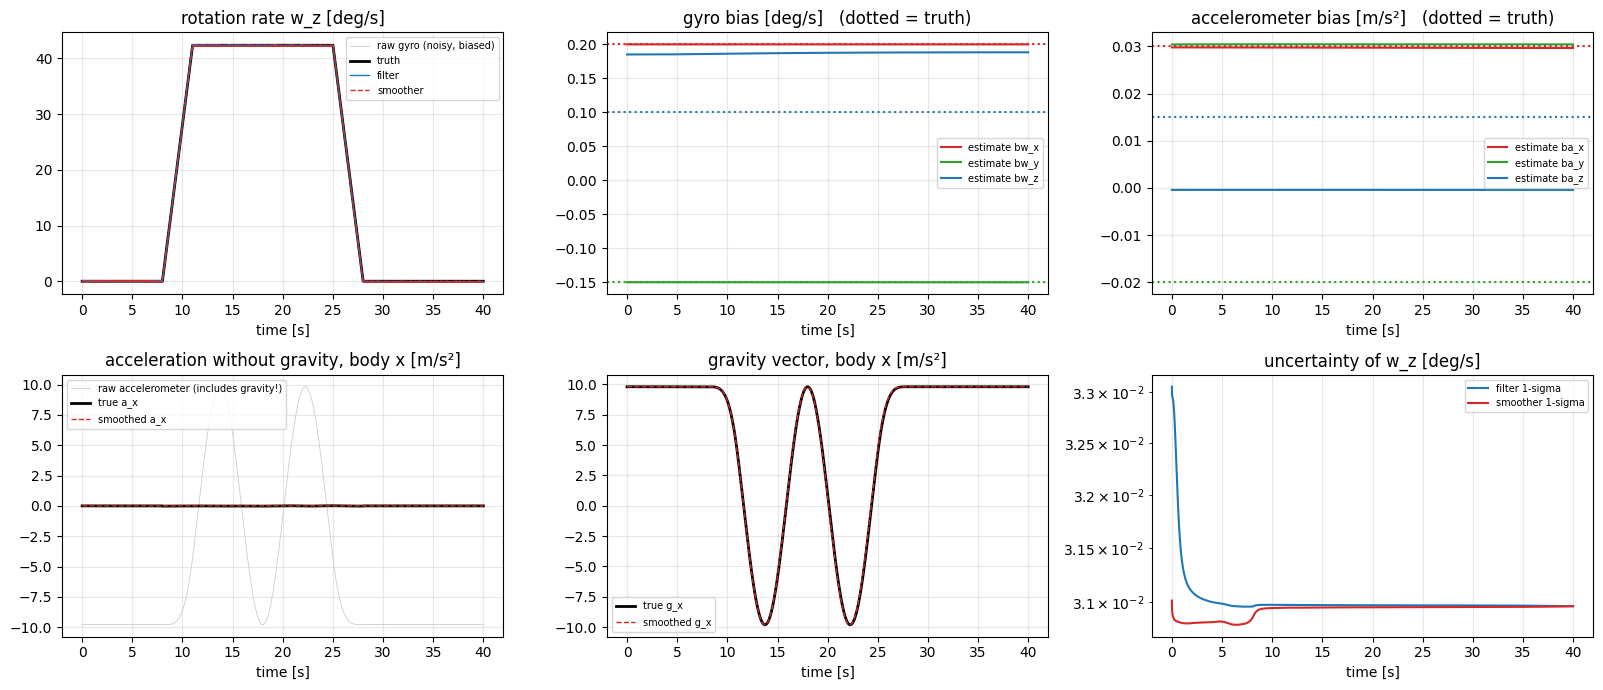

RMS error of the rotation rate w  [deg/s]:  raw gyro 0.158 | filter 0.042 | smoother 0.061
RMS error of the acceleration a [m/s^2]:   raw acc 0.0227 | filter 0.0071 | smoother 0.0076

BIASES  (estimate = filter value at the end of the run; compare with the secret truth)
  gyro  bias [deg/s]   estimate [ 0.2   -0.15   0.188]   truth [ 0.2  -0.15  0.1 ]
  accel bias [m/s^2]   estimate [ 0.0297  0.0304 -0.0004]   truth [ 0.03  -0.02   0.015]
  -> axes perpendicular to gravity are not separable from a small tilt of gravity (see text below)


In [13]:
# ======================= how good is it?  compare with the secret truth =======================
t = truth["t"]
fig, ax = plt.subplots(2, 3, figsize=(16, 7))

# (1) rotation rate about the body z axis: raw gyro vs filter vs smoother vs truth
ax[0, 0].plot(t, np.rad2deg(gyro1[:, 2]), color="0.8", lw=0.6, label="raw gyro (noisy, biased)")
ax[0, 0].plot(t, np.rad2deg(truth["wB"][:, 2]), "k", lw=2, label="truth")
ax[0, 0].plot(t, np.rad2deg(xf[:, 5]), "tab:blue", lw=1, label="filter")
ax[0, 0].plot(t, np.rad2deg(xs[:, 5]), "tab:red", lw=1, ls="--", label="smoother")
ax[0, 0].set_title("rotation rate w_z [deg/s]"); ax[0, 0].legend(fontsize=7)

# (2) gyro bias estimate converging to the true bias
for j, c in enumerate(("tab:red", "tab:green", "tab:blue")):
    ax[0, 1].plot(t, np.rad2deg(xs[:, 9 + j]), color=c, label=f"estimate bw_{'xyz'[j]}")
    ax[0, 1].axhline(np.rad2deg(bias_w_true[j]), color=c, ls=":")
ax[0, 1].set_title("gyro bias [deg/s]   (dotted = truth)"); ax[0, 1].legend(fontsize=7)

# (3) accelerometer bias estimate
for j, c in enumerate(("tab:red", "tab:green", "tab:blue")):
    ax[0, 2].plot(t, xs[:, 6 + j], color=c, label=f"estimate ba_{'xyz'[j]}")
    ax[0, 2].axhline(bias_a_true[j], color=c, ls=":")
ax[0, 2].set_title("accelerometer bias [m/s²]   (dotted = truth)"); ax[0, 2].legend(fontsize=7)

# (4) true acceleration a (body x) estimated
ax[1, 0].plot(t, acc1[:, 0], color="0.8", lw=0.6, label="raw accelerometer (includes gravity!)")
ax[1, 0].plot(t, truth["aB"][:, 0], "k", lw=2, label="true a_x")
ax[1, 0].plot(t, xs[:, 0], "tab:red", lw=1, ls="--", label="smoothed a_x")
ax[1, 0].set_title("acceleration without gravity, body x [m/s²]"); ax[1, 0].legend(fontsize=7)

# (5) gravity estimate vs truth (body x)
ax[1, 1].plot(t, truth["gB"][:, 0], "k", lw=2, label="true g_x")
ax[1, 1].plot(t, xs[:, 12], "tab:red", lw=1, ls="--", label="smoothed g_x")
ax[1, 1].set_title("gravity vector, body x [m/s²]"); ax[1, 1].legend(fontsize=7)

# (6) uncertainty: smoothed 1-sigma of w_z shrinks vs filtered
ax[1, 2].semilogy(t, np.rad2deg(np.sqrt(np.array(out["Pf"])[:, 5, 5])), "tab:blue", label="filter 1-sigma")
ax[1, 2].semilogy(t, np.rad2deg(np.sqrt(Ps[:, 5, 5])), "tab:red", label="smoother 1-sigma")
ax[1, 2].set_title("uncertainty of w_z [deg/s]"); ax[1, 2].legend(fontsize=7)

for a in ax.ravel(): a.grid(alpha=0.3); a.set_xlabel("time [s]")
plt.tight_layout(); plt.show()

rms = lambda e: float(np.sqrt(np.mean(np.sum(e ** 2, axis=1) / 3)))
print("RMS error of the rotation rate w  [deg/s]:  raw gyro %.3f | filter %.3f | smoother %.3f" % (
    np.rad2deg(rms(gyro1 - truth["wB"])), np.rad2deg(rms(xf[:, 3:6] - truth["wB"])), np.rad2deg(rms(xs[:, 3:6] - truth["wB"]))))
print("RMS error of the acceleration a [m/s^2]:   raw acc %.4f | filter %.4f | smoother %.4f" % (
    rms(acc1 - truth["acc_clean"]), rms(xf[:, 0:3] - truth["aB"]), rms(xs[:, 0:3] - truth["aB"])))
print("\nBIASES  (estimate = filter value at the end of the run; compare with the secret truth)")
print("  gyro  bias [deg/s]   estimate", np.rad2deg(xf[-1, 9:12]).round(3), "  truth", np.rad2deg(bias_w_true).round(3))
print("  accel bias [m/s^2]   estimate", xf[-1, 6:9].round(4), "  truth", bias_a_true)
print("  -> axes perpendicular to gravity are not separable from a small tilt of gravity (see text below)")

### 🔑 What we learn from the test drive (read this carefully — it is the honest picture)
* **Rotation rate and acceleration:** the filter removes most of the gyro/accelerometer error. The 42°/s plateau
  is kept (this is the effect of the dynamic safeguards in `make_cfg`), and gravity is separated from true acceleration.
* **Biases are only partly recovered.** Look at the two bias plots and the numbers above:
  * A bias *along the gravity direction* is observable (we know $\|\mathbf g\|=G_0$), so e.g. $b_{a,x}$ is found well.
  * A bias *perpendicular* to gravity is, at rest, **indistinguishable from a small tilt of gravity**
    (0.02 m/s² of bias looks the same as 0.12° of tilt). The start values (Section 4.8) therefore push it into the gravity
    direction, and the filter cannot separate the two afterwards.
  * We checked that even with **no noise and no biases** the filter ends with a small spurious bias on one axis: while the
    rotation speeds up, the model lags a little, and the leftover error is absorbed by the bias states. Biases are
    "shock absorbers" for everything the model does not capture. Their values should not be over-interpreted.
* **The smoother is not automatically better.** Biases hardly change in time, so the smoother simply copies the *end-of-run*
  bias estimate back to the start. If that final estimate is slightly off, the smoothed curves inherit a small offset
  (here the smoothed $\omega_z$ is a little *worse* than the filtered one, by about 0.04°/s). The smoother helps a lot
  for the fast, noisy states and can slightly hurt when a nearly-constant state is imperfect.
* What matters for the rest of the pipeline is that the **rotation rate and the gravity direction** are accurate
  to a few hundredths of a degree per second — as the numbers above show.

One sensor is already decent. Four sensors, correctly combined, are better — but two tools are needed first: **how to merge several
estimates** (Chapter 6) and **how each sensor is mounted** relative to the others (Chapter 7).

# Chapter 6 — Merging several estimates: information fusion

### 🧠 Intuition
Four friends each estimate the weight of a cake. One is a baker (very precise), three are guessing. You do not take the
plain average: you listen **more to the baker**. The weight you give to each friend is their **precision** =
1 / uncertainty. That is the whole idea; the only novelty is that for our sensors the "uncertainty" is a **matrix**
(it can be large in one direction and tiny in another, and directions can be linked).

### 📐 Formula
Sensor $i$ gives an estimate $\mathbf y_i$ with covariance $P_i$ (of the *same* physical quantity). Define the
**information (precision) matrix** $\Lambda_i=P_i^{-1}$. Then, assuming independent errors,

$$
\Lambda_f=\sum_i\Lambda_i,\qquad P_f=\Lambda_f^{-1},\qquad
\mathbf y_f=P_f\sum_i\Lambda_i\,\mathbf y_i .
$$

* For one number this is the familiar *inverse-variance weighted mean*: $y_f=\dfrac{\sum y_i/\sigma_i^2}{\sum 1/\sigma_i^2}$.
* $P_f$ is **smaller** than every $P_i$: merging never makes us less sure.
* With $N$ equally good sensors the fused standard deviation is $\sigma/\sqrt N$.

### ⚠️ Why we need a *safe* matrix inverse
Covariances can have directions in which we are almost perfectly sure (an eigenvalue near 0). A naïve inverse would
blow up. `psd_inverse` (PSD = *positive semi-definite*, the mathematical name of a valid covariance) first rescales
the matrix to a **correlation matrix** (entries in −1…1), floors tiny eigenvalues at $10^{-10}$, inverts, and rescales
back. It works on *batches*: thousands of matrices at once.

In [14]:
def psd_inverse(P, eig_floor=EIG_FLOOR):
    """Stable inverse of (batches of) approximately-PSD covariances, shape (...,d,d)."""
    # Make sure P is an array of decimal numbers (a stack of square matrices).
    P = np.asarray(P, float)
    # Symmetrise: a covariance must equal its own transpose.
    P = 0.5 * (P + np.swapaxes(P, -1, -2))
    # s = standard deviations (square roots of the diagonal; never exactly zero).
    s = np.sqrt(np.maximum(np.diagonal(P, axis1=-2, axis2=-1), 1e-300))
    # S[i][j] = s_i * s_j : the scaling matrix.
    S = s[..., :, None] * s[..., None, :]
    # Cm = correlation matrix = P divided element-wise by S (entries between -1 and 1).
    Cm = P / S
    # Eigen-decomposition: directions V and their strengths ev.
    ev, V = np.linalg.eigh(0.5 * (Cm + np.swapaxes(Cm, -1, -2)))
    # Invert the correlation matrix, never dividing by anything smaller than eig_floor.
    Ci = (V / np.maximum(ev, eig_floor)[..., None, :]) @ np.swapaxes(V, -1, -2)
    # Scale back: the inverse of the original covariance.
    return Ci / S

In [15]:
def fuse_information(Y, P, chunk=20000):
    """Full covariance-weighted information fusion, sample by sample (batched).
    Y: (m,n,d) estimates of m sensors, P: (m,n,d,d) covariances."""
    # Y holds the estimates (m sensors x n instants x d numbers); P the covariances.
    Y = np.asarray(Y, float)
    P = np.asarray(P, float)
    # m = number of sensors, n = number of instants, d = size of the estimated vector.
    m, n, d = Y.shape
    # Space for the results: fused estimates and fused covariances.
    yf = np.empty((n, d)); Pf = np.empty((n, d, d))
    # Process the instants in chunks, to limit memory use.
    for i0 in range(0, n, chunk):
        # End of this chunk.
        i1 = min(n, i0 + chunk)
        # L = information (precision) matrix of every sensor at every instant:  Lambda_i = P_i^-1.
        L = psd_inverse(P[:, i0:i1])                       # (m,c,d,d)
        # Fused covariance:  P_f = (sum of the Lambda_i)^-1.
        Pk = psd_inverse(L.sum(axis=0))                    # (c,d,d)
        # b = sum over sensors of  Lambda_i * y_i.
        bvec = np.einsum("mnij,mnj->ni", L, Y[:, i0:i1])
        # Fused estimate:  y_f = P_f b.
        yf[i0:i1] = np.einsum("nij,nj->ni", Pk, bvec)
        # Store the (symmetrised) fused covariance.
        Pf[i0:i1] = 0.5 * (Pk + np.swapaxes(Pk, -1, -2))
    # Return the fused estimates and their covariances.
    return yf, Pf

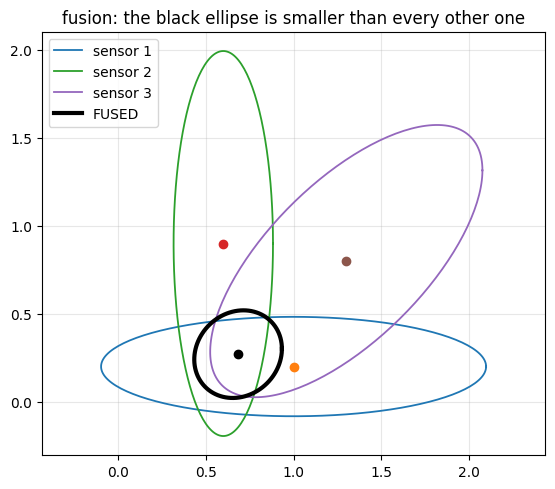

fused estimate: [0.684 0.271]
single sensor error std = 0.996;  fused error std = 0.503  (theory 1/sqrt(4) = 0.5)


In [16]:
# ======================= Chapter 6 demo: fuse three 2-D estimates with different uncertainty ellipses ===========
def ellipse(mean, P, k=2.0):
    # Points of the k-sigma uncertainty ellipse of a 2-D estimate (mean, covariance P) for drawing.
    th = np.linspace(0, 2 * np.pi, 200)
    L = np.linalg.cholesky(P)                           # 'square root' of the covariance matrix
    return mean[:, None] + k * L @ np.vstack([np.cos(th), np.sin(th)])

means = [np.array([1.0, 0.2]), np.array([0.6, 0.9]), np.array([1.3, 0.8])]       # three estimates of the same 2-D quantity
covs  = [np.array([[0.30, 0.00], [0.00, 0.02]]),         # sensor 1: precise in y, vague in x
         np.array([[0.02, 0.00], [0.00, 0.30]]),         # sensor 2: precise in x, vague in y
         np.array([[0.15, 0.10], [0.10, 0.15]])]         # sensor 3: uncertainty tilted (x and y errors linked)

Y = np.stack([m[None, :] for m in means])                # shape (3 sensors, 1 instant, 2 numbers)
P = np.stack([c[None, :, :] for c in covs])              # shape (3, 1, 2, 2)
yf, Pf = fuse_information(Y, P)                          # <- the project's fusion function

plt.figure(figsize=(6.5, 5.5))
for i, (m, c) in enumerate(zip(means, covs)):
    e = ellipse(m, c); plt.plot(e[0], e[1], lw=1.3, label=f"sensor {i+1}"); plt.plot(*m, "o")
e = ellipse(yf[0], Pf[0]); plt.plot(e[0], e[1], "k", lw=3, label="FUSED"); plt.plot(*yf[0], "ko")
plt.axis("equal"); plt.grid(alpha=0.3); plt.legend(); plt.title("fusion: the black ellipse is smaller than every other one")
plt.show()
print("fused estimate:", yf[0].round(3))

# Monte-Carlo check of the 1/sqrt(N) rule: 4 equal sensors with noise std 1
rng = np.random.default_rng(0)
truth_val = 5.0
Ys = truth_val + rng.standard_normal((4, 20000, 1))      # 4 sensors, 20000 independent trials
Ps = np.ones((4, 20000, 1, 1))                           # each sensor has variance 1
yf2, _ = fuse_information(Ys, Ps)
print(f"single sensor error std = {Ys[0].std():.3f};  fused error std = {yf2.std():.3f}  (theory 1/sqrt(4) = 0.5)")

# Chapter 7 — Registration: how is each sensor mounted? (the Wahba problem)

### 🧠 Intuition
The four IMUs are glued to the same object, but **not with the same orientation**: sensor 2's "x" arrow may point where
sensor 1's "y" arrow points. Before we can merge their numbers we must rotate each sensor's axes into a **common frame**.
We choose sensor 1's axes as that common ("reference body") frame.

Both the gravity vector and the rotation-rate vector are *physical arrows* that all sensors see — only expressed in
different axes. So for sensor $i$ there is one fixed rotation $C_i$ with

$$
\mathbf v^{(s1)}_k \;=\; C_i\,\mathbf v^{(i)}_k\qquad\text{for both }\mathbf v=\mathbf g\text{ and }\mathbf v=\boldsymbol\omega,\ \text{at every instant }k .
$$

Finding the rotation that best maps one set of arrows onto another is a classical problem named after Grace Wahba (1965).

### 📐 Formula
**Classical Wahba (weighted).** Minimise $\sum_k w_k\,\|\mathbf t_k-C\mathbf s_k\|^2$ over rotations $C$.
Build $H=\sum_k w_k\,\mathbf t_k\mathbf s_k^{\mathsf T}$, take its SVD $H=U\Sigma V^{\mathsf T}$, then
$C=U\,\mathrm{diag}(1,1,\det(UV^{\mathsf T}))\,V^{\mathsf T}$. The `det` guarantees a proper rotation, not a mirror image.
The project uses this **only as a starting guess** (`weighted_wahba_init`).

**Covariance-weighted version (what the project actually solves).** At each instant stack
$\mathbf y=[\mathbf g;\boldsymbol\omega]$ (6 numbers) with its full $6\times6$ covariance (including the g–ω
cross terms, from the smoother). With $B(C)=\mathrm{diag}(C,C)$:

$$
\min_C\ \sum_k \mathbf r_k^{\mathsf T}\Sigma_k^{-1}\mathbf r_k,\qquad
\mathbf r_k=\mathbf y^{\text{ref}}_k-B(C)\,\mathbf y^{\text{src}}_k,\qquad
\Sigma_k=P^{\text{ref}}_k+B(C)\,P^{\text{src}}_k\,B(C)^{\mathsf T}.
$$

*Reading:* a residual counts **a lot** when the combined uncertainty $\Sigma_k$ is small and **little** when it is large.
So a gyro sample while the sensor is still (rate ≈ noise) automatically has almost no say — no ad-hoc rule needed.

**Solving it (Gauss–Newton on rotations).** Write the update as $C\leftarrow\mathrm{Exp}(\boldsymbol\delta)\,C$ with a small rotation
vector $\boldsymbol\delta$. Then $\mathbf r(\boldsymbol\delta)\approx\mathbf r_0+A\boldsymbol\delta$ with
$A=\big[[\,C\mathbf s_g\,]_\times;\ [\,C\mathbf s_\omega\,]_\times\big]$, and the best step is
$$
H_{\!\text{info}}=\sum_k A_k^{\mathsf T}\Sigma_k^{-1}A_k,\qquad
\mathbf b=\sum_k A_k^{\mathsf T}\Sigma_k^{-1}\mathbf r_k,\qquad
\boldsymbol\delta=-H_{\!\text{info}}^{+}\,\mathbf b .
$$
($^+$ = pseudo-inverse: directions with no information are simply left alone.) We repeat, re-evaluating $\Sigma_k$ each time.
The final $H_{\!\text{info}}$ is also useful: $H_{\!\text{info}}^{-1}$ is the **uncertainty of the registration** (printed by the program).

### Why both gravity AND rotation rate?
Gravity points along Earth's vertical. If sensor 2 differs from sensor 1 only by a **turn about the vertical**, the gravity
vector is *identical* in both: gravity cannot tell this turn. The rotating-motion vectors $\boldsymbol\omega$ can.
The experiment below makes this concrete.

### Leave-one-out refinement and the consensus
With $\ge3$ sensors, each sensor $i$ is re-registered against the **fused estimate of all the *other* sensors** (so no
sensor helps define its own target, and sensor 1's noise is not the only reference). Finally the *consensus* is the
information-fused $[\mathbf g,\boldsymbol\omega]$ of all sensors, expressed in sensor 1's axes, and $\mathbf g$ is rescaled to length $G_0$.

In [17]:
def normalize(v, eps=1e-15):
    # Make sure v is an array of decimal numbers.
    v = np.asarray(v, float)
    # n = length of the vector.
    n = np.linalg.norm(v)
    # Divide by the length so the result has length 1 (a pure direction); `eps` avoids dividing by zero.
    return v / max(n, eps)

In [18]:
def exp_so3(phi):
    # Rotation vector (axis x angle) -> 3x3 rotation matrix. Same as Chapter 2.
    return Rot.from_rotvec(np.asarray(phi, float)).as_matrix()

In [19]:
def skew_batch(v):
    # Same as `skew`, but for n vectors at the same time.
    # v is a list of n 3-vectors (shape n x 3).
    v = np.asarray(v, float)
    # Prepare n empty 3x3 matrices.
    Z = np.zeros((len(v), 3, 3))
    # Fill every matrix with the cross-product pattern of Chapter 2 (all n at once = fast).
    Z[:, 0, 1] = -v[:, 2]; Z[:, 0, 2] = v[:, 1]
    Z[:, 1, 0] = v[:, 2];  Z[:, 1, 2] = -v[:, 0]
    Z[:, 2, 0] = -v[:, 1]; Z[:, 2, 1] = v[:, 0]
    return Z

In [20]:
def bd2(C):
    # The 6x6 'block-diagonal' matrix diag(C, C): the same rotation C acts on g (first 3) and on w (last 3); no mixing between them.
    M = np.zeros((6, 6)); M[:3, :3] = C; M[3:, 3:] = C
    return M

In [21]:
GW_IDX = np.r_[SL["g"].start:SL["g"].stop, SL["w"].start:SL["w"].stop]   # positions of [g(3), w(3)] inside the 15-vector
print("positions of g and w in the 15-state:", GW_IDX)

positions of g and w in the 15-state: [12 13 14  3  4  5]


In [22]:
def gw_blocks(x, P):
    """Joint [g, w] estimate (n,6) and full 6x6 covariance (n,6,6) of one IMU,
    including the g-w cross-covariance, taken from the smoothed 15-state."""
    # Pick out the 6 numbers [g, w] of every instant, and the full 6x6 block of the covariance (keeps the g-w links).
    return x[:, GW_IDX], P[:, GW_IDX[:, None], GW_IDX[None, :]]

In [23]:
def map_gw(y, P, C):
    """Rotate both 3-blocks of [g,w] by C and propagate the 6x6 covariance."""
    # Build diag(C, C).
    B = bd2(C)
    # Rotate the means (rows are instants, hence the transpose) and transform the covariance:  B P B^T.
    return y @ B.T, B @ P @ B.T

In [24]:
def _pinv_solve(H, b, rel=1e-10):
    # Solves H x = b while ignoring directions that carry no information.
    # Eigen-decomposition of the information matrix: directions V, strengths ev.
    ev, V = np.linalg.eigh(0.5 * (H + H.T))
    # No information at all -> do nothing.
    if ev.max() <= 0.0:
        return np.zeros(3)
    # Keep only directions with real information (ignore the numerically-zero ones).
    keep = ev > rel * ev.max()
    # Solve H x = b using only those directions (pseudo-inverse).
    return V[:, keep] @ ((V[:, keep].T @ b) / ev[keep])

In [25]:
def weighted_wahba_init(T, PT, S, PS):
    """Classical weighted Wahba (Markley SVD) with scalar weights derived from
    the estimate covariances.  Used only to initialise the full-covariance
    Gauss-Newton refinement below.
        w_g = 1 / (mean tangential variance of g_t and g_s)
        w_w = 1 / (mean variance of w_t and w_s)
    so a gyro sample with |w| << sigma_w automatically gets (almost) no say,
    and no ad-hoc factor / activity threshold is needed."""
    # Smallest allowed variance (avoid division by 0).
    tiny = 1e-30
    # Total variance of the gravity pair (reference + source) at each instant...
    trg = np.trace(PT[:, :3, :3], axis1=1, axis2=2) + np.trace(PS[:, :3, :3], axis1=1, axis2=2)
    # ...and of the angular-rate pair.
    trw = np.trace(PT[:, 3:, 3:], axis1=1, axis2=2) + np.trace(PS[:, 3:, 3:], axis1=1, axis2=2)
    # Weights = 1 / typical variance: precise instants count more.
    wg = 1.0 / np.maximum(trg / 2.0, tiny)
    # (same for the gyro part).
    ww = 1.0 / np.maximum(trw / 3.0, tiny)
    # H = sum of weight * (target arrow) (source arrow)^T, for gravity and for rate.
    H = (np.einsum("n,ni,nj->ij", wg, T[:, :3], S[:, :3])
         + np.einsum("n,ni,nj->ij", ww, T[:, 3:], S[:, 3:]))
    # Singular value decomposition of H.
    U, _, Vt = np.linalg.svd(H)
    # Force a proper rotation (determinant +1), not a mirror.
    D = np.eye(3); D[-1, -1] = np.linalg.det(U @ Vt)
    # The rotation that best aligns the arrows: this is only the STARTING GUESS.
    return U @ D @ Vt

In [26]:
def weighted_wahba(T, PT, S, PS, C0, max_iter=15, tol=1e-10):
    """Covariance-weighted Wahba problem on SO(3), joint over gravity and
    angular rate:

        min_C  sum_k  r_k^T Sigma_k^{-1} r_k ,
        r_k     = [g_t - C g_s ; w_t - C w_s]_k
        Sigma_k = P_t,k + B(C) P_s,k B(C)^T       (full 6x6, incl. g-w cross terms)

    Solved by Gauss-Newton with C <- exp([d]x) C and Sigma re-evaluated at the
    current C (iteratively reweighted).  Returns C and the 3x3 information
    matrix H (H^-1 = covariance of the small-angle registration error)."""
    # Start from the initial guess C0.
    C = np.array(C0, float)
    # H will hold the information matrix (how well each rotation direction is determined).
    H = np.zeros((3, 3))
    # Repeat (at most max_iter times): linearise, solve, update.
    for _ in range(max_iter):
        # Rotate the source estimates (and covariances) with the current C.
        CS, PSr = map_gw(S, PS, C)
        # W = Sigma^-1 : the weights (inverse of the combined uncertainty).
        W = psd_inverse(PT + PSr)
        # Residuals: target minus rotated source (ideally zero).
        r = T - CS
        # A = how the residual changes for a small extra rotation (cross-product matrices of the rotated arrows).
        A = np.concatenate([skew_batch(CS[:, :3]), skew_batch(CS[:, 3:])], axis=1)  # r(d) = r0 + A d
        # Weighted version of A.
        WA = W @ A
        # Information matrix  H = sum A^T W A.
        H = np.einsum("mia,mib->ab", A, WA)
        # Right-hand side  b = sum A^T W r.
        b = np.einsum("mia,mi->a", WA, r)
        # Best small rotation vector (Gauss-Newton step).
        step = -_pinv_solve(H, b)
        # Apply it: C <- Exp(step) C  (a rotation composed with a rotation: stays a rotation).
        C = exp_so3(step) @ C
        # Stop when the step has become negligible (converged).
        if np.linalg.norm(step) < tol:
            break
    # Return the registration rotation and its information matrix.
    return C, H

In [27]:
def registration_stats(H):
    # Eigen-decomposition of the information matrix.
    ev, V = np.linalg.eigh(0.5 * (H + H.T))
    # Directions that are really determined.
    keep = ev > 1e-10 * max(ev.max(), 1e-300)
    # Covariance of the small registration angle = pseudo-inverse of H.
    cov = (V[:, keep] / ev[keep]) @ V[:, keep].T if keep.any() else np.full((3, 3), np.inf)
    # Uncertainty (1 sigma, degrees) of the WEAKEST direction: infinity if one direction is not determined at all.
    smax = np.rad2deg(1.0 / np.sqrt(ev[0])) if ev[0] > 1e-10 * max(ev.max(), 1e-300) else np.inf
    # Package the diagnostics: per-axis 1-sigma in degrees, and the worst direction.
    return {"H": H, "cov": cov,
            "sigma_deg": np.rad2deg(np.sqrt(np.maximum(np.diag(cov), 0.0))),
            "sigma_max_deg": float(smax)}

In [28]:
def register_sensors(xs_by_sensor, Ps_by_sensor, sensors, stride=REGISTRATION_STRIDE,
                     active_thr_dps=REGISTRATION_MIN_ACTIVE_DPS, refine_iters=2):
    """Covariance-weighted registration of every IMU to the s1 body frame.

    1) each sensor vs s1: weighted-SVD initial guess + full-covariance
       Gauss-Newton on the joint [g, w] residual;
    2) (N>=3) Gauss-Seidel refinement: each sensor is re-registered against the
       information-fused [g, w] of ALL OTHER sensors (leave-one-out, so a sensor
       never helps define its own target and s1 noise is not the sole reference).
    s1 stays the gauge: C_s1 = I.
    `active_mask` is only a diagnostic (inverse-variance-weighted mean of |w|);
    it no longer selects samples, the covariances do the weighting."""
    # Sensor 1 defines the common (reference body) frame.
    ref = sensors[0]
    # Number of samples.
    n = len(xs_by_sensor[ref])
    # Use only every `stride`-th sample (fast; neighbouring samples are nearly identical anyway).
    ids = np.arange(n)[::max(1, int(stride))]
    # ...but if that leaves too few samples, use all of them.
    if len(ids) < 10:
        ids = np.arange(n)
    # For every sensor collect the 6-vector [g, w] and its 6x6 covariance at those samples.
    Y, P = {}, {}
    # (loop over the sensors)
    for s in sensors:
        Y[s], P[s] = gw_blocks(xs_by_sensor[s][ids], Ps_by_sensor[s][ids])

    # Size of the angular rate of every sensor at every sample...
    wn = np.stack([np.linalg.norm(xs_by_sensor[s][:, SL["w"]], axis=1) for s in sensors])
    # ...and its variance.
    wv = np.stack([np.trace(Ps_by_sensor[s][:, SL["w"], SL["w"]], axis1=1, axis2=2) / 3.0 for s in sensors])
    # Inverse-variance weights.
    wt = 1.0 / np.maximum(wv, 1e-30)
    # Diagnostic only: mark the samples where the object is really rotating (precision-weighted mean rate above the threshold).
    mask = ((wt * wn).sum(0) / wt.sum(0)) > np.deg2rad(active_thr_dps)
    # If there is hardly any rotation, mark everything.
    if mask.sum() < 10:
        mask[:] = True

    # Reference sensor: identity rotation (it IS the reference frame).
    C = {ref: np.eye(3)}
    # Information matrices of the registrations.
    Hs = {}
    # STEP 1: register every other sensor directly against sensor 1...
    for s in sensors[1:]:
        # ...first the quick classical answer (SVD)...
        C0 = weighted_wahba_init(Y[ref], P[ref], Y[s], P[s])
        # ...then refine it with the covariance-weighted Gauss-Newton method.
        C[s], Hs[s] = weighted_wahba(Y[ref], P[ref], Y[s], P[s], C0)

    # STEP 2 (3 or more sensors): leave-one-out refinement, repeated `refine_iters` times.
    if len(sensors) >= 3 and refine_iters > 0:
        # (sweeps)
        for _ in range(int(refine_iters)):
            # For each sensor s ...
            for s in sensors[1:]:
                # ...collect the OTHER sensors' estimates, rotated into sensor 1's axes...
                ys, Pl = [], []
                # (loop over the others)
                for o in sensors:
                    if o == s:
                        continue
                    # Rotate sensor o's [g, w] and covariance with its current registration.
                    yo, Po = map_gw(Y[o], P[o], C[o])
                    ys.append(yo); Pl.append(Po)
                # ...fuse them (Chapter 6) into one better target...
                Tf, PTf = fuse_information(np.stack(ys), np.stack(Pl))
                # ...and re-register sensor s against that fused target.
                C[s], Hs[s] = weighted_wahba(Tf, PTf, Y[s], P[s], C[s])

    # Registration uncertainty report (the reference has none: it is exact by definition).
    stats = {ref: {"H": np.zeros((3, 3)), "cov": np.zeros((3, 3)),
                   "sigma_deg": np.zeros(3), "sigma_max_deg": 0.0}}
    # For every other sensor...
    for s in sensors[1:]:
        # ...compute the uncertainty of its registration...
        stats[s] = registration_stats(Hs[s])
        # ...and warn if some direction is poorly determined (e.g. no rotation excited the yaw).
        if stats[s]["sigma_max_deg"] > 1.0:
            warnings.warn(
                f"Registration for {s}: weakest direction has 1-sigma = "
                f"{stats[s]['sigma_max_deg']:.3g} deg (insufficient tilt/rotation "
                f"excitation; relative yaw may be ambiguous)."
            )
    # Return the rotations C, the activity mask and the statistics.
    return C, mask, stats

In [29]:
def consensus_body_history(xs_by_sensor, Ps_by_sensor, C, sensors, chunk=20000):
    """Covariance-weighted (information-form) consensus of [g, w] in the s1
    body frame at every sample, using each IMU's full 6x6 smoothed covariance
    mapped through its registration C_s.  Replaces the previous median.
    g is renormalised to G0 afterwards (only its direction is used)."""
    # Number of samples.
    n = len(xs_by_sensor[sensors[0]])
    # Space for the fused gravity, fused rate and fused covariance of every sample.
    g = np.empty((n, 3)); w = np.empty((n, 3)); Pc = np.empty((n, 6, 6))
    # Work through the samples in chunks (memory).
    for i0 in range(0, n, chunk):
        # End of this chunk.
        i1 = min(n, i0 + chunk)
        # Collect every sensor's [g, w] in sensor 1's axes...
        ys, Pl = [], []
        # (loop over sensors)
        for s in sensors:
            # Take the sensor's smoothed [g, w] and covariance...
            y, Pm = gw_blocks(xs_by_sensor[s][i0:i1], Ps_by_sensor[s][i0:i1])
            # ...rotate them into sensor 1's axes with its registration C...
            y, Pm = map_gw(y, Pm, C[s])
            # ...and store.
            ys.append(y); Pl.append(Pm)
        # Fuse all sensors (Chapter 6): one consensus [g, w] per instant.
        yf, Pf = fuse_information(np.stack(ys), np.stack(Pl))
        # Length of the fused gravity vector.
        gn = np.linalg.norm(yf[:, :3], axis=1, keepdims=True)
        # Keep only its DIRECTION and give it the exact length G0.
        g[i0:i1] = yf[:, :3] / np.maximum(gn, 1e-15) * G0
        # Fused angular rate (body axes of sensor 1).
        w[i0:i1] = yf[:, 3:]
        # Fused covariance.
        Pc[i0:i1] = Pf
    # Return consensus gravity, rate and covariance.
    return g, w, Pc

gravity only   : error vs truth =  24.917 deg   |  1-sigma per axis [deg] = [0.01  0.01  3.284]   weakest direction = 3.28 deg
gravity + gyro : error vs truth =   0.057 deg   |  1-sigma per axis [deg] = [0.009 0.009 0.052]   weakest direction = 0.0519 deg


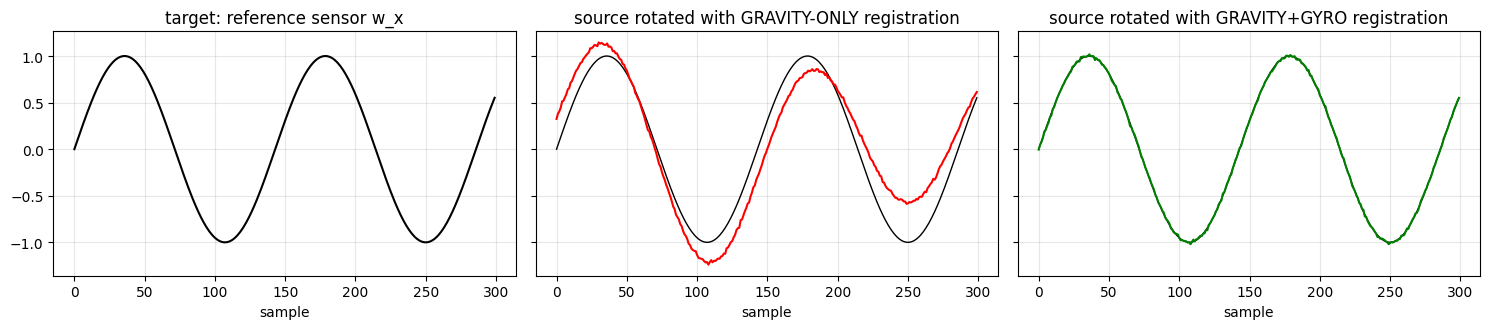

In [30]:
# ======================= Chapter 7 demo: why gravity alone cannot register a turn about the vertical ===============
rng = np.random.default_rng(7)
n = 300; tt = np.arange(n) / 100.0
C_true = Rot.from_euler("z", 55.0, degrees=True).as_matrix()      # secret mounting: sensor 2 is turned 55 deg about the vertical

# What the REFERENCE sensor sees: gravity constant (sensor tilted still), rotation rate wandering in 3-D.
g_ref = np.tile([0.0, 0.0, -G0], (n, 1))
w_ref = np.column_stack([1.0 * np.sin(2 * np.pi * 0.7 * tt), 0.8 * np.cos(2 * np.pi * 0.4 * tt), 0.5 * np.sin(2 * np.pi * 0.2 * tt + 1)])
sg, sw = 0.02, 0.01                                               # noise std of the g and w estimates

T = np.hstack([g_ref + sg * rng.standard_normal((n, 3)), w_ref + sw * rng.standard_normal((n, 3))])          # reference [g, w]
S = np.hstack([g_ref @ C_true + sg * rng.standard_normal((n, 3)), w_ref @ C_true + sw * rng.standard_normal((n, 3))])  # source sensor, in ITS axes
PT = np.tile(np.diag([sg**2] * 3 + [sw**2] * 3), (n, 1, 1))       # covariances (diagonal here)
PS = PT.copy()

def registration_error(C):
    return np.rad2deg(np.linalg.norm(Rot.from_matrix(C.T @ C_true).as_rotvec()))   # angle between C and the truth

# (a) GRAVITY ONLY: tell the solver the gyro is useless by giving it a gigantic variance
PT_g, PS_g = PT.copy(), PS.copy()
PT_g[:, 3:, 3:] *= 1e12; PS_g[:, 3:, 3:] *= 1e12
C0 = weighted_wahba_init(T, PT_g, S, PS_g); C_g, H_g = weighted_wahba(T, PT_g, S, PS_g, C0)
# (b) GRAVITY + GYRO (what the project does)
C0 = weighted_wahba_init(T, PT, S, PS);     C_j, H_j = weighted_wahba(T, PT, S, PS, C0)

for name, C, H in (("gravity only", C_g, H_g), ("gravity + gyro", C_j, H_j)):
    st = registration_stats(H)
    print(f"{name:15s}: error vs truth = {registration_error(C):7.3f} deg   |  1-sigma per axis [deg] = {np.round(st['sigma_deg'], 3)}   weakest direction = {st['sigma_max_deg']:.3g} deg")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.4), sharey=True)
ax[0].plot(w_ref[:, 0], "k"); ax[0].set_title("target: reference sensor w_x")
ax[1].plot(w_ref[:, 0], "k", lw=1); ax[1].plot((S[:, 3:] @ C_g.T)[:, 0], "r"); ax[1].set_title("source rotated with GRAVITY-ONLY registration")
ax[2].plot(w_ref[:, 0], "k", lw=1); ax[2].plot((S[:, 3:] @ C_j.T)[:, 0], "g"); ax[2].set_title("source rotated with GRAVITY+GYRO registration")
for a in ax: a.grid(alpha=0.3); a.set_xlabel("sample")
plt.tight_layout(); plt.show()

### 🔑 What we learn
* **Gravity only:** the registration is wrong by tens of degrees. The uncertainty report flags it: the weakest direction has a
  1-σ of a few degrees, about 60 times larger than with the gyro (gravity cannot see a turn about the vertical, and the near-singular problem
  also makes the answer unreliable beyond what the report says).
* **Gravity + gyro:** error well below one degree, and the reported uncertainty is small. The project's program
  prints a warning whenever the weakest direction exceeds 1° — meaning "your motion did not excite this
  direction; trust the registration less".
* In the real experiment the rotation about a horizontal axis (Earth Y) makes gravity itself move through the sensor
  frame, which already helps a lot; the gyro term then resolves the rest.

# Chapter 8 — Building the Earth-frame orientation and projecting everything to the Earth

So far every number is written in **body axes**. The goal is the **Earth frame** (X, Y horizontal, Z up).
We need the rotation $R_k$ (body → Earth) at *every instant $k$*. Where does it come from? Three ingredients:

**(1) Initial attitude from gravity** (`gravity_alignment_R`). At rest the accelerometer tells where "down" is in the sensor
axes. That fixes the **tilt** (roll and pitch) but **not the compass heading (yaw)**: turning the sensor about the vertical
does not change gravity. So we *choose* yaw = 0 at the start (a coordinate convention). With $\mathbf g=(g_x,g_y,g_z)/\|\mathbf g\|$:
$$
\text{pitch}=\operatorname{atan2}\!\big(g_x,\sqrt{g_y^2+g_z^2}\big),\quad
\text{roll}=\operatorname{atan2}(-g_y,-g_z),\quad
R_0=R_y(\text{pitch})\,R_x(\text{roll}),\quad R_0\,\hat{\mathbf g}=(0,0,-1).
$$

**(2) Integrate the rotation rate** (`integrate_orientation`). Orientation changes by the rotation rate:
$$
R_{k+1}=R_k\,\operatorname{Exp}\!\Big(\tfrac{\boldsymbol\omega_k+\boldsymbol\omega_{k+1}}{2}\,\Delta t\Big)
$$
(using the average of two consecutive rates is more accurate than using only one).
Problem: small rate errors accumulate, so the **tilt slowly drifts**.

**(3) Correct the tilt with gravity at every instant** (`gravity_corrected_orientation`). Since we also know the gravity direction
at every instant, we compare *predicted* gravity $R_k^{\mathsf T}(0,0,-1)$ with *measured* gravity and apply the **smallest rotation $D$**
that makes them agree: $R_k\leftarrow R_k D$. (`minimal_map` computes that smallest rotation: axis $\propto \mathbf u\times\mathbf v$,
angle $=\operatorname{atan2}(\|\mathbf u\times\mathbf v\|,\mathbf u\cdot\mathbf v)$.) The correction only moves the **tilt**; the **yaw** comes
purely from the gyro integration — which is exactly the physics: gravity knows tilt, only the gyro knows heading changes.

**Projection** (`project_earth_with_cov`). With the sensor's registration $C_i$ and $R_k$, any body vector $\mathbf x$ of sensor $i$ becomes
$\mathbf x_E=T_k\mathbf x$, $T_k=R_kC_i$. Its covariance transforms as $P_E=J P J^{\mathsf T}$ with $J=\operatorname{diag}(T_k,\dots,T_k)$
(five blocks: $a,\omega,b_a,b_\omega,g$). The result is stored as a 15-vector and a $15\times15$ covariance per instant.

In [31]:
def gravity_alignment_R(g_body):
    """Minimum-yaw body->Earth rotation with R*g = [0,0,-1]."""
    # Direction of gravity in the sensor's axes (length 1).
    g = normalize(g_body)
    # Its three components.
    gx, gy, gz = g
    # h = length of the (y, z) part.
    h = max(np.hypot(gy, gz), 1e-15)
    # Pitch: how far gravity leans out of the y-z plane.
    pitch = np.arctan2(gx, h)
    # Roll: the angle of gravity inside the y-z plane.
    roll = np.arctan2(-gy, -gz)
    # Cosines and sines needed to write the rotation matrices.
    cp, sp = np.cos(pitch), np.sin(pitch)
    cr, sr = np.cos(roll), np.sin(roll)
    # Rotation about y by `pitch`, and about x by `roll` (standard 3x3 matrices).
    Ry = np.array([[cp, 0.0, sp], [0.0, 1.0, 0.0], [-sp, 0.0, cp]])
    Rx = np.array([[1.0, 0.0, 0.0], [0.0, cr, -sr], [0.0, sr, cr]])
    # Combine: body -> Earth rotation with gravity pointing down and yaw = 0.
    return Ry @ Rx

In [32]:
def minimal_map(u, v):
    """Proper rotation C such that C @ u ~= v, with minimum angle."""
    # Work with pure directions.
    u = normalize(u); v = normalize(v)
    # c = cos(angle between u and v).
    c = float(np.clip(np.dot(u, v), -1.0, 1.0))
    # The rotation axis is perpendicular to both: u x v.
    a = np.cross(u, v)
    # s = sin(angle).
    s = np.linalg.norm(a)
    # Special case: u and v are parallel or opposite (no unique axis).
    if s < 1e-12:
        # Already aligned: no rotation needed.
        if c > 0.0:
            return np.eye(3)
        # Opposite directions: pick any axis perpendicular to u...
        ref = np.array([1., 0., 0.]) if abs(u[0]) < 0.9 else np.array([0., 1., 0.])
        # ...(the helper arrow `ref` just has to be not parallel to u)...
        axis = normalize(np.cross(u, ref))
        # ...and turn by 180 degrees.
        return exp_so3(np.pi * axis)
    # Normal case: unit rotation axis.
    axis = a / s
    # Rotate about it by the angle between u and v (the SMALLEST rotation taking u to v).
    return exp_so3(np.arctan2(s, c) * axis)

In [33]:
def integrate_orientation(w_body, R0, dt):
    # Number of samples.
    n = len(w_body)
    # A list of n rotation matrices; the first one is the starting attitude R0.
    R = np.empty((n, 3, 3)); R[0] = R0
    # Step through time.
    for k in range(n - 1):
        # Average rotation rate over this step (body axes).
        wm = 0.5 * (w_body[k] + w_body[k + 1])
        # Turn by (rate x time) about the body axes:  R_next = R Exp(w dt).
        R[k + 1] = R[k] @ exp_so3(wm * dt)
    # The orientation history.
    return R

In [34]:
def gravity_corrected_orientation(R_base, g_ref):
    """At each sample, use g_ref to correct tilt while preserving yaw."""
    # Number of samples.
    n = len(g_ref)
    # Space for the corrected orientations.
    R = np.empty_like(R_base)
    # Earth's 'down' direction.
    gE = np.array([0.0, 0.0, -1.0])
    # For every instant...
    for k in range(n):
        # ...the gravity direction the integrated orientation PREDICTS in body axes...
        g_pred_B = normalize(R_base[k].T @ gE)
        # ...the gravity direction actually MEASURED (consensus)...
        g_meas_B = normalize(g_ref[k])
        # ...the smallest rotation that fixes the mismatch (only tilt changes)...
        D = minimal_map(g_meas_B, g_pred_B)
        # ...applied to the orientation.
        R[k] = R_base[k] @ D
    # Tilt-corrected orientation history (yaw still comes only from the gyro).
    return R

In [35]:
def project_earth_with_cov(xs, Ps, C, R_hist, G0=G0):
    """Project [a,w,ba,bw,g] to Earth and propagate the conditional covariance.

    The returned covariance is exact for the linear transformation induced by
    the estimated registration C and the estimated orientation R_hist.  The
    covariance of R_hist itself is not included because it depends on the
    complete preceding trajectory (cross-time attitude uncertainty). Treating
    it as an instantaneous independent covariance would be misleading and
    would also make large batch runs unnecessarily expensive.
    """
    # Number of samples.
    n = len(xs)
    # Space for the Earth-frame 15-vectors and 15x15 covariances.
    y15 = np.empty((n, 15))
    P15 = np.empty((n, 15, 15))
    # (small cache list)
    Tcache = [None] * n
    # For every instant...
    for k in range(n):
        # T = (body -> Earth) x (this sensor -> reference body):  the full rotation of this sensor's vectors into Earth axes.
        T = R_hist[k] @ C
        Tcache[k] = T
        # Rotate each of the five 3-vectors: acceleration, rate, accelerometer bias, gyro bias, gravity.
        a = T @ xs[k, SL["a"]]
        w = T @ xs[k, SL["w"]]
        ba = T @ xs[k, SL["ba"]]
        bw = T @ xs[k, SL["bw"]]
        g = T @ xs[k, SL["g"]]
        # Stack them into one 15-vector.
        y15[k] = np.concatenate([a, w, ba, bw, g])

        # J = the 15x15 'rotate each block by T' matrix...
        J = np.zeros((15, N_X))
        # ...with T on the diagonal blocks.
        for r0 in (0, 3, 6, 9, 12):
            J[r0:r0+3, r0:r0+3] = T
        # Covariance rotates as  J P J^T.
        P15[k] = J @ Ps[k] @ J.T
        # Symmetrise.
        P15[k] = 0.5 * (P15[k] + P15[k].T)
    # Return Earth-frame states and covariances.
    return y15, P15

R0 times unit gravity = [ 0.  0. -1.]  (must be 0,0,-1)
convention yaw offset (rotation vector, deg): [-0. -0. 90.]


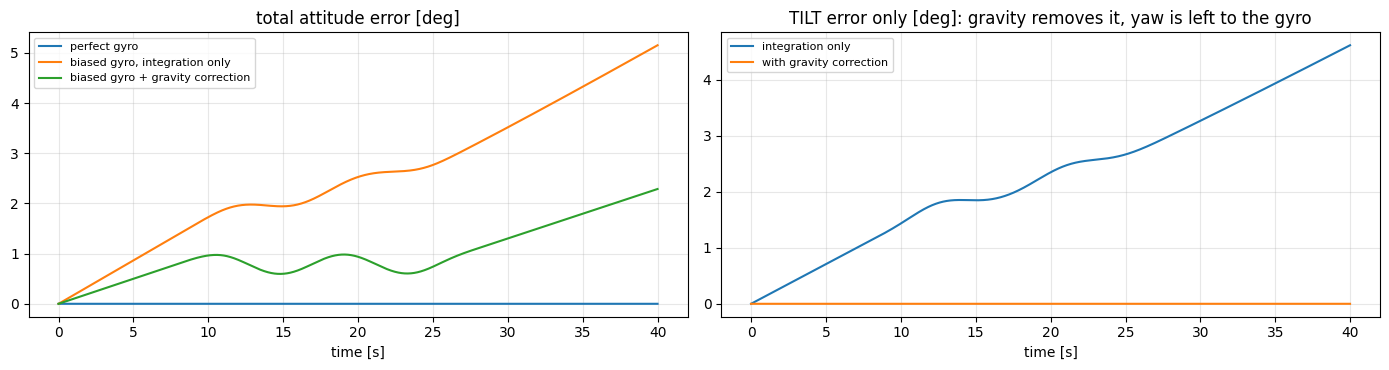

In [36]:
# ======================= Chapter 8 demo: initial attitude, integration drift, and gravity correction ===============
def geodesic_deg(Ra, Rb):
    # Angle (degrees) of the rotation that takes attitude Ra to attitude Rb (how different two orientations are).
    c = 0.5 * (np.einsum("nij,nij->n", Ra, Rb) - 1.0)
    return np.degrees(np.arccos(np.clip(c, -1.0, 1.0)))

dt = truth["dt"]; tt = truth["t"]
gB0 = truth["gB"][0]                                         # gravity as the (perfect) sensor sees it at t = 0
R0 = gravity_alignment_R(gB0)                                # initial attitude with yaw = 0
print("R0 times unit gravity =", np.round(R0 @ (gB0 / np.linalg.norm(gB0)), 6), " (must be 0,0,-1)")

# The true attitude and ours differ by a constant yaw (the 'yaw=0' convention): Y = R0 R_true(0)^T is a turn about Z.
Y = R0 @ truth["R"][0].T
print("convention yaw offset (rotation vector, deg):", np.round(np.rad2deg(Rot.from_matrix(Y).as_rotvec()), 3))
R_true_conv = np.einsum("ij,njk->nik", Y, truth["R"])         # the true attitude expressed in our yaw convention

# (a) integrate the PERFECT gyro: should follow the truth almost exactly
R_perfect = integrate_orientation(truth["wB"], R0, dt)
# (b) integrate a gyro with a small bias (0.1 deg/s on every axis): the attitude drifts
w_biased = truth["wB"] + np.deg2rad(0.1)
R_drift = integrate_orientation(w_biased, R0, dt)
# (c) same biased gyro, but correct the tilt with the (here: perfect) gravity measurement at every instant
R_fixed = gravity_corrected_orientation(R_drift, truth["gB"])

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].plot(tt, geodesic_deg(R_perfect, R_true_conv), label="perfect gyro")
ax[0].plot(tt, geodesic_deg(R_drift, R_true_conv), label="biased gyro, integration only")
ax[0].plot(tt, geodesic_deg(R_fixed, R_true_conv), label="biased gyro + gravity correction")
ax[0].set_title("total attitude error [deg]"); ax[0].legend(fontsize=8)

def tilt_err(R):                                             # angle between predicted and true gravity direction (body axes)
    pred = np.einsum("nji,j->ni", R, [0, 0, -1.0])
    tru = truth["gB"] / np.linalg.norm(truth["gB"], axis=1, keepdims=True)
    return np.degrees(np.arccos(np.clip(np.einsum("ni,ni->n", pred, tru), -1, 1)))
ax[1].plot(tt, tilt_err(R_drift), label="integration only"); ax[1].plot(tt, tilt_err(R_fixed), label="with gravity correction")
ax[1].set_title("TILT error only [deg]: gravity removes it, yaw is left to the gyro"); ax[1].legend(fontsize=8)
for a in ax: a.grid(alpha=0.3); a.set_xlabel("time [s]")
plt.tight_layout(); plt.show()

### 🔑 What we learn
* A perfect gyro integrates to the right attitude (apart from the arbitrary yaw offset we chose).
* A tiny gyro bias makes the attitude drift (left plot). Gravity *removes the tilt part* of the drift (right plot) but
  **cannot remove the yaw part** — the remaining error in the left plot is a slow heading drift. This is the fundamental
  limitation of any gravity-aided inertial system without a compass.

# Chapter 9 — A second smoother, then integration to velocity, position and angle

### 9.1 Fusing across sensors in the Earth frame
After projection every sensor has its own Earth-frame $[\mathbf a_E,\boldsymbol\omega_E]$ and covariance. They are merged at
every instant with `fuse_information` (Chapter 6). The first fused curves are labelled **"weighted fusion"** in the plots.

### 9.2 The optional second smoother (`second_rts_random_walk`)
The fused curve is still slightly jittery. A second, very simple smoother is run on the 6-vector $[\mathbf a_E,\boldsymbol\omega_E]$:

$$
\mathbf x_{k+1}=\mathbf x_k+\mathbf q_k\ \ (\text{random walk}),\qquad \mathbf y_k=\mathbf x_k+\mathbf v_k,
\qquad \operatorname{cov}(\mathbf v_k)=\rho\,P^{\text{fused}}_k,\quad \operatorname{cov}(\mathbf q_k)=\mu\,Q_k
$$

with $\rho=10$ (`r_inflation`: trust the fused data 10 times less than their nominal covariance) and $\mu=1$ (`q_scale`).
$Q_k$ is built by `fused_Q_from_individuals`: the adaptive process noises of the individual filters, rotated into Earth axes and averaged.
Then the *same* forward Kalman + backward RTS recursion as Chapters 3–4 is applied (here $F=I$, $H=I$).
⚠️ This is a **temporal regulariser**, not an exact second Bayesian smoother: the first smoother already made neighbouring
samples correlated, and those cross-time correlations are not stored. It is an engineering choice, which is why the
program shows *both* curves ("weighted fusion" and "+ second RTS").

### 9.3 Integration: from acceleration to position
Only now — after everything has been cleaned and fused — we integrate. The **trapezoid rule** adds the average of two consecutive values:
$$
\mathbf v_{k+1}=\mathbf v_k+\tfrac{\Delta t}{2}(\mathbf a_k+\mathbf a_{k+1}),\qquad
\mathbf p_{k+1}=\mathbf p_k+\tfrac{\Delta t}{2}(\mathbf v_k+\mathbf v_{k+1}),\qquad
R_{k+1}=\operatorname{Exp}\!\big(\tfrac{\boldsymbol\omega_k+\boldsymbol\omega_{k+1}}{2}\Delta t\big)\,R_k .
$$
Note the order $\operatorname{Exp}(\dots)\,R_k$ (rotation applied on the *left*): the rate is in **Earth** axes here.
The plotted `theta` is the **rotation vector** of $R_k$ (axis × angle), so it only reports angles between 0 and 180°: a 720° turn
shows up *wrapped*. To see the unwrapped 720° use the running sum of $\boldsymbol\omega_E\Delta t$ (this is what the GIFs plot).

In [37]:
def fused_Q_from_individuals(results, sensors):
    """Approximate fused process covariance for the final random-walk RTS."""
    # Number of samples.
    n = len(results[sensors[0]]["earth15"])
    # Space for one 6x6 process-noise matrix per instant.
    Q = np.zeros((n, 6, 6))
    # For every sensor...
    for s in sensors:
        # ...its stored results...
        r = results[s]
        # ...its adaptive process-noise history (body axes),
        q = r["qhist"]
        # ...its registration,
        C = r["C"]
        # ...and the orientation history.
        R = r["R_hist"]
        # Process noise of a and of w as 3x3 diagonal matrices (body axes).
        Qa_body = q[:, SL["a"], None] * np.eye(3)[None, :, :]
        # (same for w)
        Qw_body = q[:, SL["w"], None] * np.eye(3)[None, :, :]
        # For every instant...
        for k in range(n):
            # ...the rotation into Earth axes...
            T = R[k] @ C
            # ...rotate the noise matrices (T Q T^T) and add them: acceleration block...
            Q[k, :3, :3] += T @ Qa_body[k] @ T.T
            # ...and angular-rate block.
            Q[k, 3:, 3:] += T @ Qw_body[k] @ T.T
    # Divide by the number of sensors: the AVERAGE process noise.
    return Q / max(len(sensors), 1)

In [38]:
def second_rts_random_walk(y, P, Q, r_inflation=SECOND_RTS_R_INFLATION, q_scale=SECOND_RTS_Q_SCALE):
    """6-state H=I Kalman smoother with F=I random-walk dynamics."""
    # n instants, d = 6 numbers per instant (a_E and w_E).
    n, d = y.shape
    # Identity matrix.
    I = np.eye(d)
    # Measurement noise = fused covariance x r_inflation (trust the data less).
    Rm = max(float(r_inflation), 1e-12) * P
    # Process noise = Q x q_scale.
    Q = max(float(q_scale), 0.0) * Q

    # Space for the forward (filter) results.
    xf = np.empty_like(y); Pf = np.empty_like(P)
    xp = np.empty_like(y); Pp = np.empty_like(P)
    # Start from the first fused sample.
    x = y[0].copy(); Pc = P[0].copy()
    # Store the first step.
    xf[0], Pf[0], xp[0], Pp[0] = x, Pc, x, Pc

    # FORWARD pass: ordinary Kalman filter with F = I and H = I.
    for k in range(1, n):
        # Predict: the value stays the same (random walk)...
        xpred = x
        # ...and its uncertainty grows by Q.
        Ppred = Pc + Q[k]
        # Innovation covariance (H = I).
        S = Ppred + Rm[k]
        # Kalman gain.
        K = Ppred @ psd_inverse(S)
        # Update with the fused measurement.
        x = xpred + K @ (y[k] - xpred)
        # Joseph form of the covariance update.
        IK = I - K
        # New uncertainty.
        Pc = IK @ Ppred @ IK.T + K @ Rm[k] @ K.T
        # Symmetrise.
        Pc = 0.5 * (Pc + Pc.T)
        # Store everything the backward pass needs.
        xf[k], Pf[k], xp[k], Pp[k] = x, Pc, xpred, Ppred

    # BACKWARD pass (RTS): start from the filtered result.
    xs = xf.copy(); Ps = Pf.copy()
    # Walk backward in time.
    for k in range(n - 2, -1, -1):
        # Smoother gain.
        Ck = Pf[k] @ psd_inverse(Pp[k + 1])
        # Correct with the future.
        xs[k] = xf[k] + Ck @ (xs[k + 1] - xp[k + 1])
        # Smaller uncertainty.
        Ps[k] = Pf[k] + Ck @ (Ps[k + 1] - Pp[k + 1]) @ Ck.T
        # Symmetrise.
        Ps[k] = 0.5 * (Ps[k] + Ps[k].T)
    # Smoothed fused [a_E, w_E] and covariances.
    return xs, Ps

In [39]:
def integrate_navigation(aE, wE, dt):
    # Number of samples.
    n = len(aE)
    # Space for the orientation matrices, the angle vectors, velocity and position.
    R = np.empty((n, 3, 3)); theta = np.empty((n, 3))
    # Velocity and position start at zero (we only know RELATIVE motion).
    v = np.zeros((n, 3)); p = np.zeros((n, 3))
    # Orientation starts as 'no rotation yet'.
    R[0] = np.eye(3); theta[0] = 0.0
    # Step through time.
    for k in range(n - 1):
        # Average Earth-frame rotation rate over the step.
        wm = 0.5 * (wE[k] + wE[k + 1])
        # Rotate by (rate x time) about Earth axes (applied on the left).
        R[k + 1] = exp_so3(wm * dt) @ R[k]
        # theta = the accumulated rotation as a rotation vector (axis x angle; angles above 180 deg wrap).
        theta[k + 1] = Rot.from_matrix(R[k + 1]).as_rotvec()
        # Velocity: add the average acceleration x time (trapezoid rule).
        v[k + 1] = v[k] + 0.5 * dt * (aE[k] + aE[k + 1])
        # Position: add the average velocity x time.
        p[k + 1] = p[k] + 0.5 * dt * (v[k] + v[k + 1])
    # Package all results.
    return {
        "aE": aE, "wE": wE, "v": v, "p": p, "theta": theta,
        "R": R, "q_xyzw": Rot.from_matrix(R).as_quat(),
    }

In [40]:
def nav_from_projected(y15, dt):
    # Shortcut: take the first six columns [a_E, w_E] of an Earth-frame 15-state history and integrate them.
    return integrate_navigation(y15[:, :3], y15[:, 3:6], dt)

true final position  : [0. 0. 0.]
integrated position  : [-0.  0.  0.]
rotation vector theta at the end [deg] (wrapped!): [ 0. -0.  0.]
unwrapped angle about Y (sum of w dt)     [deg]: 720.0  <- the 720 degrees


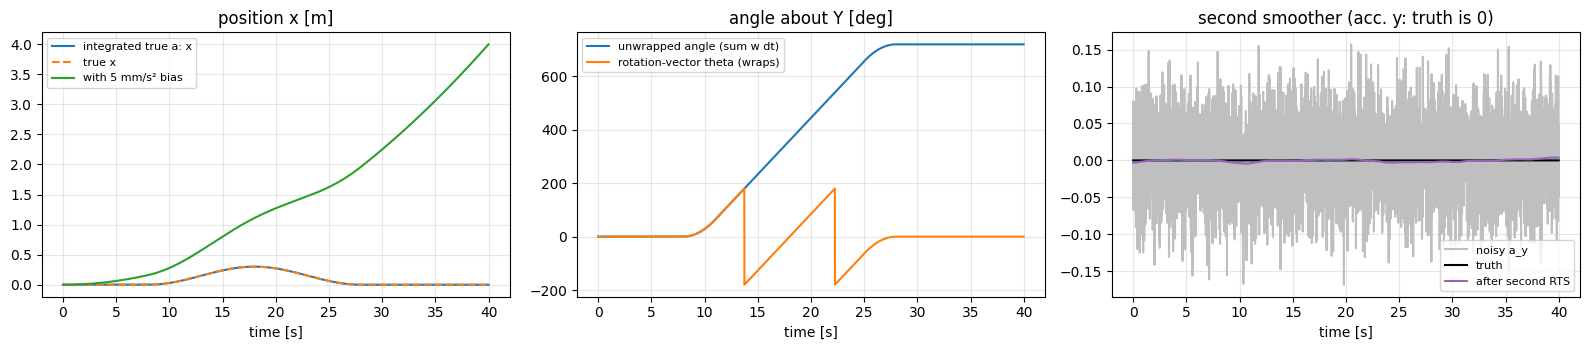

RMS error before smoothing 0.0502  after 0.0240


In [41]:
# ======================= Chapter 9 demos =======================
dt = truth["dt"]; tt = truth["t"]

# (1) integrate the TRUE Earth-frame acceleration and rotation rate: we should recover the true position and angle
nav_true = integrate_navigation(truth["aE"], truth["wE"], dt)
print("true final position  :", truth["pE"][-1].round(4))
print("integrated position  :", nav_true["p"][-1].round(4))
unwrapped = np.rad2deg(np.cumsum(truth["wE"], axis=0) * dt)
print("rotation vector theta at the end [deg] (wrapped!):", np.rad2deg(nav_true["theta"][-1]).round(2))
print("unwrapped angle about Y (sum of w dt)     [deg]:", unwrapped[-1].round(1)[1], " <- the 720 degrees")

# (2) the same integration with a tiny acceleration bias: position drifts like 0.5*b*t^2 (Chapter 1 again)
b = 0.005                                                # 5 mm/s^2 of leftover bias
nav_b = integrate_navigation(truth["aE"] + b, truth["wE"], dt)

# (3) the second smoother on a noisy fused-like signal
rng = np.random.default_rng(5)
sig = 0.05
y = np.hstack([truth["aE"], truth["wE"]]) + sig * rng.standard_normal((len(tt), 6))     # noisy 6-vector [a_E, w_E]
Pnoise = np.tile(sig**2 * np.eye(6), (len(tt), 1, 1))
Qproc = np.tile((1e-3) ** 2 * np.eye(6), (len(tt), 1, 1))
ys, _ = second_rts_random_walk(y, Pnoise, Qproc)         # uses r_inflation=10 and q_scale=1 by default

fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
ax[0].plot(tt, nav_true["p"][:, 0], label="integrated true a: x"); ax[0].plot(tt, truth["pE"][:, 0], "--", label="true x")
ax[0].plot(tt, nav_b["p"][:, 0], label="with 5 mm/s² bias"); ax[0].set_title("position x [m]"); ax[0].legend(fontsize=8)
ax[1].plot(tt, unwrapped[:, 1], label="unwrapped angle (sum w dt)"); ax[1].plot(tt, np.rad2deg(nav_true["theta"][:, 1]), label="rotation-vector theta (wraps)")
ax[1].set_title("angle about Y [deg]"); ax[1].legend(fontsize=8)
ax[2].plot(tt, y[:, 1], color="0.75", label="noisy a_y"); ax[2].plot(tt, truth["aE"][:, 1], "k", label="truth"); ax[2].plot(tt, ys[:, 1], "tab:purple", label="after second RTS")
ax[2].set_title("second smoother (acc. y: truth is 0)"); ax[2].legend(fontsize=8)
for a in ax: a.grid(alpha=0.3); a.set_xlabel("time [s]")
plt.tight_layout(); plt.show()
print("RMS error before smoothing %.4f  after %.4f" % (np.sqrt(np.mean((y[:, :6] - np.hstack([truth["aE"], truth["wE"]])) ** 2)),
                                                       np.sqrt(np.mean((ys - np.hstack([truth["aE"], truth["wE"]])) ** 2))))

### 🔑 What we learn
* Integration is exact for exact inputs. A *tiny* bias of 5 mm/s² makes the position wrong by metres after 40 s: **the quality of the
  final position is decided entirely by how well biases and gravity were removed upstream**.
* The wrapped `theta` plot saturates at ±180°, the unwrapped sum climbs to 720°. Both are correct; they are two ways of showing the same rotation.
* The second smoother cleans noise without changing the shape of the signal.

# Chapter 10 — The gravity-modulus constraint $\|\mathbf g\|=G_0$

**The physical fact.** Gravity has a fixed strength, $G_0=9.80665$ m/s². Rotating a vector never changes its length
(Chapter 2). So the *length* of the estimated gravity vector must be constant in time.

**The practical problem.** Inside the filter the gravity estimate is only *softly* tied to $G_0$ (through the pseudo-measurement
of Chapter 4), so after filtering and smoothing its length wanders slightly (typically a few thousandths of m/s², more at start-up).

**The solution used in the project.** At the very end, the *reported* gravity vectors are given exactly length $G_0$ while
keeping their direction:
$$
\mathbf g\;\longleftarrow\;G_0\,\frac{\mathbf g}{\|\mathbf g\|}.
$$
This is `constrain_gnorm`. It is applied to the **final gravity outputs only** (the Earth-frame gravity of each IMU and the
consensus), and the history of $\|\mathbf g\|$ is saved as `g_norm.png`.

### ⚠️ Why *not* feed the corrected gravity back into the filter?
We tried it, and it is instructive. The filter's gravity estimate has a **very small covariance** and is also used by the registration
(Chapter 7) and the fusion (Chapter 6), which weigh it by that covariance. Changing the length of $\mathbf g$ without changing its
covariance makes those steps see an enormous "error", which then leaks into the estimated rotation rate and can even make the filter
treat a steady rotation as bias. Constraining only the final output changes **nothing upstream**: every acceleration, velocity, position and angle
is identical with and without the constraint. The lesson: a constraint is only "free" if it is applied consistently
to the state **and** its covariance, or only to the output.

In [42]:
def constrain_gnorm(g, g0=G0):
    """Gravity-vector constraint ||g|| = G0: same direction, modulus fixed to G0.
    Applied to the final g outputs only (nothing upstream is modified)."""
    # Make sure g is an array of decimal numbers (works for one vector or a whole history).
    g = np.asarray(g, float)
    # Multiply g by (G0 / its own length): same direction, length exactly G0.
    # (`max(..., 1e-12)` only protects against dividing by zero.)
    return g * (g0 / np.maximum(np.linalg.norm(g, axis=-1, keepdims=True), 1e-12))

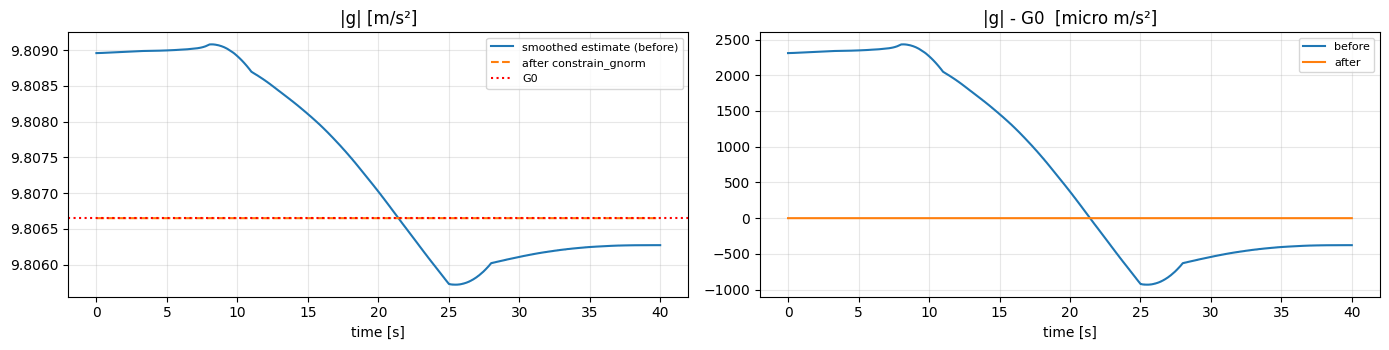

max |g|-G0 before: 2.43e-03 m/s^2;  after: 3.6e-15 m/s^2
largest change of DIRECTION caused by the constraint: 1.9e-06 degrees (it only rescales)


In [43]:
# ======================= Chapter 10 demo: |g| before and after the constraint =======================
# xs = smoothed 15-state of the simulated sensor from Chapter 5; columns 12:15 are the gravity vector (body frame).
g_raw = xs[:, SL["g"]]
g_con = constrain_gnorm(g_raw)
t = truth["t"]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
ax[0].plot(t, np.linalg.norm(g_raw, axis=1), label="smoothed estimate (before)")
ax[0].plot(t, np.linalg.norm(g_con, axis=1), "--", label="after constrain_gnorm")
ax[0].axhline(G0, color="r", ls=":", label="G0"); ax[0].set_title("|g| [m/s²]"); ax[0].legend(fontsize=8)
ax[1].plot(t, (np.linalg.norm(g_raw, axis=1) - G0) * 1e6, label="before"); ax[1].plot(t, (np.linalg.norm(g_con, axis=1) - G0) * 1e6, label="after")
ax[1].set_title("|g| - G0  [micro m/s²]"); ax[1].legend(fontsize=8)
for a in ax: a.grid(alpha=0.3); a.set_xlabel("time [s]")
plt.tight_layout(); plt.show()
ang = np.degrees(np.arccos(np.clip(np.einsum("ni,ni->n", g_raw, g_con) / np.linalg.norm(g_raw, axis=1) / G0, -1, 1)))
print(f"max |g|-G0 before: {np.abs(np.linalg.norm(g_raw,axis=1)-G0).max():.2e} m/s^2;  after: {np.abs(np.linalg.norm(g_con,axis=1)-G0).max():.1e} m/s^2")
print(f"largest change of DIRECTION caused by the constraint: {ang.max():.1e} degrees (it only rescales)")

# Chapter 11 — Reading and writing: data loading, plots

### 11.1 Reading the CSV (`infer_sensors`, `load_csv`, `get_dt`)

Expected columns for each sensor `s1, s2, ...`: `s1_acc_x [mg]`, `s1_acc_y [mg]`, `s1_acc_z [mg]`, `s1_gyro_x [dps]`, ... Other columns
(timestamps, ...) are ignored. `infer_sensors` finds the sensors automatically from the column names (so 2, 4 or 10 IMUs all work);
`load_csv` converts to SI units:

$$
\text{acc [m/s}^2] = \text{column}\times G_0\ (\text{values are in } g),\qquad \omega\,[\text{rad/s}]=\text{column [deg/s]}\times\tfrac{\pi}{180}.
$$

### ⚠️ Two classic traps (both happened in this project)

1. **The unit written in the header can lie.** In this project the accelerometer columns are *labelled* `[mg]` but contain **g**
   (a sensor at rest reads about 1, not 1000). Reading 1 g as 1 mg makes gravity 1000× too small, and the filter then
   explains the discrepancy as a huge accelerometer bias and also "absorbs" the rotation into the gyro bias. **Always check that
   the acceleration magnitude at rest is close to $G_0$ after conversion.**
2. **The sample period `dt` must be the true time between rows.** `get_dt` uses a command-line value, else `config.DT`, else
   1/104 s. If `dt` is wrong, every angle, velocity and position is scaled wrongly. A **consistency test** needs no extra
   information: the gravity direction can only turn as much as the gyro integrates. The cell below implements that test
   (it is a diagnostic written for this notebook, not part of the pipeline). It is accurate to roughly 5–10 %: use it to detect gross mistakes (such as a 4.5× error), not to fine-tune `dt`.

In [44]:
def infer_sensors(columns: Sequence[str]) -> List[str]:
    # Set of sensor names that have accelerometer columns, e.g. {'s1','s2','s3','s4'} (found by pattern matching the column names).
    acc_s = {m.group(1) for c in columns if (m := ACC_RE.match(c))}
    # Same for gyroscope columns.
    gyr_s = {m.group(1) for c in columns if (m := GYR_RE.match(c))}
    # Keep sensors that have BOTH, sorted numerically (so s10 comes after s9).
    sensors = sorted(acc_s & gyr_s, key=lambda x: int(x[1:]))
    # Nothing found -> stop with a clear message.
    if not sensors:
        raise ValueError("No complete sN accelerometer+gyro sensor groups were found")
    # Sensors that have only half of their columns.
    missing_acc = sorted(acc_s - set(sensors), key=lambda x: int(x[1:]))
    missing_gyr = sorted(gyr_s - set(sensors), key=lambda x: int(x[1:]))
    # A half-complete sensor is an error (better to stop than to guess).
    if missing_acc or missing_gyr:
        raise ValueError(f"Incomplete sensor groups: acc-only={missing_acc}, gyro-only={missing_gyr}")
    # Return the sorted list of complete sensors.
    return sensors

In [45]:
def load_csv(path: Path, nmax: Optional[int] = None):
    # Read the whole table.
    df = pd.read_csv(path)
    # Find which sensors are present.
    sensors = infer_sensors(df.columns)
    # Optionally keep only the first nmax rows (for quick tests).
    if nmax is not None:
        df = df.iloc[:nmax]
    # Dictionary: sensor name -> (acceleration array, gyro array).
    data = {}
    # For each sensor...
    for s in sensors:
        # ...the names of its 3 accelerometer columns and 3 gyro columns...
        acc_cols = [f"{s}_acc_{a} [mg]" for a in "xyz"]
        gyr_cols = [f"{s}_gyro_{a} [dps]" for a in "xyz"]
        # ...convert units: g -> m/s^2 (times G0) and degrees/s -> radians/s.
        data[s] = (
            df[acc_cols].to_numpy(float) * G0,      # column says [mg], data are g (as in ekf_run)
            np.deg2rad(df[gyr_cols].to_numpy(float)),
        )
    # All sensors must have the same number of rows: use the shortest.
    n = min(len(v[0]) for v in data.values())
    for s in sensors:
        # Cut every sensor to that length.
        data[s] = data[s][0][:n], data[s][1][:n]
    # Return the data, the sensor names and the number of samples.
    return data, sensors, n

In [46]:
def get_dt(cli_dt: Optional[float]) -> float:
    # 1) a value given explicitly always wins.
    if cli_dt is not None:
        return float(cli_dt)
    try:
        # 2) otherwise look for a local file config.py containing DT...
        import config
        # ...and use it.
        return float(getattr(config, "DT"))
    except Exception:
        # 3) otherwise fall back to 1/104 s.
        return DT_FALLBACK

In [47]:
def _time(n, dt):
    # Time axis in seconds: sample number x dt (the first sample is at t = 0).
    return np.arange(n) * dt

In [48]:
# ======================= diagnostic written for this notebook (NOT part of the pipeline) =======================
def suggest_dt(acc, gyro, dt_assumed, win_s=1.0, min_deg=3.0):
    # Compare how much the accelerometer's gravity direction turns with how much the gyro says it turned.
    # If the ratio is far from 1, dt_assumed is probably wrong; the returned value is a suggested dt.
    m = max(2, int(round(win_s / dt_assumed)))                         # window length in samples
    u = acc / np.maximum(np.linalg.norm(acc, axis=1, keepdims=True), 1e-12)   # gravity DIRECTION (unit vectors)
    ang = np.arccos(np.clip(np.einsum("ij,ij->i", u[:-m], u[m:]), -1, 1))     # angle the gravity direction turned in each window
    cs = np.r_[0.0, np.cumsum(np.linalg.norm(gyro, axis=1))]
    gyro_angle = (cs[m:] - cs[:-m])[:len(ang)] * dt_assumed            # angle the gyro integrates in the same window
    ok = gyro_angle > np.deg2rad(min_deg)                              # only windows with real motion
    factor = float(np.percentile(ang[ok] / gyro_angle[ok], 90))        # ~ dt_true / dt_assumed
    return dt_assumed * factor, factor

# test on the simulated sensor of Chapter 5 (we KNOW dt = 0.01):
for wrong in (0.01, 0.02, 0.005):
    dt_s, f = suggest_dt(acc1, gyro1, wrong)
    print(f"assumed dt = {wrong:.3f} s -> factor {f:.3f} -> suggested dt = {dt_s:.4f} s")

assumed dt = 0.010 s -> factor 1.002 -> suggested dt = 0.0100 s
assumed dt = 0.020 s -> factor 0.501 -> suggested dt = 0.0100 s
assumed dt = 0.005 s -> factor 2.003 -> suggested dt = 0.0100 s


### 11.2 The plots
Five small functions draw the PNG files. They all follow the same pattern: for each quantity ($a$, $\omega$, $v$, $p$, $\theta$, biases, gravity)
draw X, Y, Z panels with one thin line per IMU, a thick black line for the **weighted fusion**, and a dashed purple line for
**fusion + second RTS**. The dictionary `QTY` (Chapter 5) says, for each quantity, the title, the key to plot, a *display* scale (e.g. m → mm) and the unit.
Scaling is only cosmetic — stored data stay in SI units.

| Function | Draws |
|---|---|
| `plot_quantity` | a quantity in X/Y/Z for every IMU + fused curves |
| `plot_biases` | accelerometer/gyro bias of each IMU (not fused: they are calibration diagnostics) |
| `plot_fusion_comparison` | only the two fused curves (with / without second RTS), to judge the second smoother |
| `plot_norm` | the length $\|\cdot\|$ of a 3-vector (e.g. total distance from the start, total rotation) |
| `plot_gnorm` | the history of $\|\mathbf g\|$ for each IMU and the consensus |

In [49]:
def plot_quantity(path, t, sensor_results, fused_nav, fused_rts_nav, key, fused_y=None, fused_rts_y=None):
    # Look up the title, data key, display scale and unit of this quantity.
    label, field, scale, unit = QTY[key]
    # Three stacked panels (X, Y, Z) sharing the time axis.
    fig, ax = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
    # One thin line per individual IMU...
    for s, r in sensor_results.items():
        # ...scaled for display...
        x = r[field] * scale
        for j in range(3):
            ax[j].plot(t, x[:, j], lw=0.7, alpha=0.7, label=s if j == 0 else None)
    # Thick black line: the weighted fusion.
    if fused_nav is not None:
        # (Take it from the integrated navigation if available, else from the fused array.)
        xf = fused_nav[field] if field in fused_nav else fused_y
        if xf is not None:
            for j in range(3):
                ax[j].plot(t, xf[:, j] * scale, lw=2.0, color=COLORS["fused"], label="weighted fusion" if j == 0 else None)
    # Dashed purple line: fusion + second smoother.
    if fused_rts_nav is not None:
        xr = fused_rts_nav[field] if field in fused_rts_nav else fused_rts_y
        if xr is not None:
            for j in range(3):
                ax[j].plot(t, xr[:, j] * scale, lw=2.0, ls="--", color=COLORS["fused_rts"], label="weighted fusion + second RTS" if j == 0 else None)
    for j in range(3):
        ax[j].set_ylabel(f"{AXES[j]} [{unit}]")
        ax[j].grid(alpha=0.25)
    # Title and legend.
    ax[0].set_title(label)
    ax[0].legend(fontsize=8)
    ax[-1].set_xlabel("time [s]")
    fig.tight_layout()
    # Write the picture to a PNG file...
    fig.savefig(path, dpi=110)
    # ...and release the memory.
    plt.close(fig)

In [50]:
def plot_biases(path, t, sensor_results, key):
    # Title, key, scale and unit.
    label, field, scale, unit = QTY[key]
    fig, ax = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
    # One line per IMU (biases are not fused).
    for s, r in sensor_results.items():
        x = r[field] * scale
        for j in range(3):
            ax[j].plot(t, x[:, j], lw=0.75, alpha=0.75, label=s if j == 0 else None)
    for j in range(3):
        ax[j].set_ylabel(f"{AXES[j]} [{unit}]")
        ax[j].grid(alpha=0.25)
    # Title, legend, save.
    ax[0].set_title(label + " (individual IMUs)")
    ax[0].legend(fontsize=8)
    ax[-1].set_xlabel("time [s]")
    fig.tight_layout(); fig.savefig(path, dpi=110); plt.close(fig)

In [51]:
def plot_fusion_comparison(path, t, fused_nav, fused_rts_nav, key):
    # Title, key, scale and unit.
    label, field, scale, unit = QTY[key]
    fig, ax = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
    # In each axis panel draw the two fused versions on top of each other.
    for j in range(3):
        ax[j].plot(t, fused_nav[field][:, j] * scale, color=COLORS["fused"], lw=1.7, label="weighted fusion")
        if fused_rts_nav is not None:
            ax[j].plot(t, fused_rts_nav[field][:, j] * scale, color=COLORS["fused_rts"], ls="--", lw=1.8, label="weighted fusion + second RTS")
        ax[j].set_ylabel(f"{AXES[j]} [{unit}]"); ax[j].grid(alpha=0.25)
    # Title, legend, save.
    ax[0].set_title(label + " — fusion comparison")
    ax[0].legend(fontsize=8); ax[-1].set_xlabel("time [s]")
    fig.tight_layout(); fig.savefig(path, dpi=110); plt.close(fig)

In [52]:
def plot_norm(path, t, sensor_results, fused_nav, fused_rts_nav, key):
    """Plot the modulus (Euclidean norm) of a 3-vector quantity.

    Useful for position and angular position, where the norm is the natural
    scalar to compare per-IMU vs covariance-weighted fusion.
    """
    # Title, key, scale and unit.
    label, field, scale, unit = QTY[key]
    # One single panel (the length is one number per instant).
    fig, ax = plt.subplots(figsize=(15, 5))

    # Individual IMUs
    # Length of the vector for every IMU:  sqrt(x^2 + y^2 + z^2).
    for s, r in sensor_results.items():
        x = r[field] * scale
        ax.plot(t, np.linalg.norm(x, axis=1), lw=0.8, alpha=0.75, label=s)

    # Covariance-weighted fusion
    # Length of the weighted-fusion vector.
    if fused_nav is not None and field in fused_nav:
        xf = fused_nav[field] * scale
        ax.plot(t, np.linalg.norm(xf, axis=1), lw=2.2,
                color=COLORS["fused"], label="weighted fusion")

    # Fusion + second RTS
    # Length of the fusion + second RTS vector.
    if fused_rts_nav is not None and field in fused_rts_nav:
        xr = fused_rts_nav[field] * scale
        ax.plot(t, np.linalg.norm(xr, axis=1), lw=2.2, ls="--",
                color=COLORS["fused_rts"], label="weighted fusion + second RTS")

    # Labels, title, legend, save.
    ax.set_ylabel(f"|{field}| [{unit}]")
    ax.set_xlabel("time [s]")
    ax.set_title(f"{label} — modulus |{field}|")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, ncol=2)
    fig.tight_layout()
    fig.savefig(path, dpi=110)
    plt.close(fig)

In [53]:
def plot_gnorm(path, t, sensor_results, fused_g=None):
    """History of the modulus of the gravity vector |g| (per IMU, Earth-projected)."""
    # One panel.
    fig, ax = plt.subplots(figsize=(15, 5))
    # |g| of each IMU's Earth-frame gravity vector.
    for s, r in sensor_results.items():
        ax.plot(t, np.linalg.norm(r["gE"], axis=1), lw=0.9, alpha=0.8, label=s)
    # |g| of the consensus gravity.
    if fused_g is not None:
        ax.plot(t, np.linalg.norm(fused_g, axis=1), lw=2.0, ls="--", color=COLORS["fused"],
                label="consensus")
    # Red dotted reference line at G0.
    ax.axhline(G0, color="r", ls=":", lw=1.2, label=f"G0 = {G0:.5f}")
    ax.set_ylabel(r"$|g|$ [m/s$^2$]"); ax.set_xlabel("time [s]")
    ax.set_title("gravity vector — modulus |g|")
    ax.grid(alpha=0.25); ax.legend(fontsize=8, ncol=3)
    # Save the picture.
    fig.tight_layout(); fig.savefig(path, dpi=110); plt.close(fig)

# Chapter 12 — The animated GIFs (IMU vs. fused, seen from the Earth)

For every IMU the program writes one GIF that compares **that IMU alone** (solid, colour) with the **final fused result** (dashed).
All quantities are the Earth-frame estimates behind the PNG plots — nothing new is computed for the animation.

| Panel | What you see |
|---|---|
| **Left (big)** | the trajectory $\mathbf p(t)$ in Earth axes X, Y, Z (a trail), and at the current position a small plate with the body's x/y/z axes (red/green/blue), oriented by the current attitude |
| **Top right** | the *rotation alone*: both plates at a common pivot with the Earth axes, so rotations are easy to read |
| **Middle right** | position X/Y/Z versus time with a moving cursor |
| **Bottom right** | cumulative rotation $\int\boldsymbol\omega_E\,dt$ (unwrapped, so 720° really reads 720°) |

**Attitude used for the plates.** The pipeline integrates the Earth-frame rate from the identity ("no rotation yet"), so the *relative*
rotation is $R_{rel}(k)$. To get the sensor's *absolute* attitude we multiply by the starting attitude: $R_{abs}(k)=R_{rel}(k)\,R_{abs}(0)$
with $R_{abs}(0)=R_{hist}[0]\,C_i$ (sensor → Earth at $t=0$). The fused track uses the same start so the comparison is fair.

**Frame choice.** Frames are not equally spaced in time. They are equally spaced in "how much happened": rotation angle travelled + distance travelled + a small time term.
So fast motions look smooth and still periods are fast-forwarded (the title shows the playback speed).

In [54]:
# ======================= constants and imports of the GIF module (imu_gifs.py) =======================
from matplotlib.animation import FuncAnimation, PillowWriter     # tools that turn a function into an animation / GIF file
from mpl_toolkits.mplot3d.art3d import Poly3DCollection          # lets us draw filled 3-D polygons (the 'plate')

AX_COL = ("tab:red", "tab:green", "tab:blue")      # colours of the body x, y, z axes
FPS = 20                                           # frames per second of the GIF
MAX_FRAMES = 36                                    # NOTE: the project uses 220 frames; reduced here so the demo runs quickly
DPI = 70                                           # picture resolution of the GIF
GIF_COLORS = ("tab:orange", "tab:blue", "tab:green", "tab:red", "tab:brown", "tab:pink", "tab:olive", "tab:cyan")   # one colour per IMU

In [55]:
def frame_indices(w, p, dt, max_frames=MAX_FRAMES, rest=0.15):
    """Frames equally spaced in (angle travelled + distance travelled + a small time
    term): smooth motion while moving, fast-forward while still."""
    # Size of the angular rate at every instant...
    wn = np.linalg.norm(w, axis=1)
    # ...and the speed (how fast the position changes).
    sp = np.linalg.norm(np.gradient(p, dt, axis=0), axis=1)
    # 'Activity' = rate/typical rate + speed/typical speed + a small constant (so still periods are not skipped entirely).
    r = wn / max(np.percentile(wn, 95), 1e-12) + sp / max(np.percentile(sp, 95), 1e-12) + rest
    # Accumulate the activity over time (trapezoid rule): s = total 'amount of happenings' so far.
    s = np.concatenate([[0.0], np.cumsum(0.5 * (r[1:] + r[:-1]) * dt)])
    # Choose max_frames instants equally spaced in s (not in time).
    idx = np.unique(np.clip(np.searchsorted(s, np.linspace(0.0, s[-1], max_frames)), 0, len(p) - 1))
    # Always include the very last sample.
    if idx[-1] != len(p) - 1:
        idx = np.append(idx, len(p) - 1)
    # The list of sample numbers that become frames.
    return idx

In [56]:
def _plate(R, center, half):
    # Geometry of the little plate that stands for the sensor: 6 faces of a thin box.
    # Half-sizes of the plate along its own x, y, z axes.
    sx, sy, sz = half
    # The 8 corners of the little box, in the body's own axes.
    v = np.array([[x, y, z] for x in (-sx, sx) for y in (-sy, sy) for z in (-sz, sz)])
    # Rotate the corners by the attitude R and move them to the centre position.
    v = center + v @ R.T
    # Return the 6 faces (each a list of 4 corners) for drawing.
    return [v[list(q)] for q in [(0, 1, 3, 2), (4, 5, 7, 6), (0, 1, 5, 4),
                                  (2, 3, 7, 6), (0, 2, 6, 4), (1, 3, 7, 5)]]

In [57]:
def geodesic_deg(Ra, Rb):
    # How different are two orientations? (an angle in degrees)
    # For two rotations, trace(Ra^T Rb) = 1 + 2 cos(angle between them)...
    c = 0.5 * (np.einsum("nij,nij->n", Ra, Rb) - 1.0)
    # ...so this is the angle (in degrees) of the rotation that takes Ra into Rb.
    return np.degrees(np.arccos(np.clip(c, -1.0, 1.0)))

In [58]:
def make_imu_dynamics_gif(path, sensor, dt, imu, fused, imu_color="tab:orange",
                          fused_color="black", fused_label="fused"):
    # Number of samples; time axis.
    n = len(imu["R"])
    t = np.arange(n) * dt
    # Two 'tracks' to compare: the single IMU and the fused result. Each has attitude R, position p, rate w.
    T = {"imu": imu, "fused": fused}
    # Colours and labels of the two tracks.
    col = {"imu": imu_color, "fused": fused_color}
    lab = {"imu": sensor, "fused": fused_label}
    # Attitude matrices of the two tracks.
    R = {k: np.asarray(v["R"], float) for k, v in T.items()}
    # Positions, converted from metres to millimetres.
    P = {k: np.asarray(v["p"], float) * 1e3 for k, v in T.items()}                 # mm
    # Cumulative rotation = running sum of (rate x dt), in degrees (unwrapped).
    TH = {k: np.degrees(np.cumsum(np.asarray(v["w"], float), axis=0) * dt) for k, v in T.items()}
    # Angle between the two attitudes at every instant.
    diff = geodesic_deg(R["imu"], R["fused"])
    # Which samples become animation frames.
    idx = frame_indices(np.asarray(fused["w"], float), np.asarray(fused["p"], float), dt)

    # cubic axis box around both trajectories
    # Size of the 3-D box: it must contain both trajectories...
    allp = np.concatenate([P["imu"], P["fused"]])
    lo, hi = allp.min(0), allp.max(0)
    ctr = 0.5 * (lo + hi)
    # ...(at least 1 mm so a motionless sensor does not give a zero-size box).
    half = max(0.6 * float(np.max(hi - lo)), 1.0)                                  # >= 1 mm
    # Size of the plate relative to the box.
    body = (0.10 * half, 0.06 * half, 0.012 * half)                                # plate half-sizes
    # Length of the drawn body axes.
    Lax = 0.16 * half                                                              # body-axis length

    # Create the picture and its layout: a big 3-D panel on the left, a small 3-D panel and two plots on the right.
    fig = plt.figure(figsize=(14.5, 8.2))
    gs = fig.add_gridspec(3, 2, width_ratios=[1.3, 1.0], height_ratios=[1.25, 0.8, 0.8],
                          hspace=0.55, wspace=0.10, left=0.01, right=0.985, top=0.93, bottom=0.06)
    ax = fig.add_subplot(gs[:, 0], projection="3d")
    axr = fig.add_subplot(gs[0, 1], projection="3d")
    axp = fig.add_subplot(gs[1, 1])
    axt = fig.add_subplot(gs[2, 1])
    # A title that will show the time and playback speed.
    title = fig.suptitle("", fontsize=12, weight="bold", family="monospace", x=0.01, ha="left")

    # ---- trajectory view
    # Left panel: axis limits (a cube around the data), labels and viewing angle.
    ax.set_xlim(ctr[0] - half, ctr[0] + half); ax.set_ylim(ctr[1] - half, ctr[1] + half)
    ax.set_zlim(ctr[2] - half, ctr[2] + half); ax.set_box_aspect((1, 1, 1))
    ax.set_xlabel("X [mm]"); ax.set_ylabel("Y [mm]"); ax.set_zlabel("Z [mm] (up)")
    ax.view_init(elev=22, azim=-58)
    # Gold star at the start position.
    ax.plot([P["imu"][0, 0]], [P["imu"][0, 1]], [P["imu"][0, 2]], marker="*", ms=12,
            color="gold", mec="k", ls="none", label="start")
    # 'Artists' = the drawn objects that will be moved at every frame.
    art = {}
    # For each of the two tracks create: a trail line, a head dot, the plate and the 3 body axes.
    for k in T:
        trail, = ax.plot([], [], [], color=col[k], lw=1.8 if k == "imu" else 1.4,
                         ls="-" if k == "imu" else "--", label=lab[k])
        head, = ax.plot([], [], [], marker="o", ms=5, color=col[k], ls="none")
        faces = Poly3DCollection(_plate(np.eye(3), np.zeros(3), body), facecolors=col[k],
                                 edgecolors=col[k] if k == "imu" else "k",
                                 alpha=0.35 if k == "imu" else 0.15, linewidths=1.0)
        ax.add_collection3d(faces)
        axes = [ax.plot([], [], [], color=AX_COL[j], lw=2.6 if k == "imu" else 1.4,
                        ls="-" if k == "imu" else "--")[0] for j in range(3)]
        art[k] = dict(trail=trail, head=head, faces=faces, axes=axes)
    # Legend.
    ax.legend(loc="upper left", fontsize=8)

    # ---- rotation view (common pivot)
    # Top-right panel: a unit cube with Earth axes X, Y, Z drawn as dotted lines.
    axr.set_xlim(-1, 1); axr.set_ylim(-1, 1); axr.set_zlim(-1, 1); axr.set_box_aspect((1, 1, 1))
    axr.view_init(elev=20, azim=-58)
    axr.set_xticklabels([]); axr.set_yticklabels([]); axr.set_zticklabels([])
    axr.set_title("rotation in Earth frame (common pivot)   body axes x/y/z = red/green/blue",
                  fontsize=8.5, pad=-4)
    for e, txt in zip(np.eye(3), "XYZ"):
        axr.plot([0, 1.0 * e[0]], [0, 1.0 * e[1]], [0, 1.0 * e[2]], color="0.4", lw=1.0, ls=":")
        axr.text(*(1.1 * e), txt, color="0.25", fontsize=9)
    # Again the artists, this time for the rotation-only view.
    rart = {}
    # Plate and three body axes for each track, at the pivot.
    for k in T:
        faces = Poly3DCollection(_plate(np.eye(3), np.zeros(3), (0.5, 0.32, 0.06)),
                                 facecolors=col[k], edgecolors=col[k] if k == "imu" else "k",
                                 alpha=0.30 if k == "imu" else 0.12, linewidths=1.0)
        axr.add_collection3d(faces)
        axes = [axr.plot([], [], [], color=AX_COL[j], lw=3.0 if k == "imu" else 1.5,
                         ls="-" if k == "imu" else "--")[0] for j in range(3)]
        rart[k] = dict(faces=faces, axes=axes)

    # ---- time histories
    # Lines of the two time-history plots (they will be extended frame by frame).
    prog = {}
    # Small helper that sets labels and title of a time plot.
    def style(a, yl, ttl):
        a.set_ylabel(yl, fontsize=8); a.set_title(ttl, fontsize=8.5, loc="left", pad=2)
        a.grid(alpha=0.25); a.tick_params(labelsize=7); a.set_xlim(t[0], t[-1])
    # Middle-right: position; bottom-right: cumulative rotation.
    style(axp, "mm", "position p  (x/y/z = red/green/blue, solid = IMU, dashed = fused)")
    style(axt, "deg", "cumulative rotation  ∫ω_E dt  (x/y/z = red/green/blue)")
    # Draw the complete histories faintly (the 'future'), and prepare bold lines for the 'past'.
    for a, D, name in ((axp, P, "p"), (axt, TH, "t")):
        for k in T:
            for j in range(3):
                a.plot(t, D[k][:, j], color=AX_COL[j], lw=2.0 if k == "imu" else 1.2,
                       ls="-" if k == "imu" else "--", alpha=0.25)
                prog[(name, k, j)] = a.plot([], [], color=AX_COL[j], lw=2.0 if k == "imu" else 1.2,
                                            ls="-" if k == "imu" else "--")[0]
    # Time label.
    axt.set_xlabel("time [s]", fontsize=8)
    # Vertical black line that marks the current time.
    cursors = [axp.axvline(0, color="k", lw=0.9), axt.axvline(0, color="k", lw=0.9)]

    # Helper: set a 3-D line from point a to point b.
    def setline(ln, a, b):
        ln.set_data([a[0], b[0]], [a[1], b[1]]); ln.set_3d_properties([a[2], b[2]])

    # UPDATE: this function redraws everything for frame number fi (it is called once per frame).
    def update(fi):
        # kk = the sample number shown in this frame.
        kk = int(idx[fi])
        # Playback speed for the title (simulated seconds per real second).
        sp = (t[idx[fi + 1]] - t[kk]) * FPS if fi + 1 < len(idx) else 0.0
        # Write time and speed in the title.
        title.set_text(f"{sensor} vs {fused_label}   t = {t[kk]:6.2f} s   playback x{sp:.1f}")
        # Which past samples to draw (thinned out if there are very many).
        sl = slice(0, kk + 1, max(1, kk // 1500 + 1))
        # For each track:
        for k in T:
            # its attitude and position now,
            Rk = R[k][kk]; pk = P[k][kk]; a = art[k]
            seg = P[k][sl]
            # extend the trail,
            a["trail"].set_data(seg[:, 0], seg[:, 1]); a["trail"].set_3d_properties(seg[:, 2])
            a["head"].set_data([pk[0]], [pk[1]]); a["head"].set_3d_properties([pk[2]])
            # move and rotate the plate,
            a["faces"].set_verts(_plate(Rk, pk, body))
            # do the same in the rotation-only view,
            r = rart[k]
            r["faces"].set_verts(_plate(Rk, np.zeros(3), (0.5, 0.32, 0.06)))
            # re-aim the three body axes,
            # and extend the position and angle histories.
            for j in range(3):
                setline(a["axes"][j], pk, pk + Lax * Rk[:, j])
                setline(r["axes"][j], np.zeros(3), 0.85 * Rk[:, j])
            for j in range(3):
                prog[("p", k, j)].set_data(t[sl], P[k][sl, j])
                prog[("t", k, j)].set_data(t[sl], TH[k][sl, j])
        # Move the time cursor.
        for c in cursors:
            c.set_xdata([t[kk], t[kk]])
        # (nothing else to report)
        return []

    # Ask matplotlib to call `update` once per frame...
    ani = FuncAnimation(fig, update, frames=len(idx), blit=False)
    # ...and write the frames to a GIF file.
    ani.save(str(path), writer=PillowWriter(fps=FPS), dpi=DPI)
    # Release the memory.
    plt.close(fig)

In [59]:
# The project keeps the GIF code in its own file, imu_gifs.py, and run_general_multisensor_dynamic.py does
#     from imu_gifs import make_imu_dynamics_gif
# Here the same function lives in this notebook, so we register it under that module name; then the
# pipeline code below runs UNCHANGED.
_gif_module = types.ModuleType("imu_gifs")
_gif_module.make_imu_dynamics_gif = make_imu_dynamics_gif
sys.modules["imu_gifs"] = _gif_module

In [60]:
def make_dynamics_gifs(file_out, sensors, results, nav_f, nav_rts, dt):
    """One GIF per IMU: IMU estimate vs final fused estimate, Earth frame.
    Attitude R_abs(k) = R_rel(k) @ R_abs(0) with R_rel the integrated Earth angular
    rate (same as `theta`) and R_abs(0) = R_hist[0] @ C (sensor -> Earth at t0)."""
    # Get the drawing function (see the registration cell above).
    from imu_gifs import make_imu_dynamics_gif
    # The 'final fused' track: fusion + second RTS if it was computed, otherwise the plain fusion.
    nav_fin = nav_rts if nav_rts is not None else nav_f
    # Label and colour for that track.
    fused_label = "fused + 2nd RTS" if nav_rts is not None else "fused"
    # (colour)
    fused_color = COLORS["fused_rts"] if nav_rts is not None else COLORS["fused"]
    # Folder 'gifs' inside the output folder.
    gif_dir = file_out / "gifs"; gif_dir.mkdir(exist_ok=True)
    # One GIF per sensor.
    for i, s in enumerate(sensors):
        # Starting absolute attitude of this sensor: R_abs(0) = R_hist[0] x C.
        R0s = results[s]["R_hist"][0] @ results[s]["C"]
        # This sensor's own navigation result.
        nav = results[s]["nav"]
        # Track of the single IMU: absolute attitude = relative rotation x starting attitude.
        imu = dict(R=nav["R"] @ R0s, p=nav["p"], w=nav["wE"])
        # Track of the fused result, expressed on THIS sensor's body axes with the same start.
        fus = dict(R=nav_fin["R"] @ R0s, p=nav_fin["p"], w=nav_fin["wE"])
        # File name of the GIF.
        out = gif_dir / f"dynamics_{s}_vs_fused.gif"
        # Draw and save the animation.
        make_imu_dynamics_gif(out, s, dt, imu, fus, imu_color=GIF_COLORS[i % len(GIF_COLORS)],
                              fused_color=fused_color, fused_label=fused_label)
        # Report progress.
        print(f"  saved {out.name}", flush=True)

# Chapter 13 — Putting it all together: `process_file`

`process_file` is the conductor: it calls every function we have studied, in this order.

| # | What it does | Chapter |
|---|---|---|
| 1 | read the CSV and convert units | 11 |
| 2 | for each IMU: noise settings → start values from the still interval → adaptive EKF → RTS smoother | 4–5 |
| 3 | register all IMUs to sensor 1 (Wahba, leave-one-out) | 7 |
| 4 | consensus gravity & rate in sensor 1's axes; initial attitude (yaw = 0); integrate the rate | 7–8 |
| 5 | per IMU: gravity-corrected attitude $R_{hist}$, then project the whole state to the Earth with its covariance; integrate that IMU alone | 8–9 |
| 6 | fuse all IMUs in the Earth frame (information fusion); integrate | 6, 9 |
| 7 | optional second smoother on the fused curve; integrate | 9 |
| 8 | write plots (with the $\|\mathbf g\|=G_0$ output constraint), diagnostics, `results.npz`, the GIFs, a summary CSV | 10–12 |

The function arguments are the *knobs* of the pipeline:

| Argument | Meaning |
|---|---|
| `dt` | time between rows [s] (Chapter 11) |
| `align_s` | length of the initial **still** interval used for start values [s]. *Must be shorter than the real still period!* |
| `second_rts`, `r_inflation`, `q_scale` | switch/tuning of the second smoother (Chapter 9) |
| `registration_stride` | use every n-th sample for registration (speed) |
| `active_thr_dps` | diagnostic "is moving" threshold |
| `nmax` | process only the first n rows (quick tests) |
| `registration_refine_iters` | leave-one-out sweeps (3 or more IMUs) |

In [61]:
def process_file(path: Path, out_root: Path, dt: float, align_s: float,
                 second_rts: bool, r_inflation: float, q_scale: float,
                 registration_stride: int, active_thr_dps: float,
                 nmax: Optional[int], registration_refine_iters: int = 2):
    # 1) READ the file; sensors = the list of IMU names found, n = number of samples.
    data, sensors, n = load_csv(path, nmax=nmax)
    # Create an output folder named after the file.
    file_out = out_root / path.stem
    file_out.mkdir(parents=True, exist_ok=True)

    # Dictionaries that will hold, per sensor: smoothed states, covariances, noise histories, raw data, settings.
    xs = {}; Ps = {}; qhist = {}; raw_acc = {}; raw_gyro = {}; cfgs = {}
    print(f"\n=== {path.name}: {n} samples, {len(sensors)} IMUs ({', '.join(sensors)}) ===", flush=True)

    # 2) FOR EACH IMU, run the filter alone:
    for s in sensors:
        # its accelerometer and gyro data (SI units);
        acc, gyro = data[s]
        # its noise settings (priors + noise measured from the first seconds);
        cfg = make_cfg(acc, gyro, dt)
        # number of samples in the initial still interval;
        na = max(1, min(n, int(round(align_s / dt))))
        # start values from the still interval (gravity direction, biases);
        x0 = AEKFRTS.stationary_initial_state(acc[:na].mean(0), gyro[:na].mean(0), cfg.G0)
        # create the filter;
        ekf = AEKFRTS(cfg, x0)
        # forward Kalman pass + backward RTS pass;
        out = ekf.run(acc, gyro, do_smooth=True)
        # keep the smoothed states and covariances...
        xs[s] = out["xs"]
        Ps[s] = out["Ps"]
        # ...and the history of the adaptive process noise;
        qhist[s] = np.asarray(out["qhist"])
        # keep the raw data for later diagnostics.
        raw_acc[s] = acc
        raw_gyro[s] = gyro
        cfgs[s] = cfg
        print(f"  finished AEKF+RTS {s}", flush=True)

    # 3) REGISTRATION: the rotation C of every sensor into sensor 1's axes (Wahba problem).
    C, active_mask, reg_stats = register_sensors(
        xs, Ps, sensors, stride=registration_stride, active_thr_dps=active_thr_dps,
        refine_iters=registration_refine_iters,
    )
    # Print how well each registration is determined (1-sigma in degrees).
    for s in sensors[1:]:
        print(f"  registration {s}->{sensors[0]}: 1-sigma [deg] = "
              f"{np.array2string(reg_stats[s]['sigma_deg'], precision=3)}", flush=True)
    # 4) CONSENSUS: fuse the gravity and rate of all IMUs in sensor 1's axes.
    g_cons, w_cons, P_cons = consensus_body_history(xs, Ps, C, sensors)
    # Initial attitude from the consensus gravity (yaw = 0 convention).
    R0 = gravity_alignment_R(g_cons[0])  # yaw(t=0)=0 convention
    # Integrate the consensus rate: an orientation that is right in yaw but drifts in tilt.
    R_base = integrate_orientation(w_cons, R0, dt)

    # Per-IMU results container.
    results = {}
    # 5) FOR EACH IMU, go to the Earth frame:
    for s in sensors:
        # this sensor's gravity expressed in sensor 1's axes;
        g_ref = np.einsum("ij,nj->ni", C[s], xs[s][:, SL["g"]])
        # tilt-corrected orientation history;
        R_hist = gravity_corrected_orientation(R_base, g_ref)
        # rotate the 15-state and its covariance into Earth axes;
        Y15, P15 = project_earth_with_cov(xs[s], Ps[s], C[s], R_hist, G0)
        # integrate THIS sensor alone: velocity, position, angle;
        nav = nav_from_projected(Y15, dt)
        # store everything (gravity gets the |g| = G0 output constraint).
        results[s] = {
            "xs": xs[s], "Ps": Ps[s], "qhist": qhist[s], "C": C[s],
            "R_hist": R_hist, "earth15": Y15, "earthP15": P15,
            "aE": Y15[:, 0:3], "wE": Y15[:, 3:6],
            "baE": Y15[:, 6:9], "bwE": Y15[:, 9:12], "gE": constrain_gnorm(Y15[:, 12:15]),
            "aE_P": P15[:, 0:3, 0:3], "wE_P": P15[:, 3:6, 3:6],
            "nav": nav,
            "raw_acc": raw_acc[s], "raw_gyro": raw_gyro[s],
        }
        print(f"  projected Earth frame {s}", flush=True)

    # 6) FUSION in the Earth frame: stack every IMU's [a_E, w_E]...
    Y = np.stack([results[s]["earth15"][:, 0:6] for s in sensors])
    # ...and their covariances...
    P = np.stack([results[s]["earthP15"][:, 0:6, 0:6] for s in sensors])
    # ...and fuse them (information form).
    y_f, p_f = fuse_information(Y, P)
    # Integrate the fused result: velocity, position, angle.
    nav_f = integrate_navigation(y_f[:, :3], y_f[:, 3:6], dt)

    # 7) SECOND SMOOTHER (optional):
    y_rts = p_rts = nav_rts = None
    # (only if switched on)
    if second_rts:
        # average process noise of the IMUs in Earth axes;
        Q = fused_Q_from_individuals(results, sensors)
        # smooth the fused curve;
        y_rts, p_rts = second_rts_random_walk(
            y_f, p_f, Q, r_inflation=r_inflation, q_scale=q_scale
        )
        # integrate it.
        nav_rts = integrate_navigation(y_rts[:, :3], y_rts[:, 3:6], dt)

    # 8) OUTPUTS. Time axis;
    t = _time(n, dt)
    # data dictionary for the plot functions;
    sensor_plot = {s: {
        "aE": results[s]["aE"], "wE": results[s]["wE"],
        "baE": results[s]["baE"], "bwE": results[s]["bwE"], "gE": results[s]["gE"],
        "v": results[s]["nav"]["v"], "p": results[s]["nav"]["p"], "theta": results[s]["nav"]["theta"],
    } for s in sensors}

    # Plots: all requested quantities in Earth frame. Biases are individual-only.
    # one plot (+ fusion comparison) for each of: acceleration, rate, velocity, position, angle;
    for q in ("a", "w", "v", "p", "theta"):
        plot_quantity(file_out / f"{q}.png", t, sensor_plot, nav_f, nav_rts, q,
                      fused_y=y_f, fused_rts_y=y_rts)
        plot_fusion_comparison(file_out / f"{q}_fusion_compare.png", t, nav_f, nav_rts, q)
        # Modulus plots for position and angular position (per-IMU vs fused).
    # plots of the length of position and angle;
    for q in ("p", "theta"):
        plot_norm(file_out / f"{q}_norm.png", t, sensor_plot,
                  nav_f, nav_rts, q)
        plot_norm(file_out / f"{q}_norm_fusion_compare.png", t, {}, nav_f, nav_rts, q)
    # bias and gravity plots;
    for q in ("ba", "bw", "g"):
        plot_biases(file_out / f"{q}.png", t, sensor_plot, q)
    # history of |g| (with the output constraint);
    plot_gnorm(file_out / "g_norm.png", t, sensor_plot, constrain_gnorm(g_cons))

    # Additional diagnostics directly at the filter output, before registration.
    # diagnostics table: raw gyro vs estimated rate, registration uncertainty;
    diag_rows = []
    for s in sensors:
        w_raw = raw_gyro[s]
        w_est = xs[s][:, SL["w"]]
        raw_rms = np.sqrt(np.mean(np.sum(w_raw * w_raw, axis=1)))
        est_rms = np.sqrt(np.mean(np.sum(w_est * w_est, axis=1)))
        diag_rows.append({
            "file": path.name, "sensor": s,
            "raw_gyro_rms_dps": np.rad2deg(raw_rms),
            "aekf_rts_w_rms_dps": np.rad2deg(est_rms),
            "aekf_rts_w_max_dps": np.rad2deg(np.max(np.linalg.norm(w_est, axis=1))),
            "registration_sigma_max_deg": reg_stats[s]["sigma_max_deg"],
        })
    # save it as filter_diagnostic.csv;
    pd.DataFrame(diag_rows).to_csv(file_out / "filter_diagnostic.csv", index=False)

    # Save compact output for downstream analysis.
    # pack the main arrays...
    save_dict = {"t": t, "sensors": np.array(sensors, dtype=object), "R0": R0,
                 "g_consensus_B": g_cons, "w_consensus_B": w_cons, "P_consensus_gw_B": P_cons,
                 "active_mask": active_mask, "y_fused": y_f, "P_fused": p_f}
    if y_rts is not None:
        save_dict.update({"y_fused_rts": y_rts, "P_fused_rts": p_rts})
    for s in sensors:
        r = results[s]
        save_dict.update({
            f"{s}_xf": np.asarray(r["xs"]),
            f"{s}_Pf": np.asarray(r["Ps"]),
            f"{s}_C": r["C"], f"{s}_C_cov_rad2": reg_stats[s]["cov"], f"{s}_R_hist": r["R_hist"],
            f"{s}_earth15": r["earth15"], f"{s}_earthP15": r["earthP15"],
            f"{s}_aE": r["aE"], f"{s}_wE": r["wE"],
            f"{s}_baE": r["baE"], f"{s}_bwE": r["bwE"], f"{s}_gE": r["gE"],
            f"{s}_v": r["nav"]["v"], f"{s}_p": r["nav"]["p"], f"{s}_theta": r["nav"]["theta"],
        })
    save_dict.update({
        "a_fused": nav_f["aE"], "w_fused": nav_f["wE"], "v_fused": nav_f["v"],
        "p_fused": nav_f["p"], "theta_fused": nav_f["theta"],
    })
    if nav_rts is not None:
        save_dict.update({
            "a_fused_rts": nav_rts["aE"], "w_fused_rts": nav_rts["wE"],
            "v_fused_rts": nav_rts["v"], "p_fused_rts": nav_rts["p"], "theta_fused_rts": nav_rts["theta"],
        })
    # ...and save them in results.npz;
    np.savez_compressed(file_out / "results.npz", **save_dict)

    # write the animated GIFs (Chapter 12);
    make_dynamics_gifs(file_out, sensors, results, nav_f, nav_rts, dt)

    # One-line numerical summary useful for batch runs.
    # one-line numerical summary of the run...
    summary = {
        "file": path.name, "n_samples": n, "n_imus": len(sensors), "dt_s": dt,
        "duration_s": (n - 1) * dt,
        "fused_a_rms_mps2": float(np.sqrt(np.mean(np.sum(nav_f["aE"]**2, axis=1)))),
        "fused_w_rms_dps": float(np.rad2deg(np.sqrt(np.mean(np.sum(nav_f["wE"]**2, axis=1))))),
        "fused_v_end_mmps": float(1e3 * np.linalg.norm(nav_f["v"][-1])),
        "fused_p_end_mm": float(1e3 * np.linalg.norm(nav_f["p"][-1])),
        "fused_theta_end_mdeg": float(np.rad2deg(1e3 * np.linalg.norm(nav_f["theta"][-1]))),
        "second_rts": bool(second_rts),
    }
    if nav_rts is not None:
        summary.update({
            "fused_rts_a_rms_mps2": float(np.sqrt(np.mean(np.sum(nav_rts["aE"]**2, axis=1)))),
            "fused_rts_w_rms_dps": float(np.rad2deg(np.sqrt(np.mean(np.sum(nav_rts["wE"]**2, axis=1))))),
            "fused_rts_v_end_mmps": float(1e3 * np.linalg.norm(nav_rts["v"][-1])),
            "fused_rts_p_end_mm": float(1e3 * np.linalg.norm(nav_rts["p"][-1])),
            "fused_rts_theta_end_mdeg": float(np.rad2deg(1e3 * np.linalg.norm(nav_rts["theta"][-1]))),
        })
    # ...saved as summary.csv;
    pd.DataFrame([summary]).to_csv(file_out / "summary.csv", index=False)
    print(f"  saved {file_out}", flush=True)
    # done.
    return summary

# Chapter 14 — A complete run on simulated data, checked against the truth

We now run **the whole pipeline** on a CSV that we generate ourselves: **four IMUs** glued to the same moving object with
**different mountings**, **different biases** and **noise**. The object rotates 720° about Earth's Y axis and moves a little.
Because we know the truth we can *grade* the answer.

The simulated CSV follows the project's conventions: columns named `s1_acc_x [mg]` ... that actually contain **g**, and `s1_gyro_x [dps]`.

In [62]:
# ======================= build a simulated 4-IMU CSV file (teaching tool) =======================
import tempfile, os
rng = np.random.default_rng(42)
truth = simulate_motion()                      # same motion as before (40 s, 720 deg about Earth Y)

mounts = [np.eye(3),                                                    # s1: the reference sensor
          Rot.from_euler("xyz", [10, -20, 35], degrees=True).as_matrix(),   # s2: some random mounting rotations
          Rot.from_euler("xyz", [-25, 5, 70], degrees=True).as_matrix(),    # s3
          Rot.from_euler("xyz", [30, 40, -50], degrees=True).as_matrix()]   # s4
cols = {}
for i, C_m in enumerate(mounts, start=1):
    ba = rng.normal(0, 0.02, 3)                                         # each sensor gets its own random biases
    bw = np.deg2rad(rng.normal(0, 0.15, 3))
    acc, gyro = make_imu(truth, C=C_m, ba=ba, bw=bw, rng=rng)           # what that sensor would output
    for j, ax_name in enumerate("xyz"):
        cols[f"s{i}_acc_{ax_name} [mg]"] = acc[:, j] / G0               # project convention: header says mg, values are g
        cols[f"s{i}_gyro_{ax_name} [dps]"] = np.rad2deg(gyro[:, j])
sim_dir = Path(tempfile.mkdtemp(prefix="imu_sim_"))
sim_csv = sim_dir / "simulated_720deg.csv"
pd.DataFrame(cols).to_csv(sim_csv, index=False)
print("wrote", sim_csv, "| columns:", len(cols), "| rows:", len(truth["t"]))
print("acceleration magnitude at rest (should be ~1 g):", np.linalg.norm([cols[f's1_acc_{a} [mg]'][:100].mean() for a in 'xyz']).round(4))

wrote /tmp/imu_sim_h7zrur_s/simulated_720deg.csv | columns: 24 | rows: 4000
acceleration magnitude at rest (should be ~1 g): 0.9994


In [63]:
# ======================= run the whole pipeline on the simulated file =======================
sim_out = sim_dir / "outputs"
summary = process_file(
    path=sim_csv, out_root=sim_out,
    dt=truth["dt"],                     # the true sample period of the simulation
    align_s=5.0,                        # the first 5 s are still (the motion starts at t = 8 s)
    second_rts=SECOND_RTS_DEFAULT, r_inflation=SECOND_RTS_R_INFLATION, q_scale=SECOND_RTS_Q_SCALE,
    registration_stride=REGISTRATION_STRIDE, active_thr_dps=REGISTRATION_MIN_ACTIVE_DPS,
    nmax=None, registration_refine_iters=2)
print(); print(pd.Series(summary).to_string())


=== simulated_720deg.csv: 4000 samples, 4 IMUs (s1, s2, s3, s4) ===


  finished AEKF+RTS s1


  finished AEKF+RTS s2


  finished AEKF+RTS s3


  finished AEKF+RTS s4


...

  saved dynamics_s2_vs_fused.gif


  saved dynamics_s3_vs_fused.gif


  saved dynamics_s4_vs_fused.gif


  saved /tmp/imu_sim_h7zrur_s/outputs/simulated_720deg



file                        simulated_720deg.csv
n_samples                                   4000
n_imus                                         4
dt_s                                        0.01
duration_s                                 39.99
fused_a_rms_mps2                         0.00532
fused_w_rms_dps                        26.709319
fused_v_end_mmps                       65.431236
fused_p_end_mm                       2487.957409
fused_theta_end_mdeg                   3678.6392
second_rts                                  True
fused_rts_a_rms_mps2                     0.00505
fused_rts_w_rms_dps                    26.709318
fused_rts_v_end_mmps                   63.417208
fused_rts_p_end_mm                   2407.650826
fused_rts_theta_end_mdeg             3676.563424


### Did the registration find the mountings?
The program estimated $C_i$ (sensor $i$ → sensor 1). The truth is $C_{\text{true}}=C_i^{\text{mount}}$ (we built the sensor data with
`acc @ C`, i.e. $\mathbf v_{\text{sensor}}=C^{\mathsf T}\mathbf v_{\text{body}}$). Let us compare.

In [64]:
res = np.load(sim_out / "simulated_720deg" / "results.npz", allow_pickle=True)    # the arrays the pipeline saved
for i in range(2, 5):
    C_est = res[f"s{i}_C"]
    err = np.rad2deg(np.linalg.norm(Rot.from_matrix(C_est.T @ mounts[i - 1]).as_rotvec()))
    print(f"sensor s{i}: registration error = {err:.3f} deg")

sensor s2: registration error = 0.127 deg
sensor s3: registration error = 0.072 deg
sensor s4: registration error = 0.099 deg


### How good are the fused estimates? (compare with the truth)
One subtlety: the pipeline fixes **yaw = 0 at the start** (gravity cannot know the compass heading). Our simulated "true Earth" has a
different heading, so before comparing we rotate the truth by the constant yaw offset $Y=R_0R_{\text{true}}(0)^{\mathsf T}$ ($R_0$ is saved in the results).

RMS error of the rotation rate [deg/s]
   single IMU s1      : 0.0547
   single IMU s2      : 0.0851
   single IMU s3      : 0.0776
   single IMU s4      : 0.0749
   FUSED               : 0.0599
   FUSED + 2nd RTS     : 0.0599

RMS error of the acceleration [m/s^2]
   single IMU s1      : 0.00759
   single IMU s2      : 0.00779
   single IMU s3      : 0.00780
   single IMU s4      : 0.00783
   FUSED               : 0.00774
   FUSED + 2nd RTS     : 0.00768


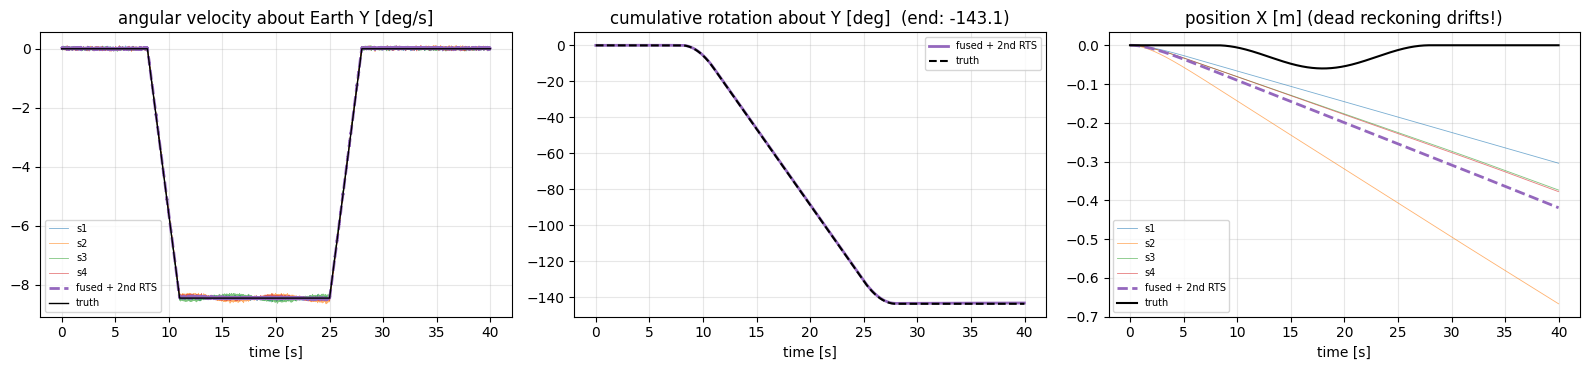

In [65]:
Yoff = res["R0"] @ truth["R"][0].T                       # constant heading offset between our Earth frame and the simulation's
aE_true = truth["aE"] @ Yoff.T                           # the true acceleration in the pipeline's Earth axes
wE_true = truth["wE"] @ Yoff.T                           # the true rotation rate
pE_true = truth["pE"] @ Yoff.T                           # the true position
t = res["t"]
rms = lambda e: float(np.sqrt(np.mean(np.sum(e ** 2, axis=1) / 3)))

print("RMS error of the rotation rate [deg/s]")
for s in ("s1", "s2", "s3", "s4"):
    print(f"   single IMU {s}      : {np.rad2deg(rms(res[f'{s}_wE'] - wE_true)):.4f}")
print(f"   FUSED               : {np.rad2deg(rms(res['w_fused'] - wE_true)):.4f}")
print(f"   FUSED + 2nd RTS     : {np.rad2deg(rms(res['w_fused_rts'] - wE_true)):.4f}")
print("\nRMS error of the acceleration [m/s^2]")
for s in ("s1", "s2", "s3", "s4"):
    print(f"   single IMU {s}      : {rms(res[f'{s}_aE'] - aE_true):.5f}")
print(f"   FUSED               : {rms(res['a_fused'] - aE_true):.5f}")
print(f"   FUSED + 2nd RTS     : {rms(res['a_fused_rts'] - aE_true):.5f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for s in ("s1", "s2", "s3", "s4"):
    ax[0].plot(t, np.rad2deg(res[f"{s}_wE"][:, 1]), lw=0.6, alpha=0.6, label=s)
ax[0].plot(t, np.rad2deg(res["w_fused_rts"][:, 1]), "tab:purple", ls="--", lw=2, label="fused + 2nd RTS")
ax[0].plot(t, np.rad2deg(wE_true[:, 1]), "k", lw=1, label="truth"); ax[0].set_title("angular velocity about Earth Y [deg/s]"); ax[0].legend(fontsize=7)
cum = lambda w: np.rad2deg(np.cumsum(w[:, 1]) * truth["dt"])
ax[1].plot(t, cum(res["w_fused_rts"]), "tab:purple", lw=2, label="fused + 2nd RTS"); ax[1].plot(t, cum(wE_true), "k--", label="truth")
ax[1].set_title(f"cumulative rotation about Y [deg]  (end: {cum(res['w_fused_rts'])[-1]:.1f})"); ax[1].legend(fontsize=7)
for s in ("s1", "s2", "s3", "s4"):
    ax[2].plot(t, res[f"{s}_p"][:, 0], lw=0.6, alpha=0.6, label=s)
ax[2].plot(t, res["p_fused_rts"][:, 0], "tab:purple", ls="--", lw=2, label="fused + 2nd RTS"); ax[2].plot(t, pE_true[:, 0], "k", label="truth")
ax[2].set_title("position X [m] (dead reckoning drifts!)"); ax[2].legend(fontsize=7)
for a in ax: a.grid(alpha=0.3); a.set_xlabel("time [s]")
plt.tight_layout(); plt.show()

### Look at the files the pipeline wrote
These are the pictures the real run produces (here for the simulation).

['filter_diagnostic.csv', 'gifs', 'results.npz', 'summary.csv'] + 18 PNG pictures
w.png


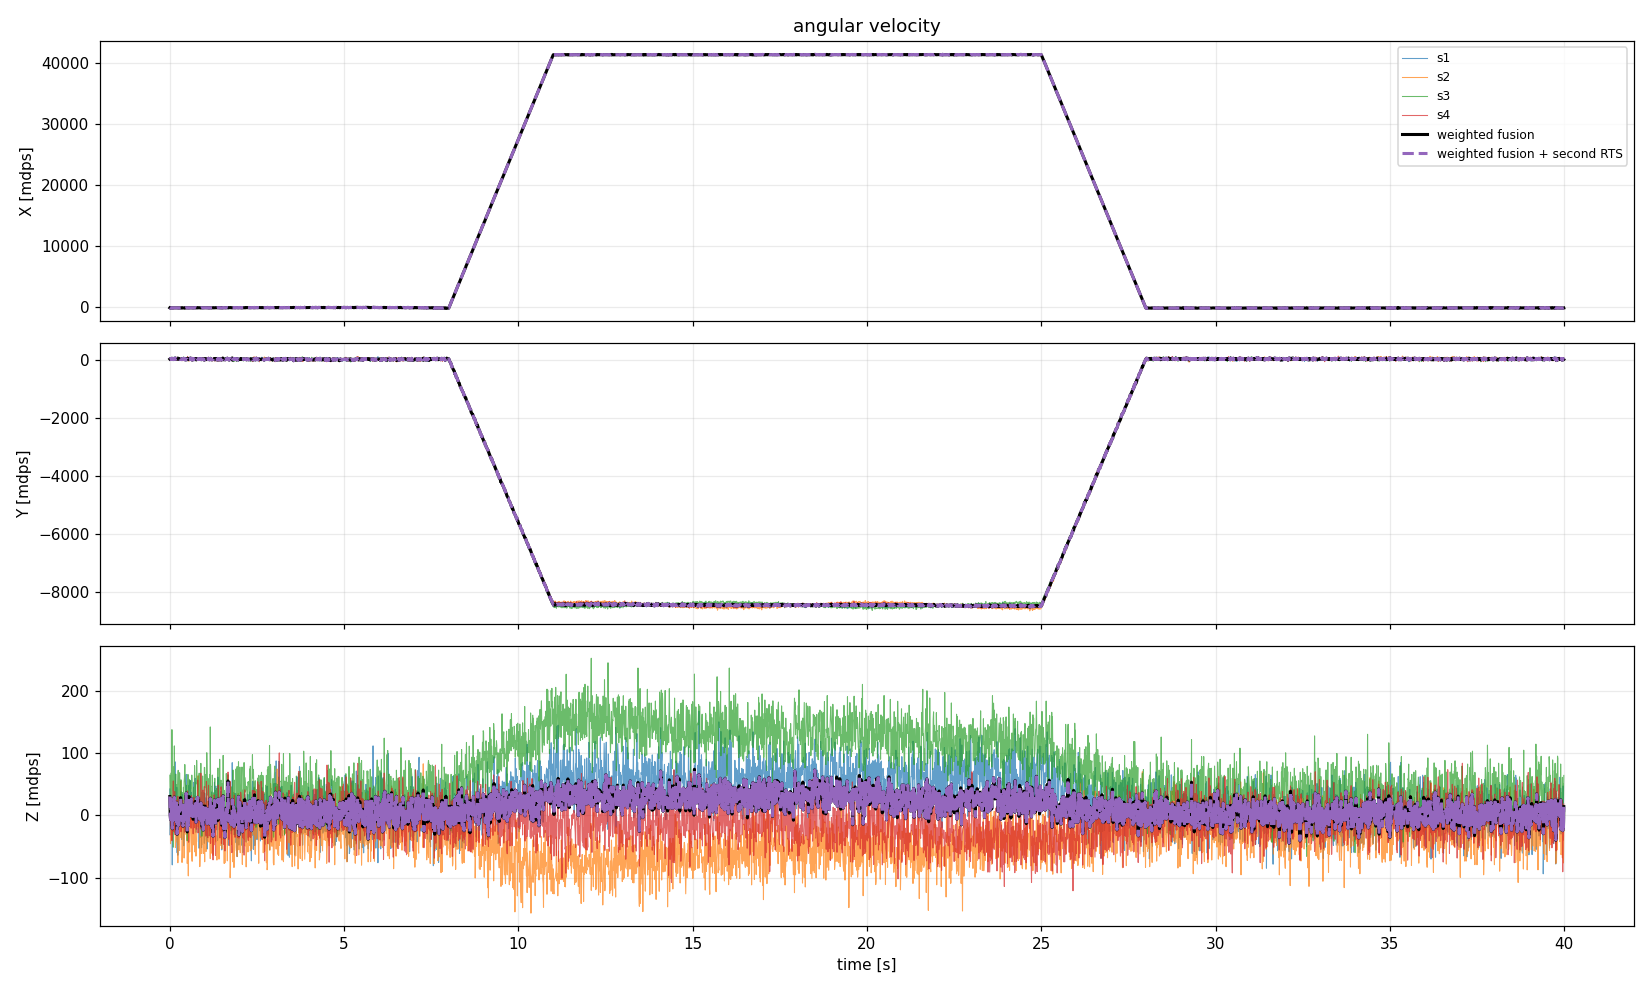

p.png


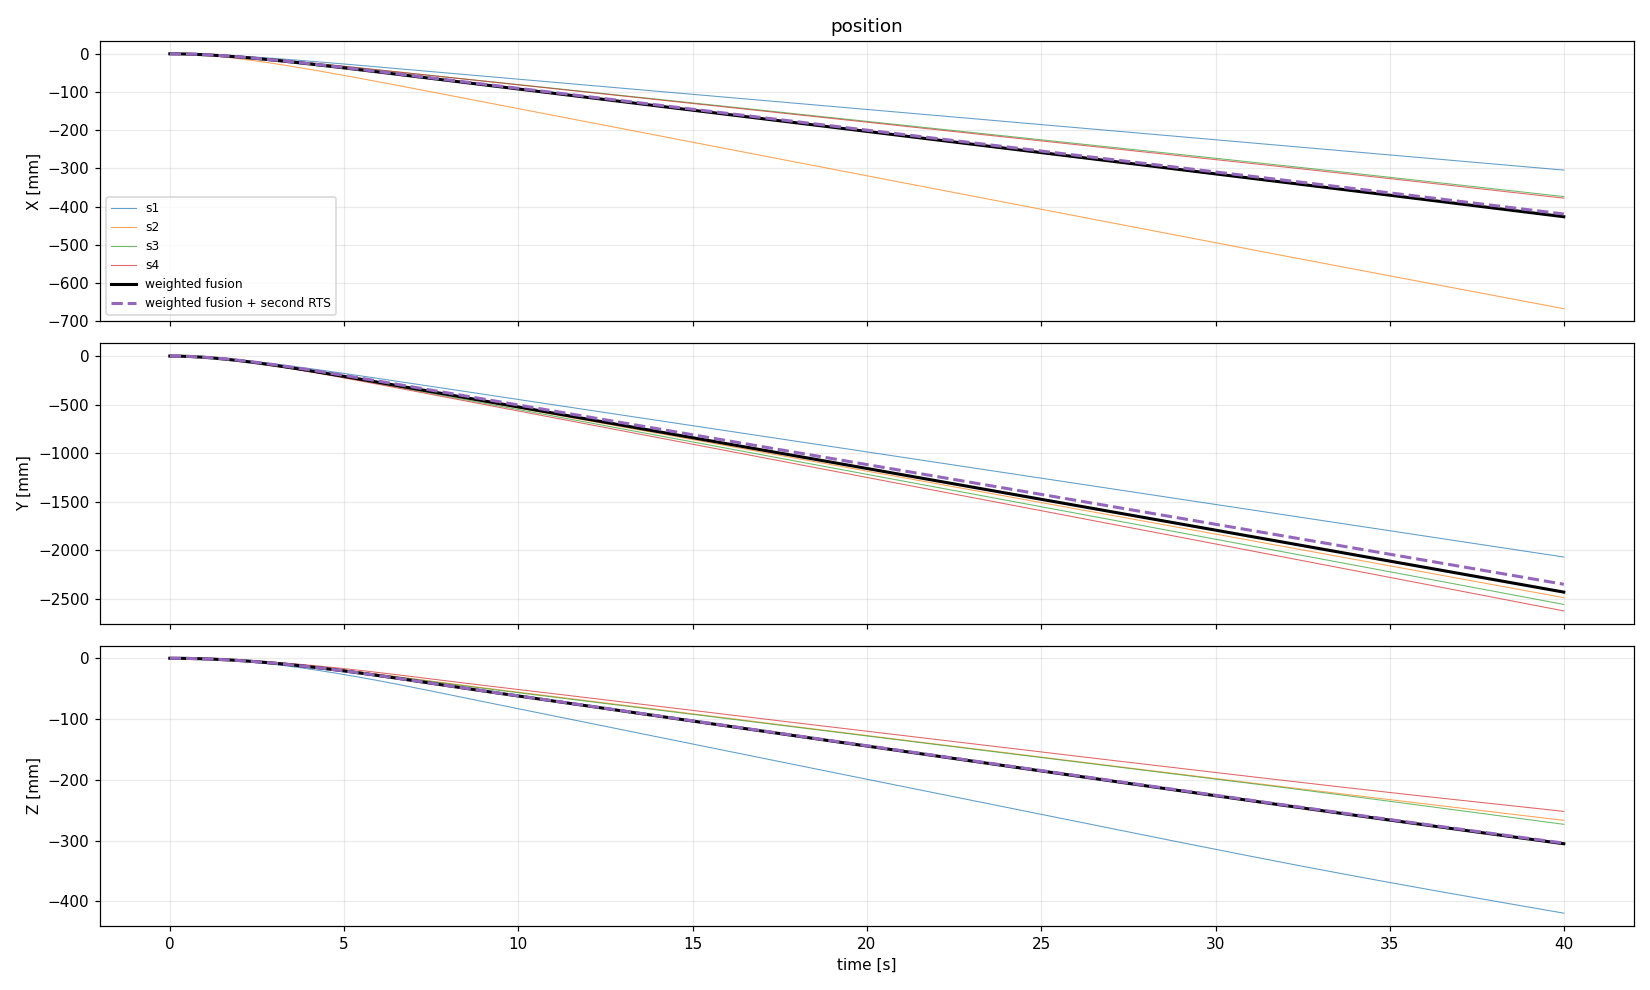

g_norm.png


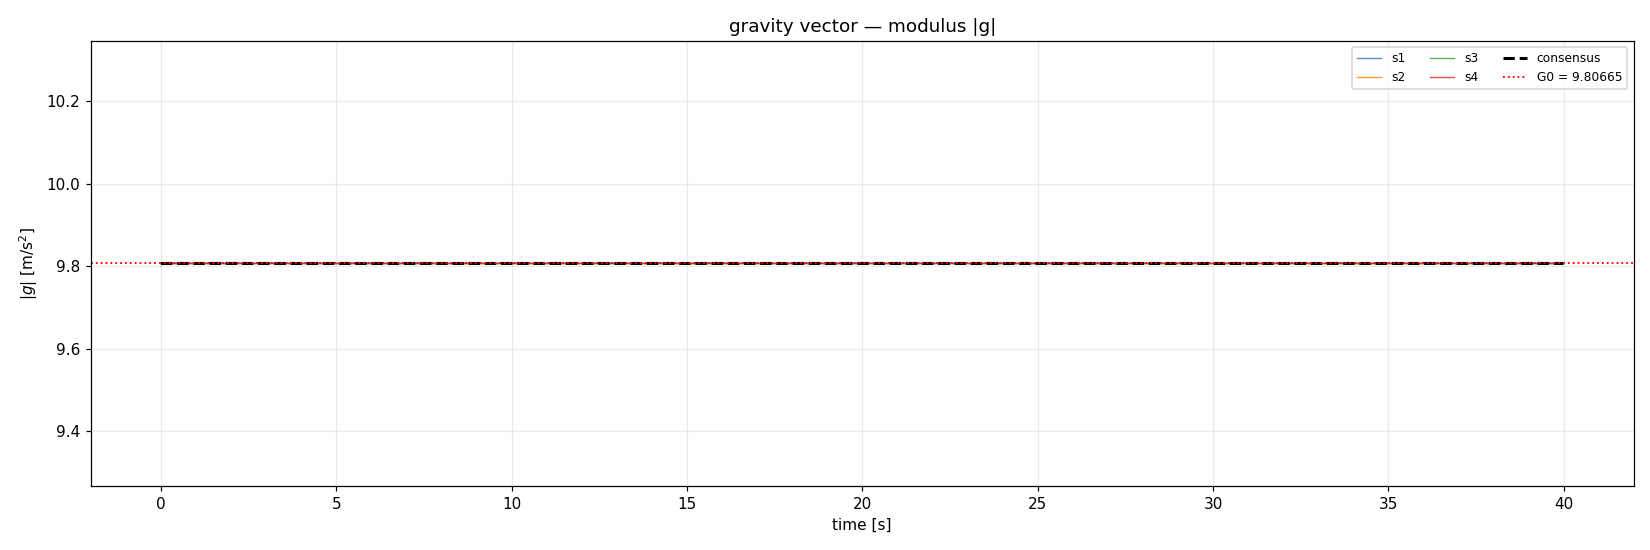

In [66]:
out_dir = sim_out / "simulated_720deg"
print(sorted(p.name for p in out_dir.iterdir() if p.suffix != ".png"), "+", len([p for p in out_dir.iterdir() if p.suffix == ".png"]), "PNG pictures")
for name in ("w.png", "p.png", "g_norm.png"):
    print(name); display(Image(filename=str(out_dir / name), width=900))

### The animated GIF
Left: the trajectory with the plate (colour = single IMU, dashed/black outline = fused). Top right: the rotation alone. Bottom right: position and cumulative rotation
(note the 720° plateau). *(This notebook uses few frames so it stays light; the project writes 220.)*

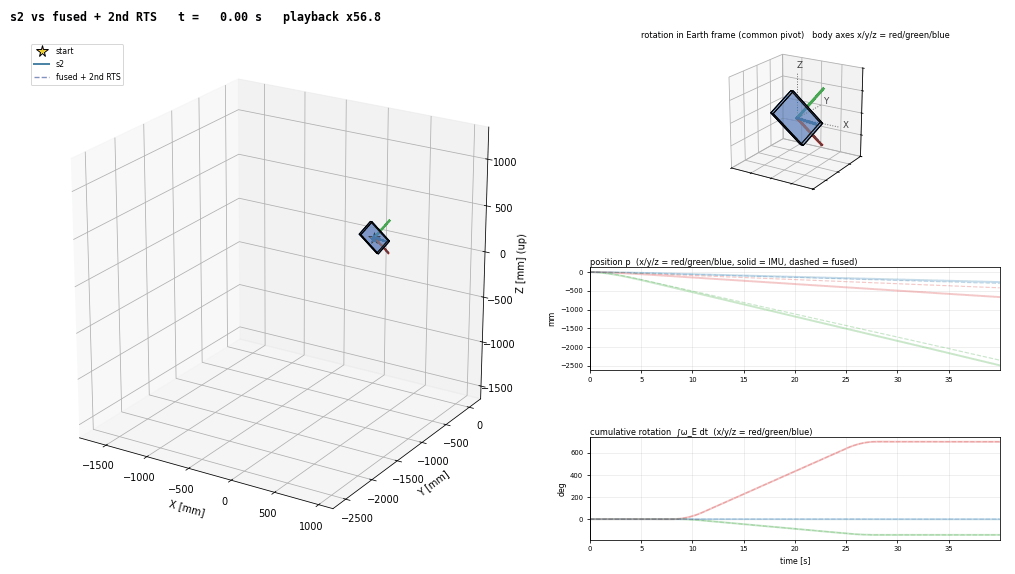

In [67]:
display(Image(filename=str(out_dir / "gifs" / "dynamics_s2_vs_fused.gif")))

### 🔑 What we learn
* The registration recovers the unknown mountings to about 0.1°. Note that the program's *reported* 1-σ (about 0.001°) is roughly a hundred times smaller than this actual error: the covariances come from a filter that does not know about its own modelling errors, so **reported uncertainties are optimistic**. Use them as relative indicators, not as absolute truth.
* **Fusion does not beat the best single IMU here.** In the printout above the fused rotation-rate error (about 0.06°/s) is close to the *typical* single IMU and slightly worse than the best one (s1). Fusion averages away *independent* noise, but most of the remaining error is **systematic and shared by all sensors** (the model lag / bias absorption of Chapter 5, plus registration errors of about 0.1°), and averaging cannot remove a common error. The accelerations tell the same story (all about 0.0077 m/s²). The practical value of fusion is robustness: it stays close to the typical sensor and protects against one bad sensor. The second smoother changes the error only marginally here.
* The cumulative rotation reaches ≈ 720° smoothly (the fused rotation rate keeps its plateau).
* **Position** is the weakest result. Two integrations amplify any small leftover error (Chapter 9), so
  dead-reckoned position drifts. This is a physical limit of inertial sensing, not a bug.

# Chapter 15 — Running it on your real CSV

The cell below uses the **same functions** on your file. Edit the three settings, then run it. It is skipped automatically if the file is not found.

* `REAL_CSV` — path to your CSV (put it in a folder named `DATA` next to the notebook, or write the full path).
* `DT_REAL` — the true time between rows [s]. **Check it with the diagnostic of Chapter 11**; if you normally run the script with a `config.DT`, use that value (`get_dt(None)`).
* `ALIGN_S_REAL` — seconds of **still** sensor at the start of the file. It must be shorter than the real still time; in this file the motion starts about 6–7 s after the start when `dt = 2.122 ms`.

In [68]:
REAL_CSV = Path("DATA/20260723_Dinamic_720degree_facex_1.csv")      # <-- edit: path of your CSV
DT_REAL = 0.002122                                                  # <-- edit: seconds between rows (see the diagnostic below)
ALIGN_S_REAL = 3.0                                                  # <-- edit: seconds of still sensor at the start

if REAL_CSV.exists():
    d_real, sens_real, n_real = load_csv(REAL_CSV)
    print(f"{REAL_CSV.name}: {n_real} rows, sensors {sens_real}")
    print("acceleration magnitude at rest [m/s^2] (should be ~9.8):",
          round(float(np.linalg.norm(d_real[sens_real[0]][0][:200].mean(0))), 3))
    dt_sug, fac = suggest_dt(*d_real[sens_real[0]], dt_assumed=DT_REAL)
    print(f"dt consistency check at DT_REAL = {DT_REAL}: factor = {fac:.3f}  (close to 1 = consistent)")
    print(f"for comparison, what 1/104 s would give: suggested dt = {suggest_dt(*d_real[sens_real[0]], dt_assumed=1/104)[0]:.6f} s")
else:
    print("real CSV not found:", REAL_CSV.resolve(), "-> section skipped (the simulation above already ran the whole pipeline)")

20260723_Dinamic_720degree_facex_1.csv: 24462 rows, sensors ['s1', 's2', 's3', 's4']
acceleration magnitude at rest [m/s^2] (should be ~9.8): 9.658
dt consistency check at DT_REAL = 0.002122: factor = 1.026  (close to 1 = consistent)
for comparison, what 1/104 s would give: suggested dt = 0.002246 s


In [69]:
if REAL_CSV.exists():
    real_out = Path("outputs_notebook_real")
    summary_real = process_file(
        path=REAL_CSV, out_root=real_out, dt=DT_REAL, align_s=ALIGN_S_REAL,
        second_rts=SECOND_RTS_DEFAULT, r_inflation=SECOND_RTS_R_INFLATION, q_scale=SECOND_RTS_Q_SCALE,
        registration_stride=REGISTRATION_STRIDE, active_thr_dps=REGISTRATION_MIN_ACTIVE_DPS,
        nmax=None, registration_refine_iters=2)
    print(); print(pd.Series(summary_real).to_string())


=== 20260723_Dinamic_720degree_facex_1.csv: 24462 samples, 4 IMUs (s1, s2, s3, s4) ===


  finished AEKF+RTS s1


  finished AEKF+RTS s2


  finished AEKF+RTS s3


  finished AEKF+RTS s4


...

  saved dynamics_s2_vs_fused.gif


  saved dynamics_s3_vs_fused.gif


  saved dynamics_s4_vs_fused.gif


  saved outputs_notebook_real/20260723_Dinamic_720degree_facex_1



file                        20260723_Dinamic_720degree_facex_1.csv
n_samples                                                    24462
n_imus                                                           4
dt_s                                                      0.002122
duration_s                                               51.906242
fused_a_rms_mps2                                          0.010338
fused_w_rms_dps                                          16.608289
fused_v_end_mmps                                        123.406814
fused_p_end_mm                                         6206.109306
fused_theta_end_mdeg                                   1704.028615
second_rts                                                    True
fused_rts_a_rms_mps2                                      0.010266
fused_rts_w_rms_dps                                      16.608286
fused_rts_v_end_mmps                                    122.859774
fused_rts_p_end_mm                                     6177.5

integrated rotation (sum of w dt) [deg], Earth X,Y,Z: [ 44.6 720.3   7.3]
w.png


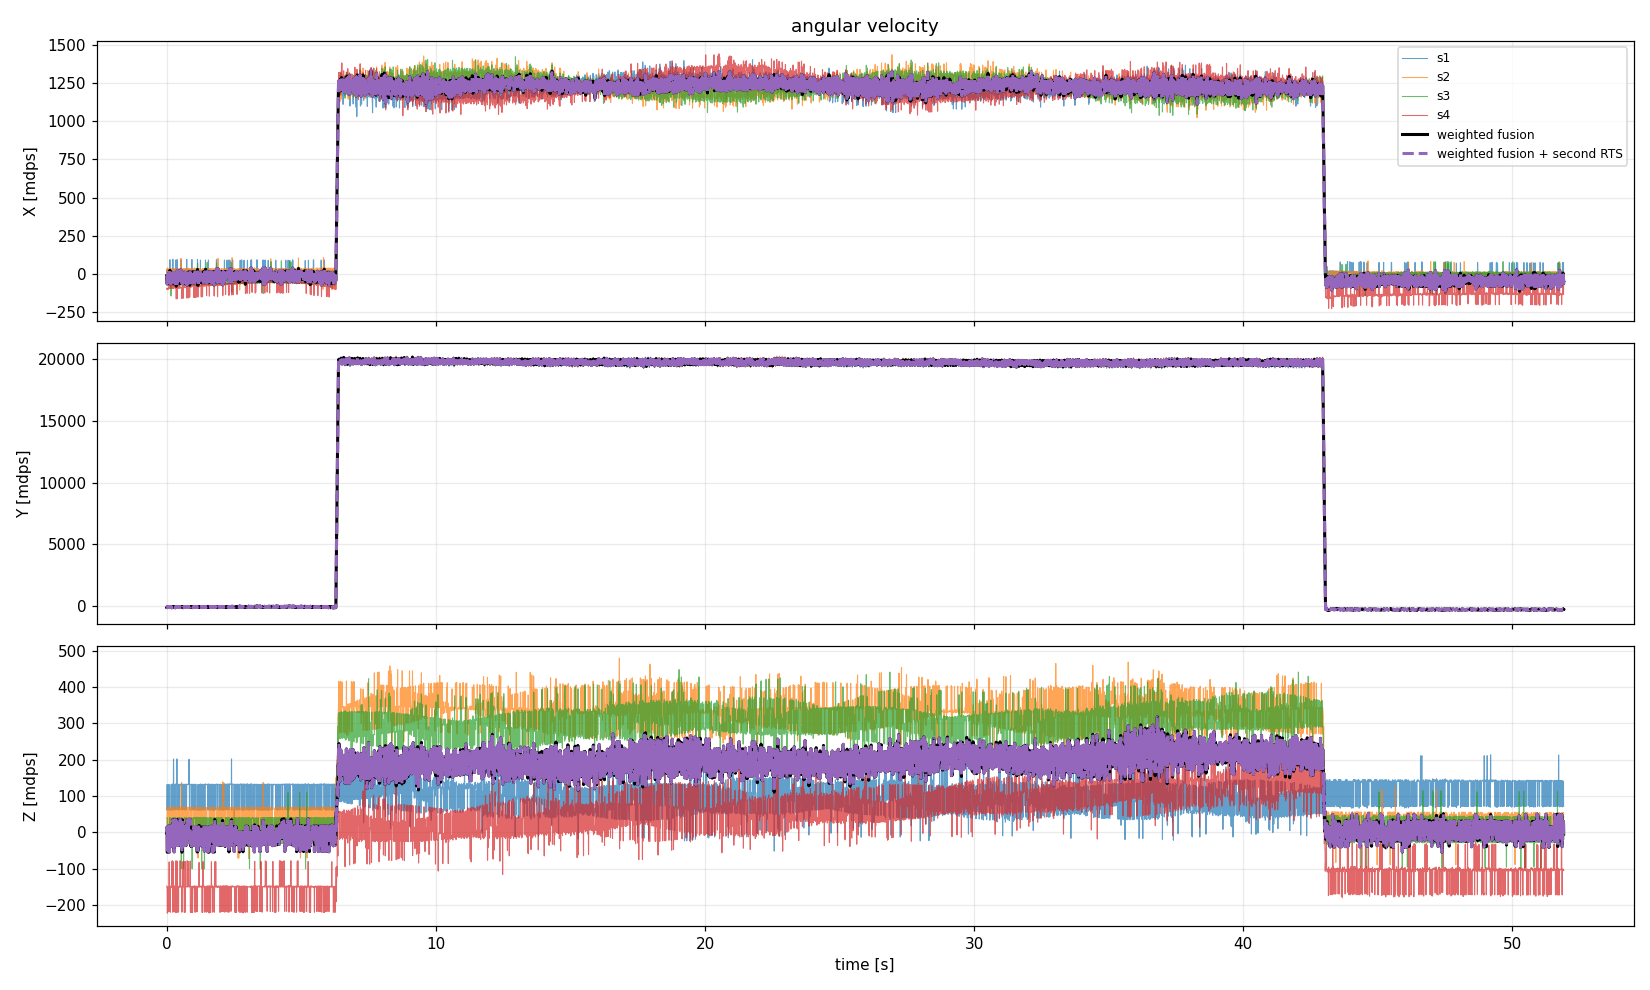

theta.png


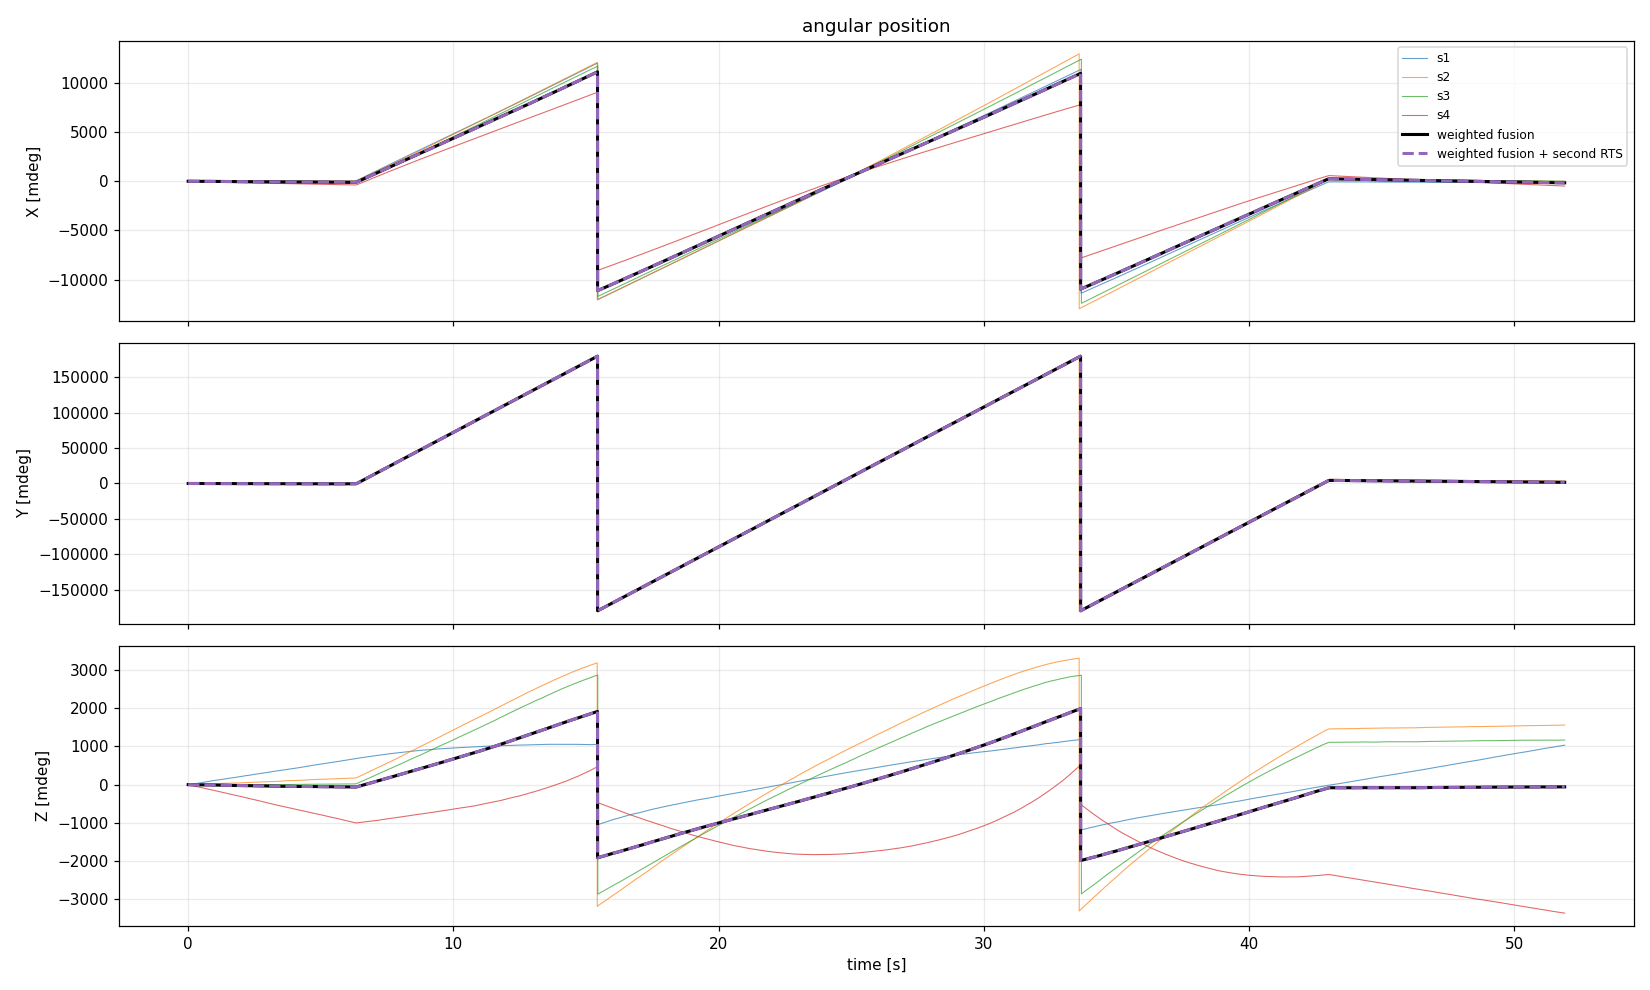

g_norm.png


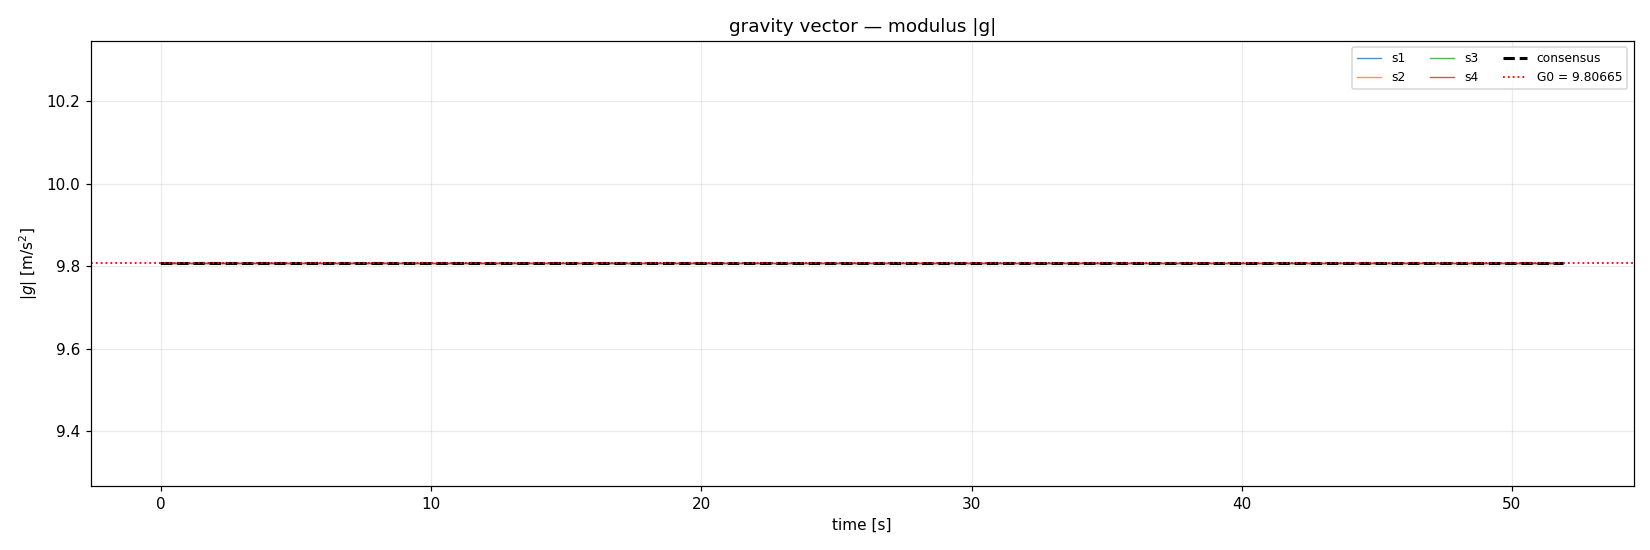

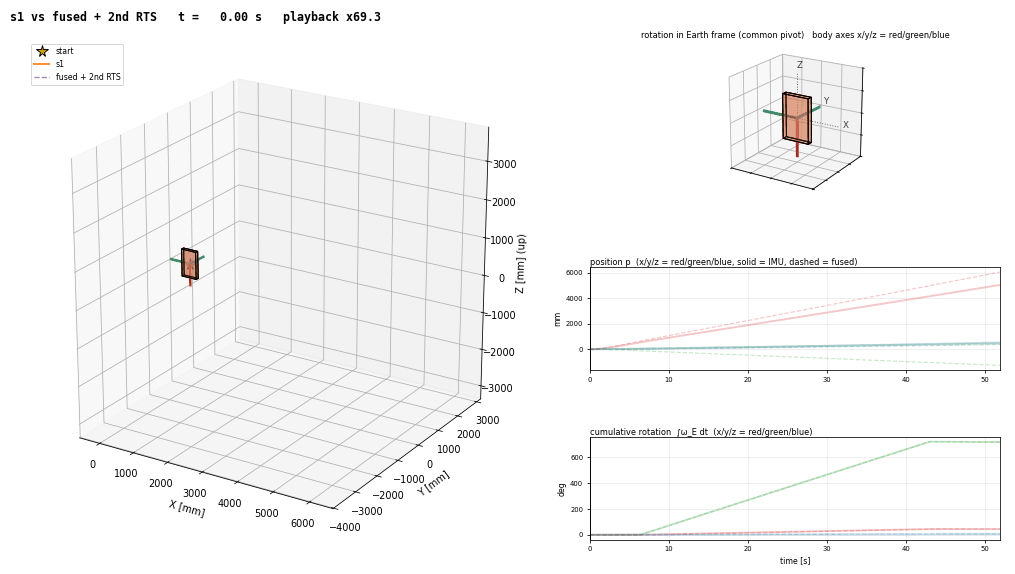

In [70]:
if REAL_CSV.exists():
    rdir = real_out / REAL_CSV.stem
    rr = np.load(rdir / "results.npz", allow_pickle=True)
    wf = np.rad2deg(rr["w_fused_rts"]); tr = rr["t"]
    print("integrated rotation (sum of w dt) [deg], Earth X,Y,Z:", (wf.sum(0) * tr[1]).round(1))
    for name in ("w.png", "theta.png", "g_norm.png"):
        print(name); display(Image(filename=str(rdir / name), width=900))
    display(Image(filename=str(rdir / "gifs" / "dynamics_s1_vs_fused.gif")))

### Running from the command line instead
Everything above is what the script does when you type
```
python run_general_multisensor_dynamic.py
```
(inputs from the `DATA` folder next to the script, outputs to `outputs_general_dynamic`; options: `--dt`, `--align-s`, `--no-second-rts`, ...).
The command-line wrapper `main()` is shown below for completeness; it only reads the options and calls `process_file` for every CSV found.

In [71]:
def main():
    # Describe the command-line options (each `add_argument` below is one option with a default value).
    ap = argparse.ArgumentParser(description="General arbitrary-N IMU dynamic multisensor pipeline")
    ap.add_argument("--data-dir", default=None, help="Input folder; default is DATA next to this script")
    ap.add_argument("--output-dir", default=None, help="Output folder; default outputs_general_dynamic next to this script")
    ap.add_argument("--pattern", default="*.csv", help="CSV glob pattern inside DATA")
    ap.add_argument("--files", nargs="*", default=None, help="Optional exact filenames relative to DATA")
    ap.add_argument("--dt", type=float, default=None, help="Sample period [s]; default config.DT, else 1/104")
    ap.add_argument("--align-s", type=float, default=DEFAULT_ALIGN_S, help="Initial stationary interval [s]")
    ap.add_argument("--nmax", type=int, default=None)
    ap.add_argument("--no-second-rts", action="store_true", help="Disable the post-fusion 6-state RTS")
    ap.add_argument("--r-inflation", type=float, default=SECOND_RTS_R_INFLATION)
    ap.add_argument("--q-scale", type=float, default=SECOND_RTS_Q_SCALE)
    ap.add_argument("--registration-stride", type=int, default=REGISTRATION_STRIDE)
    ap.add_argument("--active-threshold-dps", type=float, default=REGISTRATION_MIN_ACTIVE_DPS,
                    help="diagnostic activity mask only; registration is covariance-weighted")
    ap.add_argument("--registration-refine-iters", type=int, default=2,
                    help="leave-one-out Gauss-Seidel refinement sweeps (N>=3)")
    # Read what the user typed.
    args = ap.parse_args()

    # Folders: DATA for the input, outputs_general_dynamic for the results.
    root = Path(__file__).resolve().parent
    data_dir = Path(args.data_dir) if args.data_dir else root / "DATA"
    out_dir = Path(args.output_dir) if args.output_dir else root / "outputs_general_dynamic"
    out_dir.mkdir(parents=True, exist_ok=True)
    # Stop with a clear message if the input folder is missing.
    if not data_dir.exists():
        raise FileNotFoundError(f"DATA folder does not exist: {data_dir}")

    # Which CSV files to process: the ones named, or all *.csv in DATA.
    if args.files:
        paths = [data_dir / f for f in args.files]
    else:
        paths = sorted(data_dir.glob(args.pattern))
    paths = [p for p in paths if p.suffix.lower() == ".csv"]
    if not paths:
        raise FileNotFoundError(f"No CSV files found in {data_dir} matching {args.pattern!r}")

    # Sample period (option, else config.DT, else 1/104 s).
    dt = get_dt(args.dt)
    summaries = []
    # Run the whole pipeline on every file.
    for path in paths:
        summaries.append(process_file(
            path=path,
            out_root=out_dir,
            dt=dt,
            align_s=args.align_s,
            second_rts=not args.no_second_rts,
            r_inflation=args.r_inflation,
            q_scale=args.q_scale,
            registration_stride=args.registration_stride,
            active_thr_dps=args.active_threshold_dps,
            nmax=args.nmax,
            registration_refine_iters=args.registration_refine_iters,
        ))
    # Write one summary table for the whole batch.
    pd.DataFrame(summaries).to_csv(out_dir / "batch_summary.csv", index=False)
    print(f"\nProcessed {len(summaries)} CSV file(s). Batch summary: {out_dir / 'batch_summary.csv'}", flush=True)

# Chapter 16 — Reading the results, and a troubleshooting guide

### Files written for every input CSV
| File | What it is |
|---|---|
| `a.png`, `w.png`, `v.png`, `p.png`, `theta.png` | acceleration, rotation rate, velocity, position, angle in the **Earth frame**: one thin line per IMU, black = weighted fusion, dashed purple = + second RTS |
| `*_fusion_compare.png` | only the two fused curves, to judge the second smoother |
| `p_norm.png`, `theta_norm.png` (+ `..._fusion_compare.png`) | distance from the start and total rotation (lengths of the vectors) |
| `ba.png`, `bw.png`, `g.png` | biases and gravity of each IMU (diagnostics; not fused) |
| `g_norm.png` | history of $\|\mathbf g\|$: flat at $G_0$ |
| `gifs/dynamics_sN_vs_fused.gif` | animation of IMU N versus the fused result |
| `results.npz` | all main arrays (Earth-frame states, covariances, registrations, fused results) |
| `filter_diagnostic.csv`, `summary.csv` | quick numbers: raw vs estimated rate, registration uncertainty, final position/angle |

### Troubleshooting
| Symptom | Likely cause | What to check |
|---|---|---|
| Rotation rate decays instead of staying flat, biases huge | acceleration read in the wrong unit, or priors that let the filter explain rotation as bias | acceleration magnitude at rest ≈ 9.8 m/s²? (Chapter 11); use `make_cfg` safeguards (Chapter 5) |
| Total rotation is not what you expect (e.g. 3300° instead of 720°) | wrong `dt` | the consistency diagnostic of Chapter 11 |
| Estimates look strange right from the start | `align_s` longer than the still period | reduce `align_s` |
| Warning about registration "weakest direction" | motion did not excite one direction (e.g. a turn about the vertical was never seen) | add rotations about several axes, or accept larger uncertainty |
| Position drifts by metres | normal: double integration of small errors | Chapter 1 and 9; compare IMUs, not absolute values |
| GIF very slow to produce | many frames and plots | reduce `MAX_FRAMES` (notebook) or the 220 frames in `imu_gifs.py` |

### Assumptions to keep in mind
* All sensors are **synchronised** (same row = same instant) and rigidly attached with **constant** relative orientation.
* They measure the **same angular velocity**. Translational accelerations are fused assuming the sensors are (nearly) at the same point; with a significant lever arm
  $\mathbf r_i$ the accelerations differ by $\boldsymbol\alpha\times\mathbf r_i+\boldsymbol\omega\times(\boldsymbol\omega\times\mathbf r_i)$ and must be corrected first.
* **Yaw at the start is a convention (0)**: gravity cannot tell the compass heading.
* The second smoother is a practical temporal regulariser, not an exact Bayesian smoother.
* Biases absorb model imperfections; do not over-interpret their individual values (Chapter 5).
* Reported covariances and 1-σ values are optimistic: they ignore systematic model errors (Chapter 14).

# Appendix A — Glossary

| Term | Meaning |
|---|---|
| **Accelerometer** | measures the push of the support: true acceleration minus gravity (plus bias and noise) |
| **Adaptive filter** | a filter that re-tunes its own noise settings from the size of its recent surprises |
| **Bias** | slowly-varying constant error of a sensor |
| **Body frame** | axes attached to the sensor/object |
| **Covariance (matrix)** | table of variances (diagonal) and linked uncertainties (off-diagonal) |
| **Earth (inertial) frame** | fixed axes: X, Y horizontal, Z up |
| **EKF** | Extended Kalman Filter: Kalman filter for non-linear models (uses tangent lines) |
| **Gauss–Markov process** | a quantity that fades toward zero with a time constant τ and is kicked by random noise |
| **Gauss–Newton** | iterative method to minimise a sum of squared residuals by repeated linearisation |
| **Gyroscope** | measures angular velocity (plus bias and noise) |
| **Information (precision) matrix** | inverse of the covariance; larger means more certain |
| **Innovation** | measurement minus prediction ("surprise") |
| **Joseph form** | numerically safe formula for the covariance update |
| **Kalman gain** | how strongly a measurement corrects the prediction |
| **Process noise Q** | how much the state is allowed to wander between samples |
| **Measurement noise R** | noise of the sensors |
| **Pseudo-measurement** | a known fact (here $\|\mathbf g\|=G_0$) treated as a measurement |
| **Registration** | finding the fixed rotation between two sensors' axes |
| **Rotation matrix** | 3×3 table that converts vectors between frames; its inverse is its transpose |
| **Rotation vector** | axis × angle description of a rotation; matrix = `Exp` of its skew matrix |
| **RTS smoother** | backward pass (Rauch–Tung–Striebel) that refines filter results using future data |
| **Skew matrix** | the matrix $[\mathbf v]_\times$ with $[\mathbf v]_\times\mathbf u=\mathbf v\times\mathbf u$ |
| **SVD** | singular value decomposition: matrix factorisation used to solve Wahba's problem |
| **Wahba problem** | find the rotation that best aligns two sets of vectors |
| **Yaw / pitch / roll** | rotations about vertical, lateral and longitudinal axes (heading, nose-up, bank) |

# Appendix B — Helpers that exist in the files but are not used by the current pipeline
For completeness the remaining functions of the project files are shown (with comments). `convert_legacy_cfg` adapted settings of an older 28-state
filter before `make_cfg` was written directly for the 15 states; `earth_state_covariance` is the single-IMU counterpart of `project_earth_with_cov`.

In [72]:
def _as_vec(v, n, name):
    # Check that a settings vector has the expected length and return a copy.
    a = np.asarray(v, float)
    if a.shape != (n,):
        raise ValueError(f"{name} must have shape ({n},), got {a.shape}")
    return a.copy()

In [73]:
def convert_legacy_cfg(cfg0) -> AEKFConfig:
    """Accept either the new 15-state AEKFConfig or the previous 28-state cfg."""
    # LEGACY (unused now): converts the settings of an older 28-state filter [p v a th w q ba bw g]
    # to the 15 states [a w ba bw g] kept by the current filter.
    if isinstance(cfg0, AEKFConfig):
        return AEKFConfig(
            dt=float(cfg0.dt), G0=float(getattr(cfg0, "G0", G0)),
            tau_a=float(cfg0.tau_a), tau_w=float(cfg0.tau_w),
            P0_std=_as_vec(cfg0.P0_std, 15, "P0_std"),
            Q0_std=_as_vec(cfg0.Q0_std, 15, "Q0_std"),
            R0_std=_as_vec(cfg0.R0_std, 6, "R0_std"),
            sigma_gnorm=float(getattr(cfg0, "sigma_gnorm", 0.05)),
            enable_adaptive=bool(getattr(cfg0, "enable_adaptive", True)),
            window=int(getattr(cfg0, "window", 100)),
            b=float(getattr(cfg0, "b", 0.98)),
            min_eig_floor=float(getattr(cfg0, "min_eig_floor", EIG_FLOOR)),
            Q_min_std=None if getattr(cfg0, "Q_min_std", None) is None else _as_vec(cfg0.Q_min_std, 15, "Q_min_std"),
            R_min_std=None if getattr(cfg0, "R_min_std", None) is None else _as_vec(cfg0.R_min_std, 6, "R_min_std"),
            adapt_gyro_R=bool(getattr(cfg0, "adapt_gyro_R", False)),
            adapt_bias_process=bool(getattr(cfg0, "adapt_bias_process", False)),
            min_w_jump_std=float(getattr(cfg0, "min_w_jump_std", 0.0)),
            max_w_jump_std=getattr(cfg0, "max_w_jump_std", None),
        )

    p = np.asarray(cfg0.P0_std, float)
    q = np.asarray(cfg0.Q0_std, float)
    qmin = np.asarray(getattr(cfg0, "Q_min_std", np.zeros_like(q)), float)
    r0 = np.asarray(cfg0.R0_std, float)
    rmin = np.asarray(getattr(cfg0, "R_min_std", np.zeros(6)), float)

    if p.shape == (15,) and q.shape == (15,):
        return AEKFConfig(
            dt=float(cfg0.dt), G0=float(getattr(cfg0, "G0", G0)),
            tau_a=float(getattr(cfg0, "tau_a", 2.0)), tau_w=float(getattr(cfg0, "tau_w", 2.0)),
            P0_std=p.copy(), Q0_std=q.copy(), R0_std=r0.copy(),
            sigma_gnorm=0.05,
            enable_adaptive=bool(getattr(cfg0, "enable_adaptive", True)),
            window=int(getattr(cfg0, "window", 100)),
            b=float(getattr(cfg0, "b", 0.98)),
            min_eig_floor=float(getattr(cfg0, "min_eig_floor", EIG_FLOOR)),
            Q_min_std=qmin.copy(), R_min_std=rmin.copy(),
            adapt_gyro_R=False, adapt_bias_process=False,
        )

    if p.shape != (28,) or q.shape != (28,):
        raise ValueError("Noise configuration must contain 15-state or 28-state vectors")

    KEEP28 = np.r_[6:9, 12:15, 19:28]
    return AEKFConfig(
        dt=float(cfg0.dt), G0=float(getattr(cfg0, "G0", G0)),
        tau_a=float(getattr(cfg0, "tau_a", 2.0)), tau_w=float(getattr(cfg0, "tau_w", 2.0)),
        P0_std=p[KEEP28].copy(), Q0_std=q[KEEP28].copy(), R0_std=r0.copy(),
        sigma_gnorm=0.05,
        enable_adaptive=bool(getattr(cfg0, "enable_adaptive", True)),
        window=int(getattr(cfg0, "window", 100)),
        b=float(getattr(cfg0, "b", 0.98)),
        min_eig_floor=float(getattr(cfg0, "min_eig_floor", EIG_FLOOR)),
        Q_min_std=qmin[KEEP28].copy(), R_min_std=rmin.copy(),
        adapt_gyro_R=False, adapt_bias_process=False,
    )

In [74]:
def earth_state_covariance(
    xs: np.ndarray,
    Ps: np.ndarray,
    R: np.ndarray,
) -> Tuple[np.ndarray, np.ndarray]:
    """Transform [a_B, w_B, g_B] and their covariance into Earth frame.

    Returns:
        Y  : (N,9), concatenated [a_E, w_E, g_E_est]
        PY : (N,9,9), full covariance of those 9 quantities
    """
    # Single-IMU helper (unused by the multi-sensor pipeline): rotates [a, w, g] and their covariance into the Earth frame.
    xs = np.asarray(xs, float)
    Ps = np.asarray(Ps, float)
    R = np.asarray(R, float)

    if xs.ndim != 2 or xs.shape[1] != N_X:
        raise ValueError("xs must have shape (N,15)")
    if Ps.shape != (len(xs), N_X, N_X):
        raise ValueError("Ps must have shape (N,15,15)")
    if R.shape != (len(xs), 3, 3):
        raise ValueError("R must have shape (N,3,3)")

    Y = np.empty((len(xs), 9))
    PY = np.empty((len(xs), 9, 9))

    J = np.zeros((9, N_X))
    for k in range(len(xs)):
        Rk = R[k]
        Y[k] = np.concatenate([
            Rk @ xs[k, SL["a"]],
            Rk @ xs[k, SL["w"]],
            Rk @ xs[k, SL["g"]],
        ])
        J.fill(0.0)
        J[0:3, SL["a"]] = Rk
        J[3:6, SL["w"]] = Rk
        J[6:9, SL["g"]] = Rk
        PY[k] = J @ Ps[k] @ J.T

    return Y, PY

In [75]:
# KEEP28 / G constants used only by the legacy converter above (positions of a, w, ba, bw, g inside the old 28-vector)
KEEP28 = np.r_[6:9, 12:15, 19:28]
print("KEEP28 =", KEEP28)

KEEP28 = [ 6  7  8 12 13 14 19 20 21 22 23 24 25 26 27]
